# EDA — Vietnamese beauty product reviews

Notebook khảo sát dữ liệu cho **aspect detection (multi-label)** và **sentiment theo aspect**.
Mỗi ô aspect có một trong ba sentiment hoặc blank (aspect không được gán nhãn).
Blank không đồng nghĩa với `neutral` và cũng không chứng minh aspect không được nhắc đến trong văn bản.

**Phạm vi:** sanity check; split/leakage; text length; noise; aspect frequency;
cardinality; co-occurrence. Các bước chỉ phân tích, không sửa dữ liệu nguồn.
Thống kê train/val/test phục vụ audit; lựa chọn tiền xử lý và độ dài model dựa trên train.
Không dùng kết quả test để điều chỉnh model. Notebook chưa chạy tokenizer/model.

**Chạy:** Python 3 với `pandas`, `numpy`, `matplotlib`, `seaborn`, `IPython`.
Nếu thiếu thư viện, chạy `%pip install pandas numpy matplotlib seaborn` trong kernel đang dùng.
Chọn **Restart Kernel → Run All**. Đường dẫn tự nhận khi chạy từ repo root hoặc `src/`;
nếu chạy ở nơi khác, sửa `DATA_DIR` trong cell setup.

**Phần mở rộng (8–16):** sentiment imbalance, figure chính Aspect × Sentiment, length × labels, lexical exploration, qualitative audit, label quality, preprocessing/evaluation decisions và research hypotheses. Figure chính nằm ở mục 9.


**Evidence charts:** mục 17–23: neutral semantics, majority metric masking, rare-support resolution, lexical/mixed-sentiment cues, length confounding, noise by group, annotation/leakage và methodology protocol.

**EDA-04 — Targeted Data Audit:** phần cuối notebook bổ sung census core/global distribution, rare pair audit, toàn bộ OTHERS+core samples, duplicate/contamination coverage và giới hạn cập nhật.

In [1]:
from pathlib import Path
from collections import Counter
from itertools import combinations
import re
import unicodedata
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ASPECTS = ['stayingpower', 'texture', 'smell', 'price', 'others', 'colour', 'shipping', 'packing']
SENTIMENTS = ['positive', 'neutral', 'negative']
TEXT_COL = 'data'
SPLITS = ['train', 'val', 'test']
FILES = {'full': 'full_data.csv', 'train': 'data_train.csv',
         'val': 'data_val.csv', 'test': 'data_test.csv'}
DATA_DIR = next((p for p in [Path.cwd() / 'data', Path.cwd().parent / 'data']
                 if all((p / f).is_file() for f in FILES.values())), None)
if DATA_DIR is None:
    raise FileNotFoundError('Set DATA_DIR to the directory containing all four source CSV files.')
DATA_DIR = DATA_DIR.resolve()
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 120)
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (10, 4), 'figure.dpi': 110})

# Preserve blank and literal strings such as "NA"; do not silently clean labels.
datasets = {s: pd.read_csv(DATA_DIR / f, keep_default_na=False, dtype=str)
            for s, f in FILES.items()}
inferred = {s: pd.read_csv(DATA_DIR / f) for s, f in FILES.items()}
for split, df in datasets.items():
    if set(df.columns) != {TEXT_COL, *ASPECTS}:
        raise ValueError(f'{split}: unexpected columns {list(df.columns)}')
    if list(df.columns) != [TEXT_COL, *ASPECTS]:
        print(f'Column order differs in {split}; name-based analysis will still work.')

provenance = pd.DataFrame([{
    'split': s, 'file': f, 'bytes': (DATA_DIR/f).stat().st_size,
    'sha256': hashlib.sha256((DATA_DIR/f).read_bytes()).hexdigest()
} for s, f in FILES.items()])
print('Data directory:', DATA_DIR)
print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| numpy:', np.__version__)
display(provenance)


Data directory: /Users/mac/Developers/personal/DL in Business Application/Aspect-based-Sentiment-Analysis-for-Vietnamese-Reviews-about-Beauty-Product-on-E-commerce-Websites/data
Python: 3.13.9 | pandas: 3.0.6 | numpy: 2.5.3


,split,file,bytes,sha256
0,full,full_data.csv,2482334,3bda8deecc84d94fff526ad092cadc1dc4a4487e6d1a8c54871e53da95ec780e
1,train,data_train.csv,1986582,19449cceea317269304464ef7c6c72d5dc70548c6006686d1506e1880bfb9976
2,val,data_val.csv,245841,7bbc93fad8db9c78a83f75800119cad65bf65b8f0241c36228d7cbe13d1535b3
3,test,data_test.csv,250049,90d1bf0b64105c89346f60d974c5c72c0208c70458c40d5b089ac48486d43d08


## 1. Dataset sanity check

`empty_review` = chuỗi rỗng chính xác; `whitespace_only_review` = không rỗng nhưng chỉ có whitespace.
`parser_null_review` dùng cách đọc mặc định của pandas, bao gồm blank và các NA token mà pandas nhận diện;
CSV không có kiểu null riêng nên không cộng chỉ số này với empty để tránh đếm hai lần.
`duplicate_rows_extra` đếm số dòng dư sau lần xuất hiện đầu tiên, gồm review và toàn bộ nhãn.


In [2]:
summary = pd.DataFrame([{
    'split': s, 'rows': len(df), 'columns': df.shape[1],
    'empty_review': df[TEXT_COL].eq('').sum(),
    'whitespace_only_review': (df[TEXT_COL].ne('') & df[TEXT_COL].str.strip().eq('')).sum(),
    'parser_null_review': inferred[s][TEXT_COL].isna().sum(),
    'duplicate_rows_extra': df.duplicated().sum(),
    'duplicate_text_extra': df[TEXT_COL].duplicated().sum()
} for s, df in datasets.items()]).set_index('split')
display(summary)
display(pd.DataFrame({s: df.dtypes.astype(str) for s, df in inferred.items()}).rename_axis('column'))
print('Preserved-input dtypes:', datasets['full'].dtypes.astype(str).to_dict())
print('Columns:', list(datasets['full'].columns))
split_n = sum(len(datasets[s]) for s in SPLITS)
print(f'N_train + N_val + N_test = {split_n:,}; N_full = {len(datasets["full"]):,}; match = {split_n == len(datasets["full"])}')

# Row counts alone do not establish that full is the union of the three splits.
def row_counter(df):
    return Counter(df[[TEXT_COL, *ASPECTS]].itertuples(index=False, name=None))
full_rows = row_counter(datasets['full'])
split_rows = sum((row_counter(datasets[s]) for s in SPLITS), Counter())
union_check = pd.DataFrame([{
    'count_match': split_n == len(datasets['full']),
    'row_multiset_match': full_rows == split_rows,
    'rows_in_full_missing_from_splits': sum((full_rows - split_rows).values()),
    'rows_in_splits_missing_from_full': sum((split_rows - full_rows).values())
}])
display(union_check)


,rows,columns,empty_review,whitespace_only_review,parser_null_review,duplicate_rows_extra,duplicate_text_extra
split,,,,,,,
full,16227,9,0,0,0,251,257
train,12981,9,0,0,0,180,184
val,1623,9,0,0,0,18,22
test,1623,9,0,0,0,15,15


,full,train,val,test
column,,,,
data,str,str,str,str
stayingpower,str,str,str,str
texture,str,str,str,str
smell,str,str,str,str
price,str,str,str,str
others,str,str,str,str
colour,str,str,str,str
shipping,str,str,str,str
packing,str,str,str,str


Preserved-input dtypes: {'data': 'str', 'stayingpower': 'str', 'texture': 'str', 'smell': 'str', 'price': 'str', 'others': 'str', 'colour': 'str', 'shipping': 'str', 'packing': 'str'}
Columns: ['data', 'stayingpower', 'texture', 'smell', 'price', 'others', 'colour', 'shipping', 'packing']
N_train + N_val + N_test = 16,227; N_full = 16,227; match = True


,count_match,row_multiset_match,rows_in_full_missing_from_splits,rows_in_splits_missing_from_full
0,True,True,0,0


In [3]:
quality_rows, invalid_examples = [], []
for s, df in datasets.items():
    for a in ASPECTS:
        raw = df[a]
        invalid = ~raw.isin(['', *SENTIMENTS])
        quality_rows.append({'split': s, 'aspect': a, 'blank': raw.eq('').sum(),
                             'positive': raw.eq('positive').sum(), 'neutral': raw.eq('neutral').sum(),
                             'negative': raw.eq('negative').sum(), 'invalid': invalid.sum()})
        if invalid.any():
            e = df.loc[invalid, [TEXT_COL, a]].head(5).copy()
            e.insert(0, 'source_row_0based', e.index)
            e.insert(0, 'split', s)
            invalid_examples.append(e)
label_quality = pd.DataFrame(quality_rows)
display(label_quality)
invalid_total = int(label_quality['invalid'].sum())
print('Invalid label cells across files (full overlaps splits):', invalid_total)
for e in invalid_examples:
    display(e)
if invalid_total:
    raise ValueError('Invalid labels found. Resolve annotation semantics before proceeding; no automatic correction applied.')
presence = {s: df[ASPECTS].isin(SENTIMENTS).astype('int64') for s, df in datasets.items()}


,split,aspect,blank,positive,neutral,negative,invalid
0,full,stayingpower,13448,1521,318,940,0
1,full,texture,11340,3545,546,796,0
2,full,smell,13316,2341,130,440,0
3,full,price,12941,3238,27,21,0
4,full,others,13355,0,2872,0,0
5,full,colour,8708,6315,542,662,0
6,full,shipping,10758,3435,342,1692,0
7,full,packing,13175,2933,18,101,0
8,train,stayingpower,10743,1237,247,754,0
9,train,texture,9037,2880,428,636,0


Invalid label cells across files (full overlaps splits): 0


## 2. Train / validation / test split và leakage

Aspect rate lấy mẫu số là **số review**. Sentiment rate lấy mẫu số là **số ô aspect có nhãn**;
một review có thể đóng góp nhiều ô. So sánh sentiment tổng thể và sentiment theo từng aspect.
Độ lệch phân phối là mô tả, không thay thế kiểm định hoặc đánh giá generalization.


,rows,ratio_pct
split,,
train,12981,79.996302
val,1623,10.001849
test,1623,10.001849


,train,val,test
aspect,,,
stayingpower,2238,264,277
texture,3944,450,493
smell,2292,303,316
price,2635,323,328
others,2291,270,311
colour,6038,754,727
shipping,4351,584,534
packing,2442,316,294


,train,val,test
aspect,,,
stayingpower,17.24,16.27,17.07
texture,30.38,27.73,30.38
smell,17.66,18.67,19.47
price,20.30,19.90,20.21
others,17.65,16.64,19.16
colour,46.51,46.46,44.79
shipping,33.52,35.98,32.90
packing,18.81,19.47,18.11


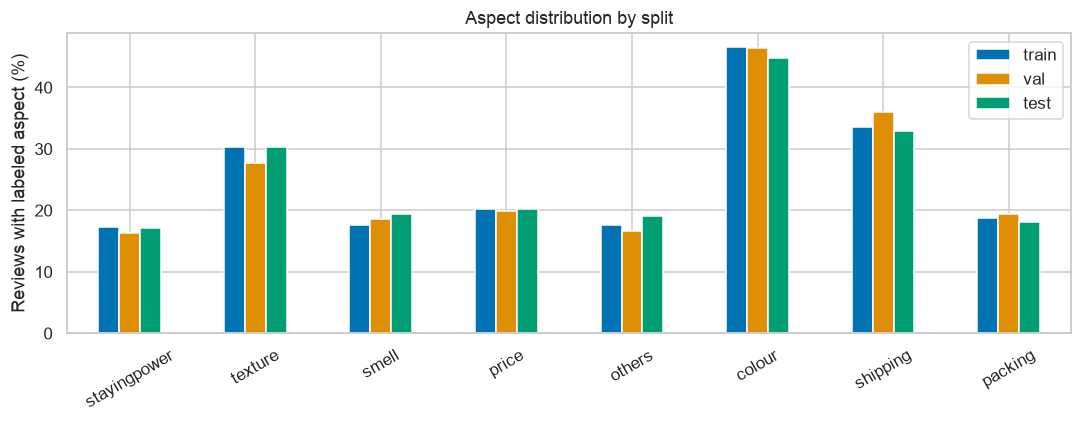

,train,val,test
sentiment,,,
positive,18694,2336,2298
neutral,3822,462,511
negative,3715,466,471


,train,val,test
positive,71.27,71.57,70.06
neutral,14.57,14.15,15.58
negative,14.16,14.28,14.36


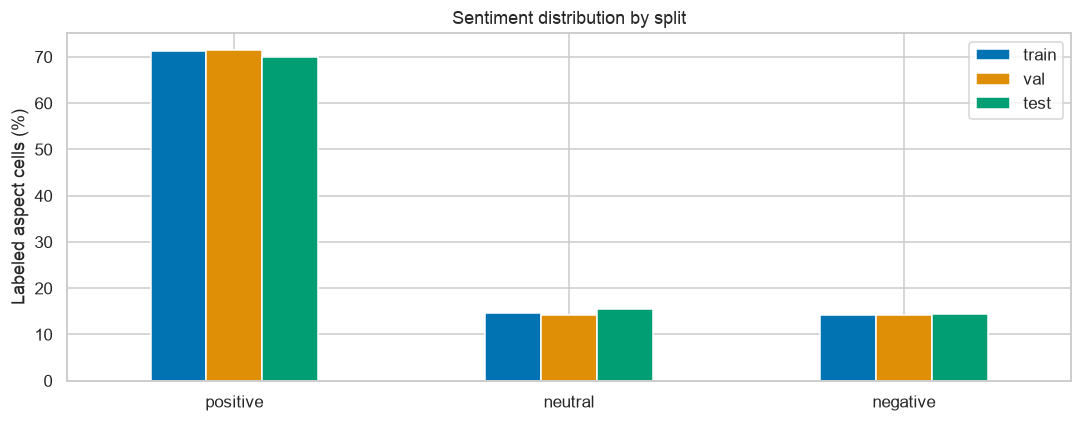

,split,aspect,labeled_cells,positive_pct,neutral_pct,negative_pct
0,train,stayingpower,2238,55.27,11.04,33.69
1,train,texture,3944,73.02,10.85,16.13
2,train,smell,2292,80.76,4.41,14.83
3,train,price,2635,98.60,0.83,0.57
4,train,others,2291,0.00,100.00,0.00
5,train,colour,6038,83.55,7.25,9.19
6,train,shipping,4351,63.00,6.44,30.57
7,train,packing,2442,95.90,0.61,3.48
8,val,stayingpower,264,54.17,11.74,34.09
9,val,texture,450,70.89,12.00,17.11


In [4]:
split_sizes = summary.loc[SPLITS, ['rows']].copy()
split_sizes['ratio_pct'] = 100 * split_sizes['rows'] / split_sizes['rows'].sum()
display(split_sizes)
aspect_rates = pd.DataFrame({s: presence[s].mean() for s in SPLITS})
aspect_counts_split = pd.DataFrame({s: presence[s].sum() for s in SPLITS})
display(aspect_counts_split.rename_axis('aspect'))
display((100 * aspect_rates).round(2).rename_axis('aspect'))
(100 * aspect_rates).plot.bar(ylabel='Reviews with labeled aspect (%)', title='Aspect distribution by split')
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

sentiment_counts = pd.DataFrame({s: datasets[s][ASPECTS].stack().value_counts().reindex(SENTIMENTS, fill_value=0)
                                for s in SPLITS})
sentiment_rates = sentiment_counts.div(sentiment_counts.sum(axis=0), axis=1)
display(sentiment_counts.rename_axis('sentiment'))
display((sentiment_rates * 100).round(2))
(sentiment_rates * 100).plot.bar(ylabel='Labeled aspect cells (%)', title='Sentiment distribution by split')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

conditional_rows = []
for s in SPLITS:
    for a in ASPECTS:
        counts = datasets[s][a].value_counts().reindex(SENTIMENTS, fill_value=0)
        n = int(counts.sum())
        conditional_rows.append({'split': s, 'aspect': a, 'labeled_cells': n,
                                 **{x + '_pct': 100 * counts[x] / n if n else np.nan for x in SENTIMENTS}})
conditional_sentiment = pd.DataFrame(conditional_rows)
display(conditional_sentiment.round(2))


In [5]:
def js_divergence(p, q):
    p, q = np.asarray(p, dtype=float), np.asarray(q, dtype=float)
    if p.sum() == 0 or q.sum() == 0:
        return np.nan
    p, q = p / p.sum(), q / q.sum()
    m = (p + q) / 2
    def kl(x):
        mask = x > 0
        return np.sum(x[mask] * np.log2(x[mask] / m[mask]))
    return float((kl(p) + kl(q)) / 2)

shift_rows = []
for s in ['val', 'test']:
    for a in ASPECTS:
        p, q = aspect_rates.loc[a, 'train'], aspect_rates.loc[a, s]
        c1 = datasets['train'][a].value_counts().reindex(SENTIMENTS, fill_value=0)
        c2 = datasets[s][a].value_counts().reindex(SENTIMENTS, fill_value=0)
        shift_rows.append({'split': s, 'aspect': a,
                           'presence_delta_pp': 100 * (q - p),
                           'presence_JS_bits': js_divergence([p, 1-p], [q, 1-q]),
                           'sentiment_JS_bits': js_divergence(c1, c2)})
distribution_shift = pd.DataFrame(shift_rows)
display(distribution_shift.round(4))
print('JS divergence uses base 2: 0 = identical distributions, 1 = disjoint support; no automatic pass/fail threshold.')


,split,aspect,presence_delta_pp,presence_JS_bits,sentiment_JS_bits
0,val,stayingpower,-0.9744,0.0001,0.0001
1,val,texture,-2.6564,0.0006,0.0004
2,val,smell,1.0126,0.0001,0.0007
3,val,price,-0.3975,0.0000,0.0031
4,val,others,-1.0130,0.0001,0.0000
5,val,colour,-0.0570,0.0000,0.0012
6,val,shipping,2.4645,0.0005,0.0002
7,val,packing,0.6580,0.0001,0.0021
8,test,stayingpower,-0.1734,0.0000,0.0023
9,test,texture,-0.0070,0.0000,0.0009


JS divergence uses base 2: 0 = identical distributions, 1 = disjoint support; no automatic pass/fail threshold.


### Duplicate và mâu thuẫn nhãn

Exact row = text + 8 nhãn. Exact text = review giống hệt, bất kể nhãn.
Normalized text chỉ **lowercase → trim → collapse whitespace**, giữ dấu tiếng Việt và dấu câu.
Loại review rỗng khỏi overlap text vì chuỗi rỗng không phải bằng chứng chia sẻ nội dung.
`shared_unique_keys` là số nội dung/row chung; `rows_left/right` là số dòng liên quan mỗi split;
`cross_pairs` đếm mọi cặp dòng, nên có thể lớn hơn số nội dung chung.
Label conflict = cùng text key có hơn một vector 8 nhãn, kể cả khác blank.


In [6]:
def normalize_text(s):
    return re.sub(r'\s+', ' ', s.lower().strip())

def keys_for(df, mode):
    if mode == 'exact_row':
        return list(df[[TEXT_COL, *ASPECTS]].itertuples(index=False, name=None))
    vals = df[TEXT_COL] if mode == 'exact_text' else df[TEXT_COL].map(normalize_text)
    return vals[vals.str.strip().ne('')].tolist()

leakage_rows, leakage_examples = [], []
for left, right in combinations(SPLITS, 2):
    for mode in ['exact_row', 'exact_text', 'normalized_text']:
        c1, c2 = Counter(keys_for(datasets[left], mode)), Counter(keys_for(datasets[right], mode))
        shared = set(c1) & set(c2)
        leakage_rows.append({'left': left, 'right': right, 'mode': mode,
                             'shared_unique_keys': len(shared),
                             'rows_left': sum(c1[k] for k in shared),
                             'rows_right': sum(c2[k] for k in shared),
                             'cross_pairs': sum(c1[k] * c2[k] for k in shared)})
        if mode == 'normalized_text':
            for k in sorted(shared)[:5]:
                for s in [left, right]:
                    df = datasets[s]
                    e = df.loc[df[TEXT_COL].map(normalize_text).eq(k), [TEXT_COL, *ASPECTS]].head(2).copy()
                    e.insert(0, 'source_row_0based', e.index)
                    e.insert(0, 'split', s)
                    e.insert(0, 'pair', f'{left} / {right}')
                    leakage_examples.append(e)
leakage_report = pd.DataFrame(leakage_rows)
display(leakage_report)
if leakage_examples:
    display(pd.concat(leakage_examples, ignore_index=True))

combined = pd.concat([datasets[s].assign(split=s, source_row_0based=datasets[s].index) for s in SPLITS], ignore_index=True)
conflict_rows = []
conflict_samples = []
for mode in ['exact_text', 'normalized_text']:
    tmp = combined.copy()
    tmp['text_key'] = tmp[TEXT_COL] if mode == 'exact_text' else tmp[TEXT_COL].map(normalize_text)
    tmp = tmp[tmp['text_key'].str.strip().ne('')]
    tmp['label_vector'] = list(tmp[ASPECTS].itertuples(index=False, name=None))
    g = tmp.groupby('text_key').agg(rows=('text_key', 'size'),
                                   label_variants=('label_vector', 'nunique'), splits=('split', 'nunique'))
    bad = g[g['label_variants'] > 1]
    conflict_rows.append({'mode': mode, 'conflicting_unique_texts': len(bad),
                          'conflicting_across_splits': int((bad['splits'] > 1).sum())})
    if len(bad):
        conflict_samples.append(tmp[tmp['text_key'].isin(bad.head(3).index)][['split','source_row_0based',TEXT_COL,*ASPECTS]])
display(pd.DataFrame(conflict_rows))
for e in conflict_samples:
    display(e)
overlap = int(leakage_report.query("mode == 'normalized_text'")['shared_unique_keys'].sum())
display(Markdown('**Leakage audit:** ' + (
    'Có review chung giữa các split sau normalization; đây là nguy cơ contamination của evaluation. '
    'Cần xem ví dụ, độ phổ biến của template và provenance trước khi kết luận nguyên nhân. '
    'Nếu chia lại dữ liệu, nhóm review trùng trước khi split và xử lý nhãn mâu thuẫn.'
    if overlap else 'Không tìm thấy overlap theo exact/normalized text trong audit này. '
    'Kiểm tra này chưa loại trừ paraphrase, review cùng người/sản phẩm hoặc template gần giống vì thiếu metadata.')))


,left,right,mode,shared_unique_keys,rows_left,rows_right,cross_pairs
0,train,val,exact_row,20,147,37,1208
1,train,val,exact_text,18,148,38,1265
2,train,val,normalized_text,19,156,39,1273
3,train,test,exact_row,18,137,30,768
4,train,test,exact_text,18,148,30,795
5,train,test,normalized_text,19,155,31,802
6,val,test,exact_row,5,20,15,119
7,val,test,exact_text,5,24,15,128
8,val,test,normalized_text,6,25,16,129


,pair,split,source_row_0based,data,stayingpower,texture,smell,price,others,colour,shipping,packing
0,train / val,train,2860,...................................................,,,,,neutral,,,
1,train / val,val,792,...................................................,,,,,neutral,,,
2,train / val,train,10163,"[New 2021] [Full 21 màu] Son kem lì, lên màu chuẩn Hàn Quốc Romand Zero Velvet Tint\n\n- Xuất xứ: Hàn Quốc\n- Thương hiệu: Romand\n- Trọng lượng: 5.5g\n\n**...",,,,,neutral,,,
3,train / val,val,730,"[New 2021] [Full 21 màu] Son kem lì, lên màu chuẩn Hàn Quốc Romand Zero Velvet Tint\n\n- Xuất xứ: Hàn Quốc\n- Thương hiệu: Romand\n- Trọng lượng: 5.5g\n\n**...",,,,,neutral,,,
4,train / val,train,3064,Chất lượng sản phẩm tuyệt vời giao hàng nhanh đóng gói chắc chắn,,,,,,,positive,positive
5,train / val,train,10000,Chất lượng sản phẩm tuyệt vời \nGiao hàng nhanh \nĐóng gói chắc chắn,,,,,,,positive,positive
6,train / val,val,1194,Chất lượng sản phẩm tuyệt vời giao hàng nhanh đóng gói chắc chắn,,,,,,,positive,positive
7,train / val,train,301,Chất lượng sản phẩm tuyệt vời\nĐóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,positive
8,train / val,train,7038,Chất lượng sản phẩm tuyệt vời đóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,positive
9,train / val,val,392,Chất lượng sản phẩm tuyệt vời đóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,positive


,mode,conflicting_unique_texts,conflicting_across_splits
0,exact_text,6,4
1,normalized_text,8,4


,split,source_row_0based,data,stayingpower,texture,smell,price,others,colour,shipping,packing
1192,train,1192,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,positive,positive
2682,train,2682,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng...",,,,,neutral,,,
4666,train,4666,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,,positive
5564,train,5564,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,positive,positive
5981,train,5981,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,,positive
7038,train,7038,Chất lượng sản phẩm tuyệt vời đóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,positive
9231,train,9231,Chất lượng sản phẩm tuyệt vời đóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,positive
9492,train,9492,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,positive,positive
10989,train,10989,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,positive,positive
11675,train,11675,Chất lượng sản phẩm tuyệt vời đóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,


,split,source_row_0based,data,stayingpower,texture,smell,price,others,colour,shipping,packing
301,train,301,Chất lượng sản phẩm tuyệt vời\nĐóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,positive
1192,train,1192,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,positive,positive
4666,train,4666,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,,positive
5564,train,5564,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,positive,positive
5981,train,5981,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,,positive
7038,train,7038,Chất lượng sản phẩm tuyệt vời đóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,positive
8901,train,8901,Chất lượng sản phẩm tuyệt vời\r\nĐóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,positive
9231,train,9231,Chất lượng sản phẩm tuyệt vời đóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,positive
9316,train,9316,Chất lượng son ... Giá học sinh \r\n\r\n\r\nHehe mn rảnh qua tường e mua trị mụn và dưỡng da nạ 🥰🥰🥰🥰,,,,,neutral,,,
9492,train,9492,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,positive,positive


**Leakage audit:** Có review chung giữa các split sau normalization; đây là nguy cơ contamination của evaluation. Cần xem ví dụ, độ phổ biến của template và provenance trước khi kết luận nguyên nhân. Nếu chia lại dữ liệu, nhóm review trùng trước khi split và xử lý nhãn mâu thuẫn.

## 3. Text-level EDA

Character count dùng `len` của Unicode string (không phải số grapheme hiển thị).
Word count dùng whitespace token: tiếng Việt có nhiều từ đa âm tiết nên **không phải word segmentation**,
và không tương đương số subword token. Review dài có thể gồm cả noise; tail samples cần đọc thủ công.


,split,metric,mean,median,std,min,max,P90,P95,P99
0,full,character_count,98.60,81.0,54.23,1,635,167.0,223.0,299.00
1,full,word_count,21.19,18.0,13.19,1,125,38.0,50.0,68.00
2,train,character_count,98.56,81.0,54.23,2,635,167.0,222.0,299.00
3,train,word_count,21.18,18.0,13.18,1,125,38.0,50.0,68.00
4,val,character_count,97.55,80.0,52.29,1,355,159.0,213.7,300.00
5,val,word_count,21.04,18.0,12.54,1,81,36.0,48.0,66.78
6,test,character_count,99.98,81.0,56.08,2,345,175.6,235.0,300.00
7,test,word_count,21.39,18.0,13.88,1,85,39.0,53.0,69.00


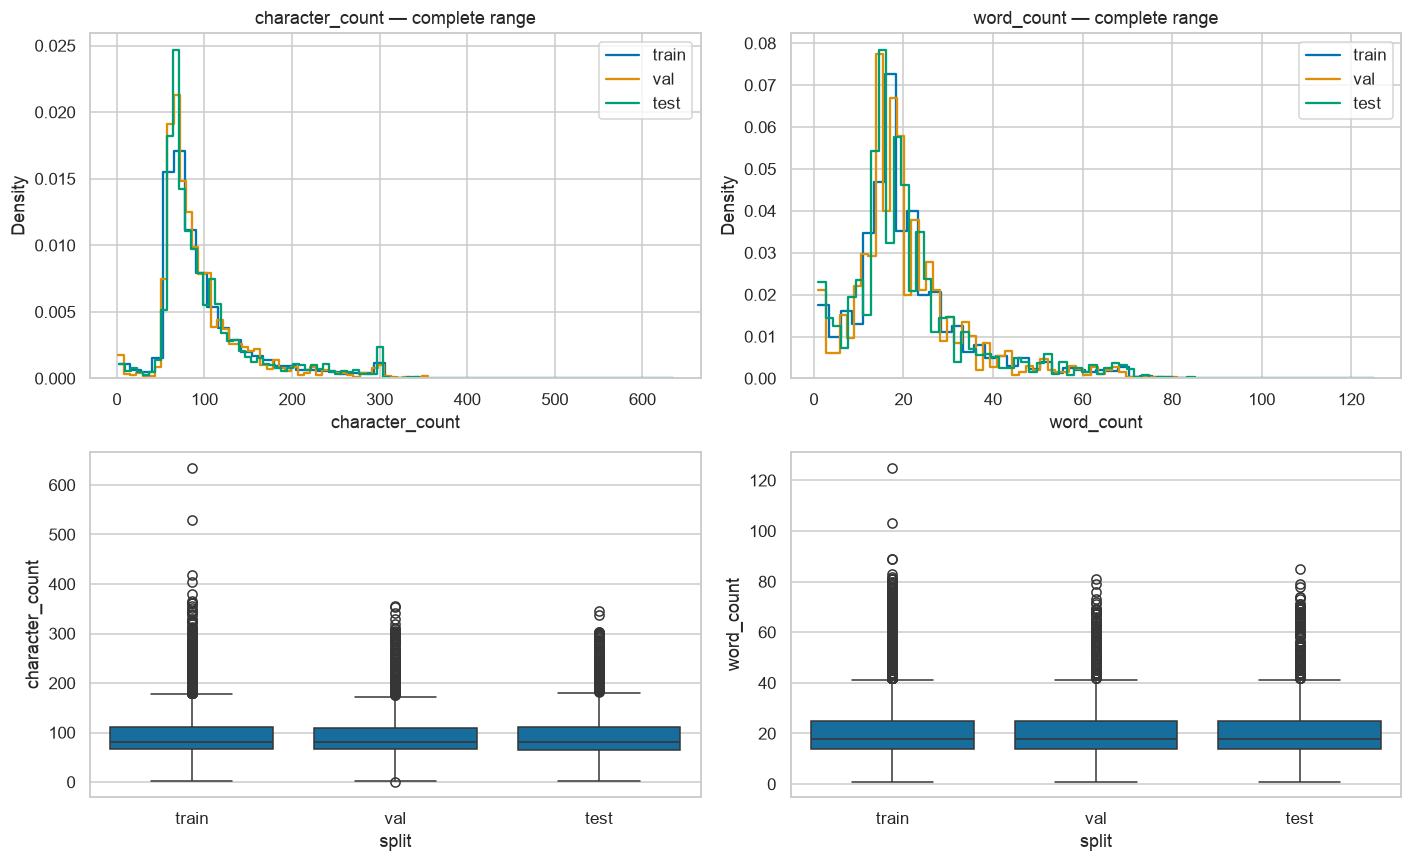

In [7]:
length_frames = {}
for s, df in datasets.items():
    lf = df[[TEXT_COL]].copy()
    lf['source_row_0based'] = lf.index
    lf['character_count'] = lf[TEXT_COL].str.len()
    lf['word_count'] = lf[TEXT_COL].str.split().str.len()
    length_frames[s] = lf
length_stats = []
for s, lf in length_frames.items():
    for metric in ['character_count', 'word_count']:
        x = lf[metric]
        length_stats.append({'split': s, 'metric': metric, 'mean': x.mean(), 'median': x.median(),
                             'std': x.std(ddof=1), 'min': x.min(), 'max': x.max(),
                             'P90': x.quantile(.90), 'P95': x.quantile(.95), 'P99': x.quantile(.99)})
length_summary = pd.DataFrame(length_stats)
display(length_summary.round(2))
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for j, metric in enumerate(['character_count', 'word_count']):
    for s in SPLITS:
        sns.histplot(length_frames[s][metric], bins=50, stat='density', element='step', fill=False,
                     label=s, ax=axes[0, j])
    axes[0, j].set_title(metric + ' — complete range'); axes[0, j].legend()
    chart_data = pd.concat([length_frames[s][[metric]].assign(split=s) for s in SPLITS])
    sns.boxplot(data=chart_data, x='split', y=metric, ax=axes[1,j], showfliers=True)
plt.tight_layout(); plt.show()


In [8]:
train_lengths = length_frames['train']
for metric in ['character_count', 'word_count']:
    print(f'Train: 5 shortest / longest by {metric}')
    display(train_lengths.nsmallest(5, metric))
    display(train_lengths.nlargest(5, metric))

coverage_rows = []
for metric in ['character_count', 'word_count']:
    for q in [.90, .95, .99]:
        threshold = int(np.ceil(train_lengths[metric].quantile(q)))
        coverage_rows.append({'metric': metric, 'train_quantile': q, 'threshold': threshold,
                              'train_above_pct': 100 * (train_lengths[metric] > threshold).mean()})
display(pd.DataFrame(coverage_rows).round(2))
display(Markdown('**Độ dài cho model:** chọn tokenizer trước, đo token length trên train '
                 '(bao gồm special tokens), rồi khảo sát P95/P99 và tỷ lệ truncation. '
                 'Bảng trên chỉ là coverage theo ký tự/whitespace; chưa đề xuất một `max_length` token cụ thể.'))


Train: 5 shortest / longest by character_count


,data,source_row_0based,character_count,word_count
136,Dc,136,2,1
5897,👍🏻,5897,2,1
11137,Ok,11137,2,1
11736,Ok,11736,2,1
39,NAN,39,3,1


,data,source_row_0based,character_count,word_count
11983,"Công dụng: son đi học, đi chơi, đi dạo okokookokokokokokokokokokookokokok okokookokokokokokokokokokookokokok ok\nKết cấu: son kem, lì okokookokokokokokokoko...",11983,635,54
7937,"Công dụng: mau dep, nude sieu xinh. Ca nhan minh thay mau 104 dep hon kh chi ve mau ma ca chat son cung dep hon\nKết cấu: son li nhung nhanh troi, quet 1 ca...",7937,529,125
2554,"Công dụng: làm đẹp\nKết cấu: dễ sử dụng\nĐộ bền màu: khá lâu trôi nhen , son môi lên màu lắm, dùng lớp dưỡng trc khi son nha ,\nmình từng dùng màu 12 r rất ...",2554,418,103
3338,"Công dụng: khá đẹp\nKết cấu: son nhẹ môi, nhưng khá khô\nĐộ bền màu: mình thấy son k bám mấy, khá dễ trôi\nKhông giống tượng hổ mang vẻ ""hững hờ"" ở Bạc Liêu...",3338,404,89
11156,"Công dụng: Có thể nâng tông da và răng\r\nKết cấu: Mềm mại\r\nĐộ bền màu: Khá tốt\r\nGiao hàng khá nhanh,thiết kế của son bao đẹp trông rất quý phái và sang...",11156,379,81


Train: 5 shortest / longest by word_count


,data,source_row_0based,character_count,word_count
13,https://vt.tiktok.com/ZSeSx64UP/WHUXE57https://vt.tiktok.com/ZSeSx64UP/https://www.facebook.com/lan.emm.2k2https://vt.tiktok.com/ZSeSx64UP/https://www.faceb...,13,207,1
30,únnsnxnhywbbhsnnznnznznxjxjxkxnjxjxjjxxjxjjjjxjxjjxjxjxnznnznznznnznznnnznzhsuskkcnncbx,30,87,1
39,NAN,39,3,1
88,Hsjasijsbsbsbsbsbsbbsnananananansnzznnanansnsnsnsnanan,88,54,1
115,NAN,115,3,1


,data,source_row_0based,character_count,word_count
7937,"Công dụng: mau dep, nude sieu xinh. Ca nhan minh thay mau 104 dep hon kh chi ve mau ma ca chat son cung dep hon\nKết cấu: son li nhung nhanh troi, quet 1 ca...",7937,529,125
2554,"Công dụng: làm đẹp\nKết cấu: dễ sử dụng\nĐộ bền màu: khá lâu trôi nhen , son môi lên màu lắm, dùng lớp dưỡng trc khi son nha ,\nmình từng dùng màu 12 r rất ...",2554,418,103
1039,"Công dụng: son kem chất đẹp và sử dụng mượt\nKết cấu: đẹp và xinh\nĐộ bền màu: 60 % / nói chung là cần kết hợp son khác\nSản phẩm đẹp nha mn, rẻ mà xinh- nó...",1039,366,89
3338,"Công dụng: khá đẹp\nKết cấu: son nhẹ môi, nhưng khá khô\nĐộ bền màu: mình thấy son k bám mấy, khá dễ trôi\nKhông giống tượng hổ mang vẻ ""hững hờ"" ở Bạc Liêu...",3338,404,89
6724,"Công dụng: lên màu rất đẹp\nKết cấu: đặc\nĐộ bền màu: màu đỏ gạch\nV27 sẽ là sự pha trộn giữa tone màu cam đất kèm theo chút ánh đỏ. Màu son rất dễ dùng, ai...",6724,362,83


,metric,train_quantile,threshold,train_above_pct
0,character_count,0.90,167,9.95
1,character_count,0.95,222,4.96
2,character_count,0.99,299,0.93
3,word_count,0.90,38,9.76
4,word_count,0.95,50,4.78
5,word_count,0.99,68,0.84


**Độ dài cho model:** chọn tokenizer trước, đo token length trên train (bao gồm special tokens), rồi khảo sát P95/P99 và tỷ lệ truncation. Bảng trên chỉ là coverage theo ký tự/whitespace; chưa đề xuất một `max_length` token cụ thể.

### Đọc thủ công các tail samples (train, row index bắt đầu từ 0)

- Row **136** (`Dc`), **5897** (`👍🏻`) và **11137** (`Ok`) rất ngắn nhưng có thể chứa tín hiệu đánh giá; không tự kết luận là noise.
- Row **13** là chuỗi URL nối tiếp; row **30** là chuỗi ký tự giống gõ ngẫu nhiên; row **39** là literal `NAN`. Cần xem annotation và nguồn gốc trước khi coi `NAN` là review bị thiếu. Những mẫu này có whitespace-count = 1, cho thấy độ dài theo whitespace có thể gây hiểu nhầm.
- Row **11983** dài **635 ký tự**, vừa có nhận xét về son vừa lặp `okok...` nhiều lần. Đây là review có nội dung lẫn filler, không phải toàn bộ văn bản đều vô nghĩa.
- Row **7937** dài **125 whitespace tokens**, so sánh màu 104/105, chất son và giao hàng; row **2554** dài **103 whitespace tokens**, mô tả màu, dưỡng môi và quà tặng. Những mẫu dài này có nội dung review rõ ràng.

Các nhận xét trên dựa vào vài mẫu đã hiển thị, không phải tỷ lệ spam của toàn dataset. Detector filler đơn giản có thể bỏ sót chuỗi gõ ngẫu nhiên có vowel và các đoạn lặp `okok...`.

## 4. Vietnamese text noise analysis

Đây là **pattern flags**, không phải nhãn noise/spam xác thực; không tự xoá hoặc chuẩn hoá dữ liệu.
Emoji dùng các Unicode ranges phổ biến, có thể đếm cả ký hiệu và bỏ sót chuỗi mới.
Slang dùng token boundary và danh sách `ko, k, mn, sp, shop, nvay`; `shop` là từ thông dụng,
không mặc nhiên là lỗi. Uppercase bất thường: ít nhất 10 chữ cái, trên 50% là uppercase.
Filler heuristic: token Latin dài ≥8 ký tự, không có vowel sau khi bỏ dấu; có thể bắt nhầm mã hàng.
Một review có thể khớp nhiều pattern, vì vậy không cộng các tỷ lệ để ra tỷ lệ noise tổng.


In [9]:
emoji_re = re.compile('[\U0001F1E6-\U0001F1FF\U0001F300-\U0001FAFF\u2600-\u27BF]')
repeat_char_re = re.compile(r'([^\W\d_])\1{2,}', re.IGNORECASE)
slang_re = re.compile(r'(?<!\w)(?:ko|k|mn|sp|shop|nvay)(?!\w)', re.IGNORECASE)
punct_re = re.compile(r'([!?.,:;])\1{2,}')
url_re = re.compile(r'(?:https?://|www\.)\S+', re.IGNORECASE)
number_re = re.compile(r'\d')
def excessive_uppercase(text):
    letters = [c for c in text if c.isalpha()]
    return len(letters) >= 10 and sum(c.isupper() for c in letters) / len(letters) > .5
def strip_diacritics(text):
    return ''.join(c for c in unicodedata.normalize('NFD', text.lower())
                   if unicodedata.category(c) != 'Mn').replace('đ', 'd')
def filler_candidate(text):
    tokens = re.findall(r'[a-z]+', strip_diacritics(text))
    return any(len(t) >= 8 and not re.search('[aeiouy]', t) for t in tokens)
def symbols_only(text):
    return bool(text.strip()) and not any(c.isalnum() for c in text)

detectors = {
    'emoji_or_symbol_range': lambda x: bool(emoji_re.search(x)),
    'repeated_letter_3plus': lambda x: bool(repeat_char_re.search(x)),
    'slang_or_shop_token': lambda x: bool(slang_re.search(x)),
    'uppercase_gt50pct_min10letters': excessive_uppercase,
    'repeated_punctuation_3plus': lambda x: bool(punct_re.search(x)),
    'url': lambda x: bool(url_re.search(x)),
    'number': lambda x: bool(number_re.search(x)),
    'filler_candidate_no_vowel': filler_candidate,
    'symbols_only': symbols_only,
}
noise_flags = {s: pd.DataFrame({name: df[TEXT_COL].map(fn) for name, fn in detectors.items()})
               for s, df in datasets.items()}
noise_summary = pd.DataFrame([{'split': s, 'pattern': p, 'reviews': int(flags[p].sum()),
                               'pct': 100 * flags[p].mean()}
                              for s, flags in noise_flags.items() for p in detectors])
display(noise_summary.round(2))
noise_examples = []
for p in detectors:
    idx = noise_flags['train'].index[noise_flags['train'][p]][:3]
    for i in idx:
        noise_examples.append({'pattern': p, 'source_row_0based': i, 'review': datasets['train'].loc[i, TEXT_COL]})
display(pd.DataFrame(noise_examples))
slang_counts = pd.Series({t: datasets['train'][TEXT_COL].str.contains(
    r'(?<!\w)' + re.escape(t) + r'(?!\w)', case=False, regex=True).sum()
    for t in ['ko','k','mn','sp','shop','nvay']}, name='train_reviews_with_token')
display(slang_counts.to_frame())
display(Markdown('**Manual review:** các ví dụ filler/URL/repeated letters chỉ là candidates. '
                 'Emoji, slang, dấu câu và kéo dài chữ có thể mang sentiment signal; '
                 'cần đánh giá ablation trên validation trước khi quyết định preprocessing. '
                 'Heuristic filler không phát hiện được mọi chuỗi gõ ngẫu nhiên có vowel.'))


,split,pattern,reviews,pct
0,full,emoji_or_symbol_range,2371,14.61
1,full,repeated_letter_3plus,2713,16.72
2,full,slang_or_shop_token,5219,32.16
3,full,uppercase_gt50pct_min10letters,12,0.07
4,full,repeated_punctuation_3plus,893,5.50
5,full,url,43,0.26
6,full,number,3731,22.99
7,full,filler_candidate_no_vowel,496,3.06
8,full,symbols_only,31,0.19
9,train,emoji_or_symbol_range,1920,14.79


,pattern,source_row_0based,review
0,emoji_or_symbol_range,6,Son đẹp lắm ạ đóng gói chưa tốt lắm nm với số tiền này là OK 👌👌👌👌👌
1,emoji_or_symbol_range,16,"giao đầy đủ son , còn được tặng chì kẻ nưa 🥰 mua page chính hãng nên rất an tâm"
2,emoji_or_symbol_range,17,Hình ảnh mang tính chất nhận xu ^_^^_^^_^^_^^_^^_^^_^^_^♥️♥️♥️♥️♥️♥️♥️♥️♥️♥️😏😕😕😕😕😕😕
3,repeated_letter_3plus,9,son xinh xĩu mùi thơm nữa hình ảnh mang tính chất nhận xuuuuuuuuuuuuu
4,repeated_letter_3plus,10,Hgtgjgssyhhygrtgoklo ưu tú từ hạ hhh jcthjh được ỵnghfghj
5,repeated_letter_3plus,13,https://vt.tiktok.com/ZSeSx64UP/WHUXE57https://vt.tiktok.com/ZSeSx64UP/https://www.facebook.com/lan.emm.2k2https://vt.tiktok.com/ZSeSx64UP/https://www.faceb...
6,slang_or_shop_token,1,Son đẹp lắm nha mn tuy là son nội địa giá rẻ nhưng chất son mịn dễ tán ko bị bón cục mùi son thơm nhẹ nhẹ ko quá nồng
7,slang_or_shop_token,7,"Shop gói hàng cực kì chắc và cẩn thận luôn, mùi son thơm trái cây cực kì, sẽ quay lại shop 1 lần nữa"
8,slang_or_shop_token,14,Hình ảnh chi mang tính chất nhận xu \r\nMàu đẹp shop đóng gói cẩn thận ghhhhhhh
9,uppercase_gt50pct_min10letters,357,DÙNG CHÁN RẤT BỘT LUÔN\nMÌNH SẼ KO BAO GIỜ MUA LẠI SP CỦA FOCALLURE VÌ CHẤT LƯỢNG QUÁ TỆ


,train_reviews_with_token
ko,791
k,998
mn,670
sp,271
shop,2029
nvay,0


**Manual review:** các ví dụ filler/URL/repeated letters chỉ là candidates. Emoji, slang, dấu câu và kéo dài chữ có thể mang sentiment signal; cần đánh giá ablation trên validation trước khi quyết định preprocessing. Heuristic filler không phát hiện được mọi chuỗi gõ ngẫu nhiên có vowel.

## 5. Aspect frequency và imbalance

`y_ia = 1` khi ô aspect có sentiment hợp lệ; `0` khi blank.
`IR_a = max(count) / count_a` dùng trong cùng split; count = 0 cho IR vô hạn.
Dominant/rare là tần suất nhãn, không phải kết luận aspect đó quan trọng hơn/kém hơn.


,split,aspect,count,review_pct,imbalance_ratio
0,full,stayingpower,2779,17.126,2.706
1,full,texture,4887,30.116,1.539
2,full,smell,2911,17.939,2.583
3,full,price,3286,20.250,2.288
4,full,others,2872,17.699,2.618
5,full,colour,7519,46.336,1.000
6,full,shipping,5469,33.703,1.375
7,full,packing,3052,18.808,2.464
8,train,stayingpower,2238,17.241,2.698
9,train,texture,3944,30.383,1.531


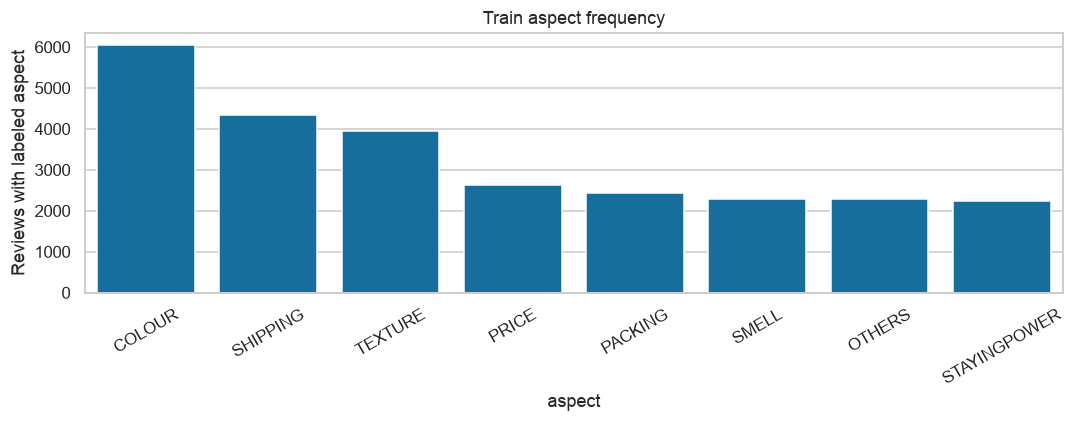

**Train:** dominant = **COLOUR** (6,038 reviews); rare = **STAYINGPOWER** (2,238 reviews). IR của aspect hiếm nhất = **2.70**.

In [10]:
frequency_rows = []
for s, y in presence.items():
    counts = y.sum()
    for a in ASPECTS:
        frequency_rows.append({'split': s, 'aspect': a, 'count': int(counts[a]),
                               'review_pct': 100 * counts[a] / len(y),
                               'imbalance_ratio': counts.max() / counts[a] if counts[a] else np.inf})
aspect_frequency = pd.DataFrame(frequency_rows)
display(aspect_frequency.round(3))
train_frequency = aspect_frequency.query("split == 'train'").sort_values('count', ascending=False)
sns.barplot(data=train_frequency.assign(aspect=lambda x: x['aspect'].str.upper()), x='aspect', y='count')
plt.title('Train aspect frequency'); plt.ylabel('Reviews with labeled aspect')
plt.xticks(rotation=30); plt.tight_layout(); plt.show()
top = train_frequency.iloc[0]; rare = train_frequency.iloc[-1]
display(Markdown(f'**Train:** dominant = **{top.aspect.upper()}** ({int(top["count"]):,} reviews); '
                 f'rare = **{rare.aspect.upper()}** ({int(rare["count"]):,} reviews). '
                 f'IR của aspect hiếm nhất = **{rare.imbalance_ratio:.2f}**.'))


## 6. Aspect cardinality / multi-label

`cardinality_i = sum_a y_ia`. Các review có ≥2 aspect chứng minh nhãn aspect là multi-label.
Review có 0 aspect có thể là mẫu ngoài phạm vi hoặc thiếu annotation; cần xem thủ công.


,full,train,val,test
aspects_per_review,,,,
0,16,14,1,1
1,6565,5231,672,662
2,4733,3807,458,468
3,3320,2657,331,332
4,1241,989,129,123
5,297,243,25,29
6,50,36,7,7
7,5,4,0,1
8,0,0,0,0


,mean,median,zero_aspect,multi_aspect,multi_aspect_pct
split,,,,,
full,2.020,2.0,16,9646,59.444
train,2.021,2.0,14,7736,59.595
val,2.011,2.0,1,950,58.534
test,2.021,2.0,1,960,59.150


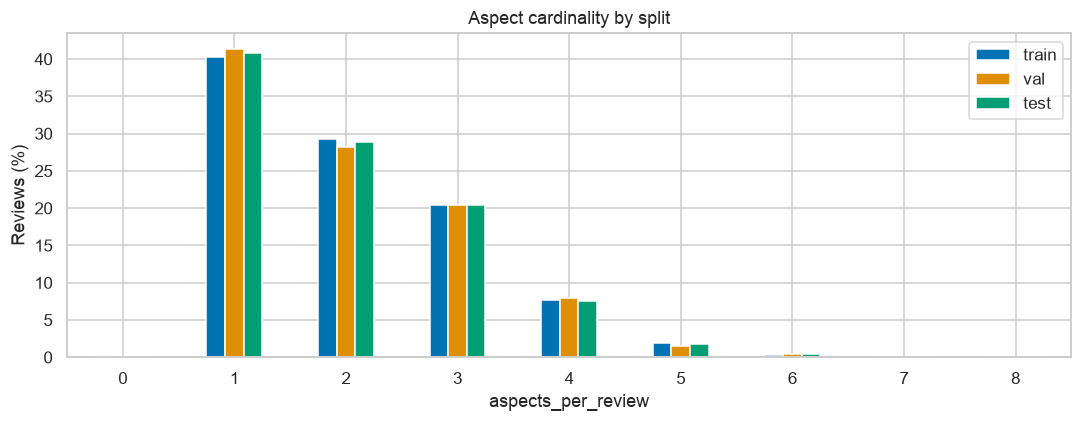

,source_row_0based,data,stayingpower,texture,smell,price,others,colour,shipping,packing
47,47,"Đóng gói nhanh, hàng chuẩn đẹp, chưa dùng nên chưa biết chất lượng thế nào",,,,,,,,
67,67,"Chưa dùng nên ko biết như thế nào nhưng đóng gói, bao bì đẹp, cho 5*",,,,,,,,
117,117,Chất lượng sản phẩm tuyệt vời đóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,
136,136,Shop đóng gói rất đẹp và chắc chắn chất lượng sản phẩm tuyệt vời,,,,,,,,
174,174,"Đóng gói rất cẩn thận, vỏ son nhìn rất xịn xò và sang chảnh, đẹp",,,,,,,,
187,187,Mình thấy đóng gói bao bì rất chắc chắn và rất xinh nha mọi người ơi. Mình thấy son cũng ổn,,,,,,,,
205,205,"Sản phẩm chất lượng tốt, đóng gói sản phẩm kỹ càng chắc chắn...",,,,,,,,
262,262,"shop đóng gói hàng cẩn thận, mình chưa bóc dùng thử. lần đầu mua của shop",,,,,,,,
296,296,"Son đẹp lắm ạ,shop lại còn gói hàng kĩ càng cẩn thận\r\nVd chỉ mang tính chất nhận xu",,,,,,,,
347,347,Đóng gói rất xinh\r\nChất lượng thì em cũng chưa dùng nên không rõ nhưng chắc là cũng được á :3\r\nUwU,,,,,,,,


**Train có 7,736 review chứa ≥2 aspect** (59.59%). Aspect detection cần đầu ra multi-label; sentiment được dự đoán theo từng aspect có nhãn.

In [11]:
cardinality = {s: y.sum(axis=1) for s, y in presence.items()}
card_distribution = pd.DataFrame({s: c.value_counts().reindex(range(9), fill_value=0)
                                  for s, c in cardinality.items()}).rename_axis('aspects_per_review')
display(card_distribution)
card_stats = pd.DataFrame([{'split': s, 'mean': c.mean(), 'median': c.median(),
                            'zero_aspect': int(c.eq(0).sum()),
                            'multi_aspect': int(c.ge(2).sum()), 'multi_aspect_pct': 100*c.ge(2).mean()}
                           for s,c in cardinality.items()]).set_index('split')
display(card_stats.round(3))
card_distribution[SPLITS].div([len(datasets[s]) for s in SPLITS], axis=1).mul(100).plot.bar()
plt.ylabel('Reviews (%)'); plt.title('Aspect cardinality by split'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
zero_reviews = datasets['full'].loc[cardinality['full'].eq(0)].head(10).copy()
zero_reviews.insert(0, 'source_row_0based', zero_reviews.index)
display(zero_reviews)
n_multi = int(cardinality['train'].ge(2).sum())
display(Markdown(f'**Train có {n_multi:,} review chứa ≥2 aspect** '
                 f'({100*cardinality["train"].ge(2).mean():.2f}%). '
                 + ('Aspect detection cần đầu ra multi-label; sentiment được dự đoán theo từng aspect có nhãn.'
                    if n_multi else 'Train không có mẫu nhiều aspect; cần kiểm tra lại formulation.')))


## 7. Aspect co-occurrence

Co-occurrence count: số review cùng được gán hai aspect; đường chéo là tần suất riêng.
Jaccard: `n(A∩B) / n(A∪B)`, giúp so sánh cặp có tần suất khác nhau.
Lift: `P(A,B) / (P(A)P(B))`; >1 là cùng xuất hiện nhiều hơn mức độc lập,
không phải quan hệ nhân quả. Cặp hiếm có thể có lift cao nhưng kém ổn định.
Các chỉ số bên dưới dùng **train**, bao gồm duplicate hiện có, để tránh chọn cấu trúc model từ test.


,stayingpower,texture,smell,price,others,colour,shipping,packing
stayingpower,2238,1432,521,517,0,1386,612,268
texture,1432,3944,1083,971,0,2370,1093,548
smell,521,1083,2292,547,0,1376,707,365
price,517,971,547,2635,0,1345,883,406
others,0,0,0,0,2291,0,4,1
colour,1386,2370,1376,1345,0,6038,1922,987
shipping,612,1093,707,883,4,1922,4351,1422
packing,268,548,365,406,1,987,1422,2442


,stayingpower,texture,smell,price,others,colour,shipping,packing
stayingpower,1.000,0.301,0.130,0.119,0.000,0.201,0.102,0.061
texture,0.301,1.000,0.210,0.173,0.000,0.311,0.152,0.094
smell,0.130,0.210,1.000,0.125,0.000,0.198,0.119,0.084
price,0.119,0.173,0.125,1.000,0.000,0.184,0.145,0.087
others,0.000,0.000,0.000,0.000,1.000,0.000,0.001,0.000
colour,0.201,0.311,0.198,0.184,0.000,1.000,0.227,0.132
shipping,0.102,0.152,0.119,0.145,0.001,0.227,1.000,0.265
packing,0.061,0.094,0.084,0.087,0.000,0.132,0.265,1.000


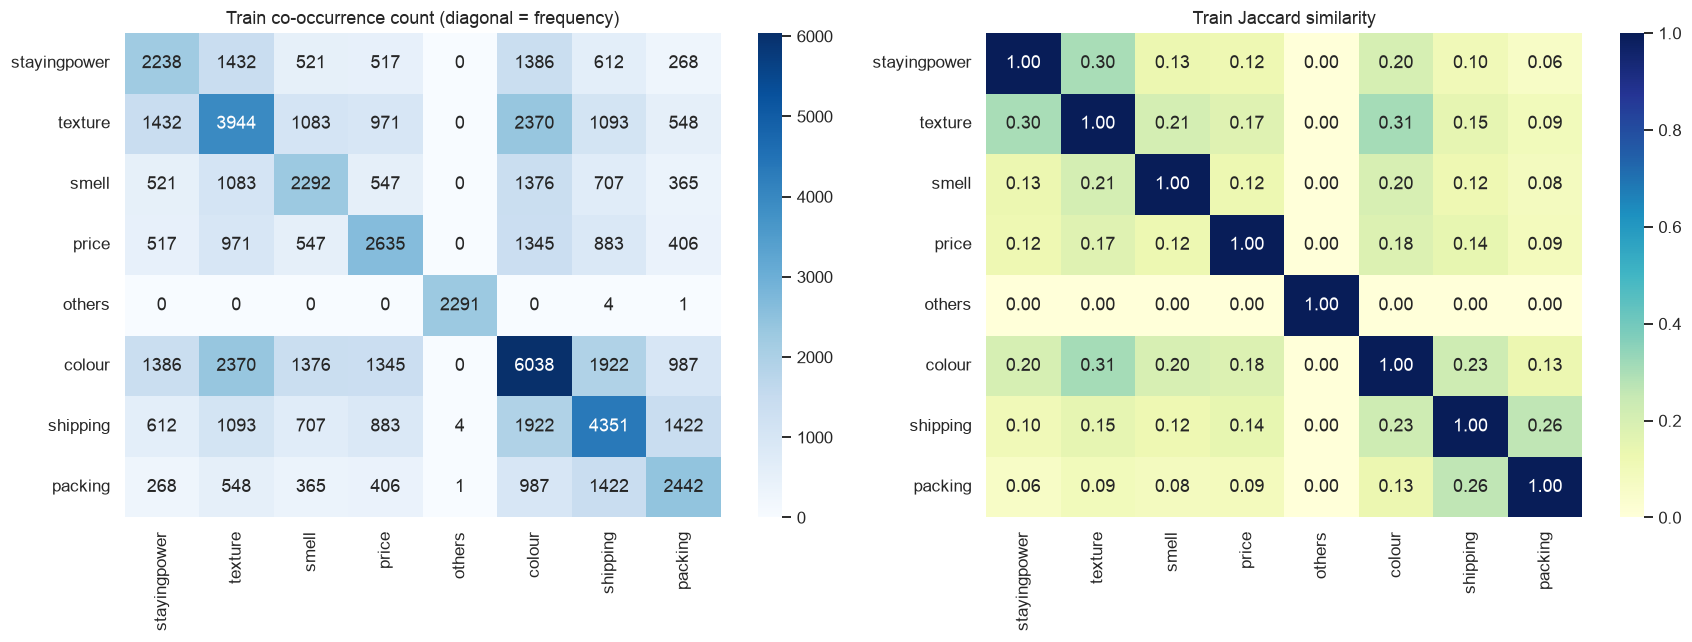

,aspect_A,aspect_B,co_count,review_pct,jaccard,lift,P_B_given_A,P_A_given_B
10,texture,colour,2370,18.2575,0.3114,1.2919,0.6009,0.3925
25,colour,shipping,1922,14.8063,0.2270,0.9497,0.3183,0.4417
0,stayingpower,texture,1432,11.0315,0.3015,2.1060,0.6399,0.3631
27,shipping,packing,1422,10.9545,0.2648,1.7373,0.3268,0.5823
4,stayingpower,colour,1386,10.6771,0.2012,1.3314,0.6193,0.2295
15,smell,colour,1376,10.6001,0.1979,1.2907,0.6003,0.2279
19,price,colour,1345,10.3613,0.1835,1.0974,0.5104,0.2228
11,texture,shipping,1093,8.4200,0.1518,0.8268,0.2771,0.2512
7,texture,smell,1083,8.3430,0.2102,1.5552,0.2746,0.4725
26,colour,packing,987,7.6034,0.1317,0.8689,0.1635,0.4042


Top 10 by Jaccard (inspect support count as well):


,aspect_A,aspect_B,co_count,review_pct,jaccard,lift,P_B_given_A,P_A_given_B
10,texture,colour,2370,18.2575,0.3114,1.2919,0.6009,0.3925
0,stayingpower,texture,1432,11.0315,0.3015,2.1060,0.6399,0.3631
27,shipping,packing,1422,10.9545,0.2648,1.7373,0.3268,0.5823
25,colour,shipping,1922,14.8063,0.2270,0.9497,0.3183,0.4417
7,texture,smell,1083,8.3430,0.2102,1.5552,0.2746,0.4725
4,stayingpower,colour,1386,10.6771,0.2012,1.3314,0.6193,0.2295
15,smell,colour,1376,10.6001,0.1979,1.2907,0.6003,0.2279
19,price,colour,1345,10.3613,0.1835,1.0974,0.5104,0.2228
8,texture,price,971,7.4802,0.1731,1.2129,0.2462,0.3685
11,texture,shipping,1093,8.4200,0.1518,0.8268,0.2771,0.2512


In [12]:
y = presence['train']
cooccurrence = y.T.dot(y)
counts = y.sum()
union = counts.to_numpy()[:,None] + counts.to_numpy()[None,:] - cooccurrence.to_numpy()
jaccard = pd.DataFrame(np.divide(cooccurrence.to_numpy(), union,
                                 out=np.full(union.shape, np.nan), where=union>0),
                       index=ASPECTS, columns=ASPECTS)
expected = np.outer(counts.to_numpy(), counts.to_numpy()) / len(y)
lift = pd.DataFrame(np.divide(cooccurrence.to_numpy(), expected,
                              out=np.full(expected.shape, np.nan), where=expected>0),
                    index=ASPECTS, columns=ASPECTS)
display(cooccurrence)
display(jaccard.round(3))
fig, axes = plt.subplots(1,2, figsize=(16,6))
sns.heatmap(cooccurrence, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Train co-occurrence count (diagonal = frequency)')
sns.heatmap(jaccard, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=axes[1])
axes[1].set_title('Train Jaccard similarity')
plt.tight_layout(); plt.show()
pair_rows = []
for a,b in combinations(ASPECTS,2):
    pair_rows.append({'aspect_A': a, 'aspect_B': b, 'co_count': int(cooccurrence.loc[a,b]),
                      'review_pct': 100*cooccurrence.loc[a,b]/len(y),
                      'jaccard': jaccard.loc[a,b], 'lift': lift.loc[a,b],
                      'P_B_given_A': cooccurrence.loc[a,b]/counts[a] if counts[a] else np.nan,
                      'P_A_given_B': cooccurrence.loc[a,b]/counts[b] if counts[b] else np.nan})
aspect_pairs = pd.DataFrame(pair_rows).sort_values('co_count', ascending=False)
display(aspect_pairs.round(4))
print('Top 10 by Jaccard (inspect support count as well):')
display(aspect_pairs.sort_values('jaccard', ascending=False).head(10).round(4))


### Annotation semantics đã đối chiếu với paper

Trong CSV, OTHERS chỉ có neutral. Paper định nghĩa OTHERS là spam (Table 1); mục 8 bổ sung thống kê sentiment loại OTHERS để phân biệt spam với neutral của 7 aspect sản phẩm/dịch vụ. [Paper, §3 và Table 1](https://aclanthology.org/2022.paclic-1.84.pdf).

PRICE trên train có 2.598 positive, 22 neutral và 15 negative; validation không có PRICE-negative. Sentiment tổng thể giống nhau chưa đủ để bảo đảm coverage ở từng aspect.


## Kết luận phần 1 — audit dữ liệu

Cell dưới tạo kết luận trực tiếp từ bảng đã tính. Không tự động deduplicate/split lại dữ liệu.
Nếu cần so sánh paper baseline, giữ split gốc và báo cáo contamination; một split sạch mới
phải được định danh riêng, lưu provenance và không so sánh điểm số như cùng benchmark.


In [13]:
test_overlap = leakage_report[(leakage_report['mode']=='normalized_text') &
                              (leakage_report['left']=='train') & (leakage_report['right']=='test')].iloc[0]
max_test_delta = distribution_shift.query("split == 'test'").loc[
    lambda x: x.presence_delta_pp.abs().idxmax()]
best_pair = aspect_pairs.iloc[0]
length_train = length_summary.query("split == 'train' and metric == 'word_count'").iloc[0]
messages = [
    f'**Dữ liệu:** {len(datasets["full"]):,} review, 8 aspects; row multiset full/splits match = {bool(union_check.iloc[0].row_multiset_match)}.',
    f'**Chất lượng:** full có {int(summary.loc["full", "empty_review"]):,} empty review, '
    f'{int(summary.loc["full", "whitespace_only_review"]):,} whitespace-only review, '
    f'{int(summary.loc["full", "duplicate_rows_extra"]):,} duplicate row dư; {invalid_total} invalid label cells across files.',
    f'**Leakage:** train/test có {int(test_overlap.shared_unique_keys):,} normalized text chung, '
    f'liên quan {int(test_overlap.rows_right):,}/{len(datasets["test"]):,} dòng test '
    f'({100*test_overlap.rows_right/len(datasets["test"]):.2f}%). Đây là audit overlap, chưa đo mức ảnh hưởng lên metric.',
    f'**Split shift:** chênh lệch aspect rate train/test lớn nhất ở {max_test_delta.aspect.upper()}: '
    f'{max_test_delta.presence_delta_pp:+.2f} percentage points. Xem sentiment theo aspect để đánh giá thêm; không gán pass/fail từ một threshold tuỳ ý.',
    f'**Text length:** train whitespace-count P95 = {length_train.P95:.1f}, P99 = {length_train.P99:.1f}; '
    'đo lại bằng tokenizer trước khi chốt max_length.',
    f'**Multi-label:** {100*cardinality["train"].ge(2).mean():.2f}% train có ≥2 aspects; '
    f'{int(cardinality["train"].eq(0).sum()):,} train review không có aspect label.',
    f'**Co-occurrence:** cặp phổ biến nhất là {best_pair.aspect_A.upper()} + {best_pair.aspect_B.upper()} '
    f'({int(best_pair.co_count):,} review, Jaccard {best_pair.jaccard:.3f}).',
    '**Hướng xử lý:** kiểm tra overlap và nhãn mâu thuẫn trước khi diễn giải kết quả test; '
    'giữ sentiment signal trong noise; cân nhắc metric per-aspect/macro để thấy ảnh hưởng imbalance. '
    'Các nhận xét về spam/noise vẫn cần review thủ công; chưa chạy model hoặc tokenizer.'
]
display(Markdown('\n\n'.join('- ' + m for m in messages)))


- **Dữ liệu:** 16,227 review, 8 aspects; row multiset full/splits match = True.

- **Chất lượng:** full có 0 empty review, 0 whitespace-only review, 251 duplicate row dư; 0 invalid label cells across files.

- **Leakage:** train/test có 19 normalized text chung, liên quan 31/1,623 dòng test (1.91%). Đây là audit overlap, chưa đo mức ảnh hưởng lên metric.

- **Split shift:** chênh lệch aspect rate train/test lớn nhất ở SMELL: +1.81 percentage points. Xem sentiment theo aspect để đánh giá thêm; không gán pass/fail từ một threshold tuỳ ý.

- **Text length:** train whitespace-count P95 = 50.0, P99 = 68.0; đo lại bằng tokenizer trước khi chốt max_length.

- **Multi-label:** 59.59% train có ≥2 aspects; 14 train review không có aspect label.

- **Co-occurrence:** cặp phổ biến nhất là TEXTURE + COLOUR (2,370 review, Jaccard 0.311).

- **Hướng xử lý:** kiểm tra overlap và nhãn mâu thuẫn trước khi diễn giải kết quả test; giữ sentiment signal trong noise; cân nhắc metric per-aspect/macro để thấy ảnh hưởng imbalance. Các nhận xét về spam/noise vẫn cần review thủ công; chưa chạy model hoặc tokenizer.

## 8. Global sentiment distribution và đối chiếu paper

Đơn vị là **aspect–sentiment cell**, không phải review có một sentiment duy nhất. Blank bị loại khỏi mẫu số.
Count, percentage và `IR = max(count)/min(count)` được tính riêng theo split. Nếu một class có 0 mẫu,
IR theo bộ ba class = ∞, không loại class đó để làm IR nhỏ hơn.

[Paper Table 3](https://aclanthology.org/2022.paclic-1.84.pdf) cung cấp số cell từng sentiment để đối chiếu CSV;
§3.3 mô tả Positive chiếm đa số ngoài OTHERS. Bảng `exclude_OTHERS` là phân tích sensitivity bổ sung.


,scope,split,sentiment,count,percentage,IR_majority_minority,dominant
0,all_8_aspects,train,positive,18694,71.267,5.032,positive
1,all_8_aspects,train,neutral,3822,14.571,5.032,positive
2,all_8_aspects,train,negative,3715,14.163,5.032,positive
3,all_8_aspects,val,positive,2336,71.569,5.056,positive
4,all_8_aspects,val,neutral,462,14.154,5.056,positive
5,all_8_aspects,val,negative,466,14.277,5.056,positive
6,all_8_aspects,test,positive,2298,70.061,4.879,positive
7,all_8_aspects,test,neutral,511,15.579,4.879,positive
8,all_8_aspects,test,negative,471,14.360,4.879,positive
9,exclude_OTHERS,train,positive,18694,78.087,12.210,positive


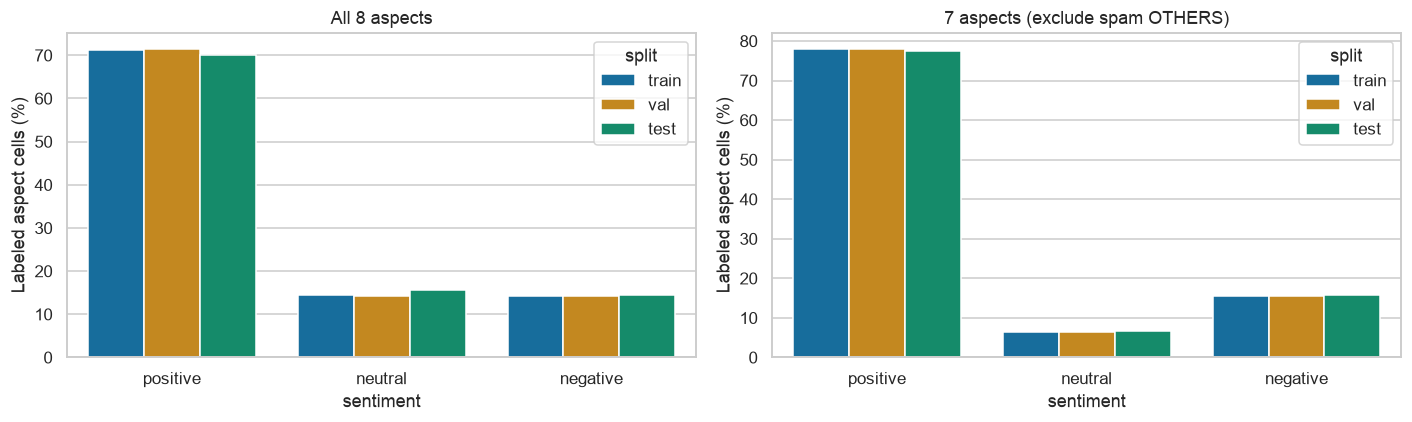

Local CSV minus paper Table 3 counts (0 = matches):


,train,val,test
positive,0,0,0
neutral,0,0,0
negative,0,0,0


**Kết luận:** Positive là majority ở cả train/val/test, khớp xu hướng paper.

In [14]:
CORE_ASPECTS = [a for a in ASPECTS if a != 'others']
def sentiment_matrix(df, aspects=ASPECTS):
    return pd.DataFrame({a: df[a].value_counts().reindex(SENTIMENTS, fill_value=0)
                         for a in aspects}).T.astype('int64')
aspect_sentiment_counts = {s: sentiment_matrix(df) for s,df in datasets.items()}
global_rows=[]
for scope, aspects in [('all_8_aspects', ASPECTS), ('exclude_OTHERS', CORE_ASPECTS)]:
    for s in SPLITS:
        counts = aspect_sentiment_counts[s].loc[aspects].sum()
        ir = counts.max()/counts.min() if counts.min() else np.inf
        for label in SENTIMENTS:
            global_rows.append({'scope':scope,'split':s,'sentiment':label,
                                'count':int(counts[label]),'percentage':100*counts[label]/counts.sum(),
                                'IR_majority_minority':ir,'dominant':counts.idxmax()})
global_sentiment = pd.DataFrame(global_rows)
display(global_sentiment.round(3))
fig, axes = plt.subplots(1,2,figsize=(13,4))
for ax,(scope,title) in zip(axes,[('all_8_aspects','All 8 aspects'),('exclude_OTHERS','7 aspects (exclude spam OTHERS)')]):
    sns.barplot(data=global_sentiment.query('scope == @scope'),x='sentiment',y='percentage',hue='split',ax=ax)
    ax.set_title(title); ax.set_ylabel('Labeled aspect cells (%)')
plt.tight_layout(); plt.show()
paper_counts = pd.DataFrame({'train':[18694,3822,3715], 'val':[2336,462,466],
                             'test':[2298,511,471]}, index=SENTIMENTS)
local_counts = pd.DataFrame({s:aspect_sentiment_counts[s].sum() for s in SPLITS})
print('Local CSV minus paper Table 3 counts (0 = matches):')
display(local_counts-paper_counts)
display(Markdown('**Kết luận:** ' + ('Positive là majority ở cả train/val/test, khớp xu hướng paper.'
 if all(aspect_sentiment_counts[s].sum().idxmax()=='positive' for s in SPLITS)
 else 'Có split không có Positive majority; xem bảng đối chiếu.')))


## 9. Aspect × Sentiment — FIGURE CHÍNH

Mỗi ô figure ghi **count + phần trăm trong aspect**, nên có thể nhìn thấy đồng thời support và imbalance.
Màu dựa trên percentage; blank không được coi là sentiment. Các ô count = 0 vẫn hiển thị.
`IR_3classes` có thể vô hạn; `IR_observed_classes` chỉ là bổ sung, phải đọc cùng số absent classes.


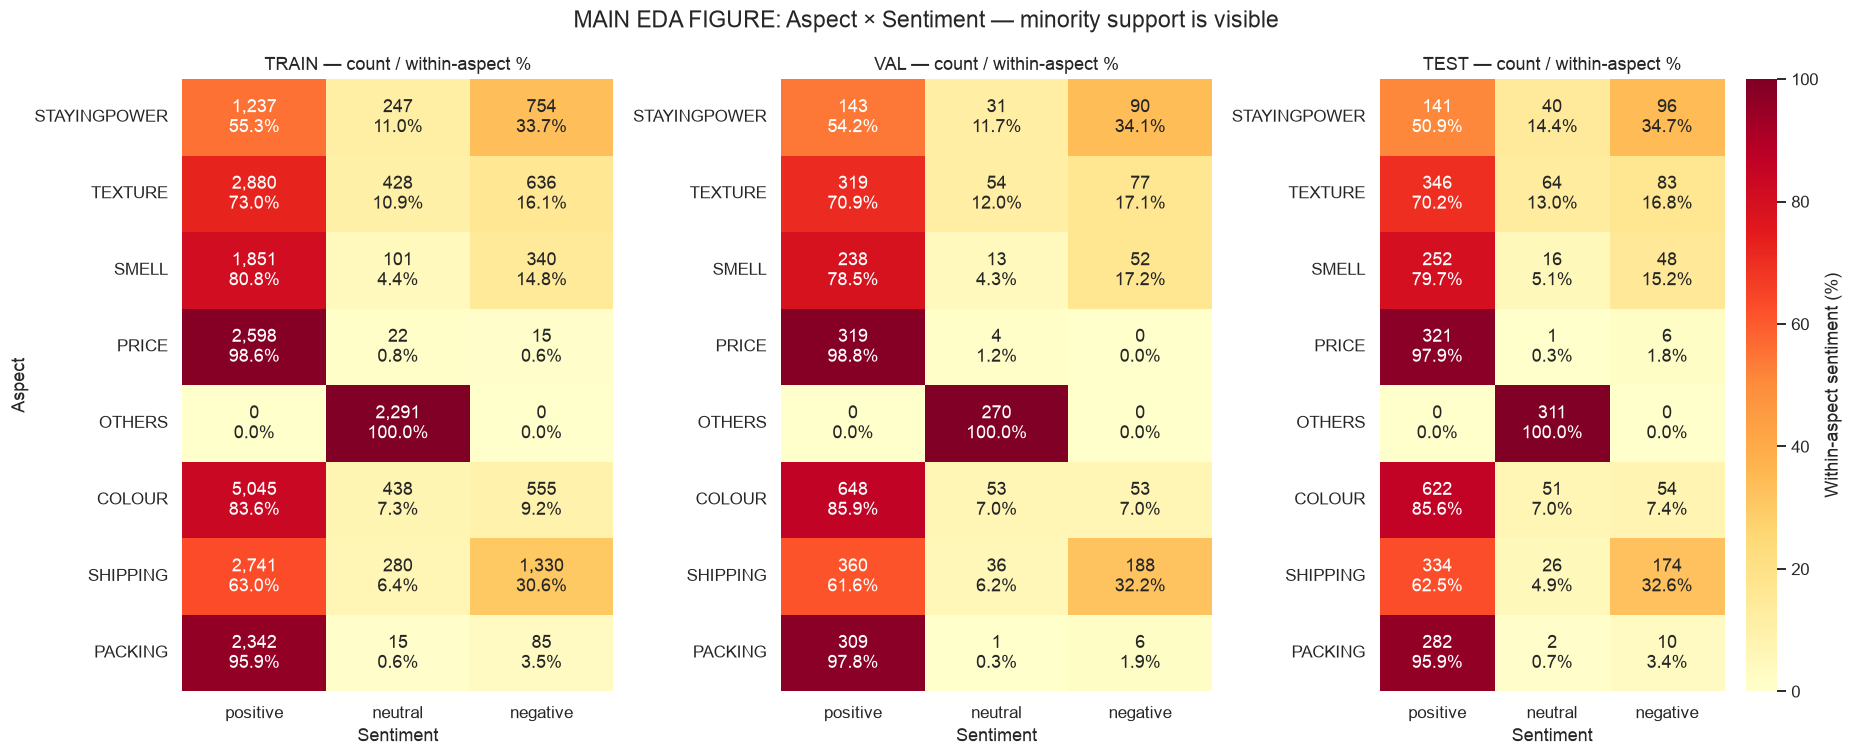

,split,aspect,sentiment,count,within_aspect_pct
0,train,stayingpower,positive,1237,55.273
1,train,stayingpower,neutral,247,11.037
2,train,stayingpower,negative,754,33.691
3,train,texture,positive,2880,73.022
4,train,texture,neutral,428,10.852
5,train,texture,negative,636,16.126
6,train,smell,positive,1851,80.759
7,train,smell,neutral,101,4.407
8,train,smell,negative,340,14.834
9,train,price,positive,2598,98.596


,split,aspect,support,majority,absent_classes,IR_3classes,IR_observed_classes
0,train,stayingpower,2238,positive,0,5.008,5.008
1,train,texture,3944,positive,0,6.729,6.729
2,train,smell,2292,positive,0,18.327,18.327
3,train,price,2635,positive,0,173.200,173.200
4,train,others,2291,neutral,2,inf,1.000
5,train,colour,6038,positive,0,11.518,11.518
6,train,shipping,4351,positive,0,9.789,9.789
7,train,packing,2442,positive,0,156.133,156.133
8,val,stayingpower,264,positive,0,4.613,4.613
9,val,texture,450,positive,0,5.907,5.907


Smallest train aspect × sentiment cells (7 core aspects):


,split,aspect,sentiment,count,within_aspect_pct
11,train,price,negative,15,0.569
22,train,packing,neutral,15,0.614
10,train,price,neutral,22,0.835
23,train,packing,negative,85,3.481
7,train,smell,neutral,101,4.407
1,train,stayingpower,neutral,247,11.037
19,train,shipping,neutral,280,6.435
8,train,smell,negative,340,14.834
4,train,texture,neutral,428,10.852
16,train,colour,neutral,438,7.254


Absent val/test core classes:


,split,aspect,sentiment,count,within_aspect_pct
35,val,price,negative,0,0.0


,scope,split,constant_prediction,micro_F1,weighted_F1,macro_F1_fixed3,negative_recall
0,all_8_aspects,train,positive,0.7127,0.5931,0.2774,0.0
1,all_8_aspects,val,positive,0.7157,0.5971,0.2781,0.0
2,all_8_aspects,test,positive,0.7006,0.5773,0.2747,0.0
3,exclude_OTHERS,train,positive,0.7809,0.6848,0.2923,0.0
4,exclude_OTHERS,val,positive,0.7802,0.6839,0.2922,0.0
5,exclude_OTHERS,test,positive,0.7740,0.6754,0.2909,0.0
6,stayingpower,train,positive,0.5527,0.3935,0.2373,0.0
7,texture,train,positive,0.7302,0.6164,0.2814,0.0
8,smell,train,positive,0.8076,0.7216,0.2979,0.0
9,price,train,positive,0.9860,0.9790,0.3310,0.0


**Diễn giải:** baseline hằng majority có Recall-Negative = 0 khi majority là Positive, nhưng Weighted-F1 vẫn có thể cao ở PRICE/PACKING. Đây là ví dụ toán học từ support, chưa phải kết quả mô hình. Paper §5.3 dùng weighted averages và Table 6 báo PRICE-Negative, PACKING-Neutral F1 bằng 0 trong STL. [Nguồn](https://aclanthology.org/2022.paclic-1.84.pdf).

In [15]:
aspect_sentiment_percent = {s:m.div(m.sum(axis=1),axis=0)*100 for s,m in aspect_sentiment_counts.items()}
fig, axes = plt.subplots(1,3,figsize=(17,7))
for s,ax in zip(SPLITS,axes):
    counts = aspect_sentiment_counts[s]
    pct = aspect_sentiment_percent[s]
    annotations = pd.DataFrame([[f'{counts.loc[a,k]:,}\n{pct.loc[a,k]:.1f}%'
                                  for k in SENTIMENTS] for a in ASPECTS],index=ASPECTS,columns=SENTIMENTS)
    # Convert the literal backslash-n above to a display newline.
    annotations = annotations.map(lambda x:x.replace('\\n','\n'))
    sns.heatmap(pct,annot=annotations,fmt='',vmin=0,vmax=100,cmap='YlOrRd',ax=ax,
                cbar=s=='test',cbar_kws={'label':'Within-aspect sentiment (%)'})
    ax.set_title(f'{s.upper()} — count / within-aspect %')
    ax.set_xlabel('Sentiment'); ax.set_ylabel('Aspect' if s=='train' else '')
    ax.set_yticklabels([a.upper() for a in ASPECTS],rotation=0)
fig.suptitle('MAIN EDA FIGURE: Aspect × Sentiment — minority support is visible',fontsize=15)
plt.tight_layout()
FIGURE_DIR = DATA_DIR.parent / 'reports' / 'eda'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE_DIR / 'aspect_sentiment_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

as_rows=[]
ir_rows=[]
for s in SPLITS:
    for a in ASPECTS:
        c=aspect_sentiment_counts[s].loc[a]; positive_counts=c[c>0]
        ir_rows.append({'split':s,'aspect':a,'support':int(c.sum()),'majority':c.idxmax(),
                        'absent_classes':int(c.eq(0).sum()),
                        'IR_3classes':c.max()/c.min() if c.min() else np.inf,
                        'IR_observed_classes':positive_counts.max()/positive_counts.min() if len(positive_counts) else np.nan})
        for k in SENTIMENTS:
            as_rows.append({'split':s,'aspect':a,'sentiment':k,'count':int(c[k]),
                            'within_aspect_pct':aspect_sentiment_percent[s].loc[a,k]})
aspect_sentiment_table=pd.DataFrame(as_rows)
display(aspect_sentiment_table.round(3))
display(pd.DataFrame(ir_rows).round(3))
print('Smallest train aspect × sentiment cells (7 core aspects):')
display(aspect_sentiment_table.query("split=='train' and aspect!='others'").sort_values('count').head(10).round(3))
print('Absent val/test core classes:')
display(aspect_sentiment_table.query("split!='train' and aspect!='others' and count==0"))

# Analytical majority-only baseline, NOT a fitted model or an evaluation of a DL model.
# For always-majority predictions: F1_majority=2p/(1+p); other fixed classes have F1=0.
majority_rows=[]
for scope,aspects in [('all_8_aspects',ASPECTS),('exclude_OTHERS',CORE_ASPECTS)]:
    for s in SPLITS:
        c=aspect_sentiment_counts[s].loc[aspects].sum(); p=c.max()/c.sum(); f1=2*p/(1+p)
        majority_rows.append({'scope':scope,'split':s,'constant_prediction':c.idxmax(),
                              'micro_F1':p,'weighted_F1':p*f1,'macro_F1_fixed3':f1/3,
                              'negative_recall':1.0 if c.idxmax()=='negative' else 0.0})
for a in CORE_ASPECTS:
    c=aspect_sentiment_counts['train'].loc[a]; p=c.max()/c.sum(); f1=2*p/(1+p)
    majority_rows.append({'scope':a,'split':'train','constant_prediction':c.idxmax(),
                          'micro_F1':p,'weighted_F1':p*f1,'macro_F1_fixed3':f1/3,
                          'negative_recall':1.0 if c.idxmax()=='negative' else 0.0})
majority_demo=pd.DataFrame(majority_rows)
display(majority_demo.round(4))
display(Markdown('**Diễn giải:** baseline hằng majority có Recall-Negative = 0 khi majority là Positive, '
                 'nhưng Weighted-F1 vẫn có thể cao ở PRICE/PACKING. Đây là ví dụ toán học từ support, '
                 'chưa phải kết quả mô hình. Paper §5.3 dùng weighted averages và Table 6 báo PRICE-Negative, '
                 'PACKING-Neutral F1 bằng 0 trong STL. [Nguồn](https://aclanthology.org/2022.paclic-1.84.pdf).'))


## 10. Review length × label

Một review có thể đồng thời Positive và Negative. Không gán majority sentiment thành ground truth của review.
Bảng đầu dùng **labeled cells**: cùng review xuất hiện một lần cho mỗi aspect có nhãn.
Bảng `unique_review_any_sentiment` dùng một review một lần trong mỗi nhóm sentiment; các nhóm vẫn overlap.
Phân tích CI/effect size chỉ so sánh hai nhóm **disjoint**: positive-only và negative-only trên 7 core aspects.
Loại OTHERS khỏi so sánh này để tránh nhầm neutral của spam với neutral của sản phẩm.


,split,scope,unit,sentiment,metric,n,mean,median,std,P95
0,train,all_8,aspect_sentiment_cells,positive,character_count,18694,104.23,86.0,52.89,220.00
1,train,all_8,aspect_sentiment_cells,positive,word_count,18694,23.35,20.0,12.54,50.00
2,train,all_8,unique_review_any_sentiment,positive,character_count,9735,99.94,83.0,50.33,206.00
3,train,all_8,unique_review_any_sentiment,positive,word_count,9735,22.26,19.0,12.04,48.00
4,train,all_8,aspect_sentiment_cells,neutral,character_count,3822,105.15,82.0,69.19,273.00
5,train,all_8,aspect_sentiment_cells,neutral,word_count,3822,20.96,17.0,17.05,59.00
6,train,all_8,unique_review_any_sentiment,neutral,character_count,3669,103.60,80.0,68.84,270.00
7,train,all_8,unique_review_any_sentiment,neutral,word_count,3669,20.52,17.0,16.94,59.00
8,train,all_8,aspect_sentiment_cells,negative,character_count,3715,115.58,97.0,57.91,242.00
9,train,all_8,aspect_sentiment_cells,negative,word_count,3715,26.29,22.0,13.81,56.00


character_count                       word_count  \
                                  count    mean median    std      count   
group                                                                      
mixed/neutral/unlabeled            5859  106.47   86.0  63.54       5859   
negative-only                       657   99.01   83.0  48.42        657   
positive-only                      6465   91.34   77.0  43.60       6465   

                                              
                          mean median    std  
group                                         
mixed/neutral/unlabeled  22.30   19.0  15.65  
negative-only            22.04   19.0  11.82  
positive-only            20.07   17.0  10.51

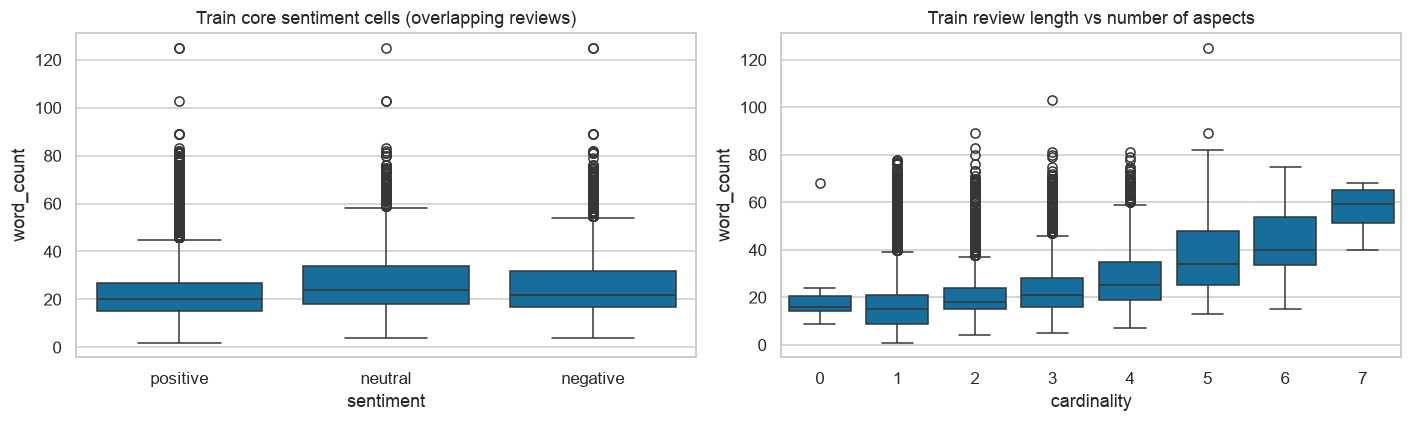

,n,mean_words,median_words,mean_chars
cardinality,,,,
0,14,20.21,16.0,92.93
1,5231,17.49,15.0,88.56
2,3807,20.81,18.0,94.01
3,2657,24.23,21.0,106.90
4,989,28.85,25.0,126.14
5,243,37.92,34.0,165.25
6,36,43.22,40.0,195.11
7,4,56.75,59.5,239.25


Train Spearman rho, whitespace length vs cardinality: 0.3631


,aspect,sentiment,n,mean_words,median_words
0,colour,negative,555,26.65,22.0
1,colour,neutral,438,28.70,24.0
2,colour,positive,5045,22.74,19.0
3,packing,negative,85,32.12,27.0
4,packing,neutral,15,26.60,25.0
5,packing,positive,2342,22.05,18.0
6,price,negative,15,29.73,25.0
7,price,neutral,22,30.09,25.0
8,price,positive,2598,24.74,20.0
9,shipping,negative,1330,24.84,21.0


,metric,positive_only_n,negative_only_n,negative_minus_positive_mean,bootstrap95_low,bootstrap95_high,cohen_d_negative_minus_positive,cliff_delta
0,character_count,6465,657,7.6677,3.9851,11.8831,0.1740,0.1140
1,word_count,6465,657,1.9709,1.0331,2.9249,0.1853,0.1083


**Length observation (train, disjoint groups):** negative-only dài hơn positive-only trung bình **1.97 whitespace tokens**; bootstrap 95% CI **[1.03, 2.92]**, Cohen d **0.185**, Cliff delta **0.108**. Cardinality/length Spearman rho **0.363**. CI này thể hiện khác biệt trong hai nhóm đã chọn, không chứng minh sentiment gây tăng độ dài hoặc model dùng shortcut. Cần giữ limitation này và kiểm tra baseline chỉ dùng length.

**Bias limitation:** CI là descriptive review-bootstrap (1.000 resamples, seed 42), không điều chỉnh dependence do duplicate/template; các so sánh không phải causal. Chiều dài có thể liên quan cardinality/aspect mix. Cần length-only baseline và đánh giá theo length bins trên validation để xác nhận shortcut, chưa suy ra model đã khai thác nó.

In [16]:
cell_tables={}
length_label_rows=[]
for s in SPLITS:
    df=datasets[s].reset_index(names='source_row_0based')
    long=df.melt(id_vars=['source_row_0based',TEXT_COL],value_vars=ASPECTS,
                 var_name='aspect',value_name='sentiment')
    long=long[long.sentiment.isin(SENTIMENTS)].copy()
    long['character_count']=long[TEXT_COL].str.len()
    long['word_count']=long[TEXT_COL].str.split().str.len()
    cell_tables[s]=long
    for scope,aspects in [('all_8',ASPECTS),('core_7',CORE_ASPECTS)]:
        for k in SENTIMENTS:
            subset=long[long.aspect.isin(aspects)&long.sentiment.eq(k)]
            for unit,data in [('aspect_sentiment_cells',subset),
                              ('unique_review_any_sentiment',subset.drop_duplicates('source_row_0based'))]:
                for metric in ['character_count','word_count']:
                    x=data[metric]
                    length_label_rows.append({'split':s,'scope':scope,'unit':unit,'sentiment':k,
                                              'metric':metric,'n':len(x),'mean':x.mean(),'median':x.median(),
                                              'std':x.std(),'P95':x.quantile(.95)})
length_by_sentiment=pd.DataFrame(length_label_rows)
display(length_by_sentiment.round(2))

train_df=datasets['train']
core_labels=train_df[CORE_ASPECTS]
has={k:core_labels.eq(k).any(axis=1) for k in SENTIMENTS}
pure_positive=has['positive']&~has['neutral']&~has['negative']
pure_negative=has['negative']&~has['neutral']&~has['positive']
length_comparison=train_lengths[['character_count','word_count']].copy()
length_comparison['group']=np.select([pure_positive,pure_negative],['positive-only','negative-only'],default='mixed/neutral/unlabeled')
display(length_comparison.groupby('group')[['character_count','word_count']].agg(['count','mean','median','std']).round(2))
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.boxplot(data=cell_tables['train'].query("aspect!='others'"),x='sentiment',y='word_count',order=SENTIMENTS,ax=axes[0])
axes[0].set_title('Train core sentiment cells (overlapping reviews)')
card_length=train_lengths[['character_count','word_count']].assign(cardinality=cardinality['train'])
sns.boxplot(data=card_length,x='cardinality',y='word_count',ax=axes[1])
axes[1].set_title('Train review length vs number of aspects')
plt.tight_layout(); plt.show()
display(card_length.groupby('cardinality').agg(n=('word_count','size'),mean_words=('word_count','mean'),
                                              median_words=('word_count','median'),mean_chars=('character_count','mean')).round(2))
length_cardinality_rho=card_length['word_count'].rank().corr(card_length['cardinality'].rank())
print('Train Spearman rho, whitespace length vs cardinality:',round(length_cardinality_rho,4))

within_aspect_length=cell_tables['train'].query("aspect!='others'").groupby(['aspect','sentiment']).agg(
    n=('word_count','size'),mean_words=('word_count','mean'),median_words=('word_count','median')).reset_index()
display(within_aspect_length.round(2))

# Review bootstrap; group samples are disjoint. Duplicate/template dependence is not corrected.
rng=np.random.default_rng(42)
effect_rows=[]
for metric in ['character_count','word_count']:
    a=train_lengths.loc[pure_positive,metric].to_numpy(float)
    b=train_lengths.loc[pure_negative,metric].to_numpy(float)
    if not len(a) or not len(b):
        continue
    boot=np.array([rng.choice(b,size=len(b),replace=True).mean()-rng.choice(a,size=len(a),replace=True).mean()
                   for _ in range(1000)])
    pooled=np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(b)-1)*b.var(ddof=1))/(len(a)+len(b)-2))
    # Cliff delta >0 means negative-only tends longer; ties contribute zero.
    sorted_a=np.sort(a)
    cliff=(np.searchsorted(sorted_a,b,'left').sum()-(len(a)-np.searchsorted(sorted_a,b,'right')).sum())/(len(a)*len(b))
    effect_rows.append({'metric':metric,'positive_only_n':len(a),'negative_only_n':len(b),
                        'negative_minus_positive_mean':b.mean()-a.mean(),
                        'bootstrap95_low':np.quantile(boot,.025),'bootstrap95_high':np.quantile(boot,.975),
                        'cohen_d_negative_minus_positive':(b.mean()-a.mean())/pooled if pooled else np.nan,
                        'cliff_delta':cliff})
length_effects=pd.DataFrame(effect_rows)
display(length_effects.round(4))
word_effect=length_effects.query("metric=='word_count'").iloc[0]
display(Markdown(f'**Length observation (train, disjoint groups):** negative-only dài hơn positive-only '
                 f'trung bình **{word_effect.negative_minus_positive_mean:.2f} whitespace tokens**; '
                 f'bootstrap 95% CI **[{word_effect.bootstrap95_low:.2f}, {word_effect.bootstrap95_high:.2f}]**, '
                 f'Cohen d **{word_effect.cohen_d_negative_minus_positive:.3f}**, '
                 f'Cliff delta **{word_effect.cliff_delta:.3f}**. '
                 f'Cardinality/length Spearman rho **{length_cardinality_rho:.3f}**. '
                 'CI này thể hiện khác biệt trong hai nhóm đã chọn, không chứng minh sentiment gây tăng độ dài '
                 'hoặc model dùng shortcut. Cần giữ limitation này và kiểm tra baseline chỉ dùng length.'))
display(Markdown('**Bias limitation:** CI là descriptive review-bootstrap (1.000 resamples, seed 42), '
                 'không điều chỉnh dependence do duplicate/template; các so sánh không phải causal. '
                 'Chiều dài có thể liên quan cardinality/aspect mix. Cần length-only baseline và '
                 'đánh giá theo length bins trên validation để xác nhận shortcut, chưa suy ra model đã khai thác nó.'))


## 11. Lexical exploration — frequency, bigrams, TF-IDF

Lowercase chỉ trong phép phân tích lexical. Token regex giữ chữ Unicode, không word-segment tiếng Việt;
unigram thường là âm tiết, bigram là hai token kề nhau (có thể đi qua dấu câu). Không thay đổi review nguồn.
Top frequency toàn **full** chỉ mô tả; vocabulary và IDF cho phân tích theo label được fit trên **train**.
Mỗi review đếm một lần trong từng nhóm; nhóm sentiment/aspect có thể overlap.
Từ phổ biến theo nhóm không đồng nghĩa marker riêng của nhóm, vì vậy báo cáo thêm document-frequency enrichment.


In [17]:
LEX_STOPWORDS={'và','là','của','cho','có','thì','mình','với','nha','ạ','này','cũng'}
print('Stopwords for ranked label terms only:',sorted(LEX_STOPWORDS))
print('Negation tokens (không/chưa/chẳng/ko/k) are retained.')
def lexical_tokens(text):
    return re.findall(r'[^\W\d_]+',text.lower(),flags=re.UNICODE)
def frequency_table(texts,bigram=False):
    total=Counter(); docfreq=Counter()
    for text in texts:
        ts=lexical_tokens(text)
        terms=[' '.join(pair) for pair in zip(ts,ts[1:])] if bigram else ts
        total.update(terms); docfreq.update(set(terms))
    return pd.DataFrame([{'term':t,'frequency':n,'review_df':docfreq[t]} for t,n in total.most_common(25)])
print('Full top unigrams (no stopword filtering):'); display(frequency_table(datasets['full'][TEXT_COL]))
print('Full top bigrams (no stopword filtering):'); display(frequency_table(datasets['full'][TEXT_COL],True))

train_token_lists=[lexical_tokens(t) for t in train_df[TEXT_COL]]
doc_counts=[Counter(ts) for ts in train_token_lists]
train_dfreq=Counter(t for c in doc_counts for t in c)
vocabulary={t for t,n in train_dfreq.items() if n>=3 and t not in LEX_STOPWORDS}
idf={t:np.log((1+len(train_df))/(1+train_dfreq[t]))+1 for t in vocabulary}
tfidf_docs=[]
for c in doc_counts:
    weights={t:(1+np.log(n))*idf[t] for t,n in c.items() if t in vocabulary}
    norm=np.sqrt(sum(v*v for v in weights.values()))
    tfidf_docs.append({t:v/norm for t,v in weights.items()} if norm else {})
label_masks={f'sentiment_{k}_all8':train_df[ASPECTS].eq(k).any(axis=1).to_numpy() for k in SENTIMENTS}
label_masks['sentiment_neutral_core7']=has['neutral'].to_numpy()
label_masks.update({f'aspect_{a}':presence['train'][a].astype(bool).to_numpy() for a in ASPECTS})
lexical_rows=[]
for group,mask in label_masks.items():
    indices=np.flatnonzero(mask); n=len(indices); outside_n=len(mask)-n
    freq=Counter(); group_df=Counter(); score=Counter()
    for i in indices:
        freq.update(doc_counts[i]); group_df.update(doc_counts[i].keys()); score.update(tfidf_docs[i])
    ranked=sorted(score,key=lambda t:score[t]/max(n,1),reverse=True)[:15]
    for term in ranked:
        gdf=group_df[term]; outside_df=train_dfreq[term]-gdf
        enrich=((gdf+1)/(n+2))/((outside_df+1)/(outside_n+2)) if outside_n else np.nan
        lexical_rows.append({'group':group,'group_reviews':n,'term':term,'frequency':freq[term],
                             'review_df':gdf,'review_df_pct':100*gdf/n if n else np.nan,
                             'mean_TFIDF':score[term]/n if n else np.nan,'DF_enrichment_smoothed':enrich})
lexical_top_terms=pd.DataFrame(lexical_rows)
for group in label_masks:
    print(group)
    display(lexical_top_terms.query('group==@group').round(4))

expected_terms={'colour':['màu','đẹp'],'texture':['khô','mịn'],'shipping':['giao','nhanh']}
term_evidence=[]
for aspect,terms in expected_terms.items():
    mask=presence['train'][aspect].astype(bool).to_numpy()
    for term in terms:
        df_g=sum(term in doc_counts[i] for i in np.flatnonzero(mask))
        df_o=train_dfreq[term]-df_g
        term_evidence.append({'aspect':aspect,'term':term,'aspect_review_pct':100*df_g/mask.sum(),
                              'outside_aspect_pct':100*df_o/(~mask).sum(),
                              'DF_enrichment':((df_g+1)/(mask.sum()+2))/((df_o+1)/((~mask).sum()+2))})
display(pd.DataFrame(term_evidence).round(3))
display(Markdown('**Diễn giải:** so sánh frequency, TF-IDF và enrichment giúp tìm lexical cues, '
                 'nhưng co-occurrence aspect và annotation artifacts có thể tạo association. '
                 'Bigrams/TF-IDF là ứng viên baseline; EDA chưa chứng minh DL vượt baseline. '
                 'Neutral-all8 cần đọc cùng neutral-core7 vì OTHERS là spam.'))


Stopwords for ranked label terms only: ['cho', 'có', 'cũng', 'của', 'là', 'mình', 'nha', 'này', 'thì', 'và', 'với', 'ạ']
Negation tokens (không/chưa/chẳng/ko/k) are retained.
Full top unigrams (no stopword filtering):


,term,frequency,review_df
0,son,11841,8862
1,màu,10611,8039
2,đẹp,7367,6403
3,hàng,6821,5630
4,chất,5043,4627
5,giao,4857,4600
6,mua,4516,3891
7,nên,4253,3718
8,lắm,4149,3616
9,rất,3983,3086


Full top bigrams (no stopword filtering):


,term,frequency,review_df
0,giao hàng,3379,3348
1,đóng gói,2444,2432
2,sản phẩm,2169,1834
3,chất lượng,1815,1755
4,chất son,1755,1721
5,màu đẹp,1706,1678
6,hàng nhanh,1701,1692
7,nên mua,1503,1452
8,son đẹp,1486,1465
9,cẩn thận,1298,1292


sentiment_positive_all8


...

,group,group_reviews,term,frequency,review_df,review_df_pct,mean_TFIDF,DF_enrichment_smoothed
150,aspect_shipping,4351,giao,3800,3601,82.7626,0.1241,90.4148
151,aspect_shipping,4351,hàng,4331,3527,81.0618,0.1200,7.3565
152,aspect_shipping,4351,nhanh,2401,2336,53.6888,0.0937,15.8708
153,aspect_shipping,4351,son,3042,2392,54.9759,0.0610,1.0056
154,aspect_shipping,4351,đẹp,2028,1798,41.3238,0.0553,1.0662
155,aspect_shipping,4351,màu,2543,2084,47.8970,0.0551,0.9401
156,aspect_shipping,4351,gói,1374,1356,31.1652,0.0540,2.6856
157,aspect_shipping,4351,lâu,1341,1291,29.6713,0.0538,7.2374
158,aspect_shipping,4351,đóng,1221,1217,27.9706,0.0511,2.9030
159,aspect_shipping,4351,shop,1315,1099,25.2586,0.0453,2.3430


aspect_packing


,group,group_reviews,term,frequency,review_df,review_df_pct,mean_TFIDF,DF_enrichment_smoothed
165,aspect_packing,2442,gói,2285,2248,92.0557,0.1593,88.1815
166,aspect_packing,2442,đóng,1963,1948,79.7707,0.1464,83.2283
167,aspect_packing,2442,hàng,2071,1617,66.2162,0.0998,2.4392
168,aspect_packing,2442,thận,1003,996,40.7862,0.0946,76.7870
169,aspect_packing,2442,cẩn,996,990,40.5405,0.0942,76.3249
170,aspect_packing,2442,giao,1317,1254,51.3514,0.0773,2.2312
171,aspect_packing,2442,nhanh,988,966,39.5577,0.0685,2.5094
172,aspect_packing,2442,đẹp,1272,1098,44.9631,0.0608,1.1715
173,aspect_packing,2442,chắn,569,555,22.7273,0.0595,25.5110
174,aspect_packing,2442,chắc,628,603,24.6929,0.0589,8.5133


,aspect,term,aspect_review_pct,outside_aspect_pct,DF_enrichment
0,colour,màu,97.069,8.930,10.854
1,colour,đẹp,54.819,26.401,2.076
2,texture,khô,17.672,0.387,44.414
3,texture,mịn,39.782,0.841,46.706
4,shipping,giao,82.763,0.904,90.415
5,shipping,nhanh,53.689,3.372,15.871


**Diễn giải:** so sánh frequency, TF-IDF và enrichment giúp tìm lexical cues, nhưng co-occurrence aspect và annotation artifacts có thể tạo association. Bigrams/TF-IDF là ứng viên baseline; EDA chưa chứng minh DL vượt baseline. Neutral-all8 cần đọc cùng neutral-core7 vì OTHERS là spam.

## 12. Manual qualitative inspection

25 review random trên train (`random.Random(42)`), rồi thêm mẫu có chủ đích theo multi-aspect,
Negative, Neutral, rare aspect, noise, longest và không aspect. Đây là **manual EDA notes**, không relabel.
Rare aspect lấy từ tần suất train; rare aspect–sentiment bổ sung PRICE-Negative và PACKING-Neutral.
Các heuristic negation/typo/sarcasm chỉ tạo candidate, không chứng minh hiện tượng đã xuất hiện.


In [18]:
import random
random_ids=random.Random(42).sample(range(len(train_df)),25)
manual_notes={
10476:('negation? no; service complaint; repeated letters','shipping-negative hợp lý cho trả lời chậm; giao nhầm màu có thể cần xem COLOUR guideline.'),
1824:('negation; noisy suffix; complaint','smell-negative phù hợp mùi nồng; câu chất lượng quá tệ có thể cần xem TEXTURE.'),
409:('multi-aspect; noisy suffix','colour-positive và shipping-positive có căn cứ trực tiếp.'),
12149:('mixed evaluation within colour','colour-neutral có thể dựa trên mô tả đỏ đậm; lời khen chung không nhất thiết colour-positive.'),
4506:('generic praise; OTHERS','OTHERS cần đối chiếu tiêu chí spam/generic không aspect, chưa kết luận sai.'),
4012:('multi-aspect; sentiment phrase to multiple aspects','smell/shipping/packing-positive có căn cứ; màu ok nhưng colour blank cần review guideline.'),
3657:('mixed opinion across product variants; slang','colour-positive tổng quát; ý kiến hai màu khác nhau làm aggregation khó.'),
2286:('contrast; implicit staying power','texture/colour-positive phù hợp; dễ bị lem có thể là stayingpower chưa gán.'),
12066:('multi-aspect; emoji','price/shipping-positive có căn cứ trực tiếp.'),
1679:('negation; expectation mismatch; slang','colour-negative phù hợp màu không như swatch.'),
11087:('uncertainty; negation; teencode','stayingpower-neutral do chưa thử; smell/colour-positive hợp lý.'),
12135:('mixed sentiment within texture','mềm mịn nhưng hơi khô môi: texture-positive cần xem quy tắc aggregation.'),
8935:('mixed sentiment across aspects; expectation reversal','positive cho stayingpower/smell/price, negative cho shipping phù hợp.'),
1424:('typo; noisy suffix; implicit staying power','stayingpower-positive từ son lì; son lên môi đẹp chưa chắc riêng colour.'),
9674:('literal NAN; placeholder/spam','OTHERS-neutral khớp vai trò spam; không coi literal NAN là null tự động.'),
6912:('multi-aspect; negation; mixed sentiment','4 nhãn hợp lý: nhanh trôi, chất ổn, sale và màu khác ảnh.'),
520:('generic praise; repeated gratitude','OTHERS theo tiêu chí spam/generic cần guideline; không có aspect cụ thể rõ.'),
488:('mixed phrase; complaint softened','shipping-negative hợp lý dù tác giả nói ksao.'),
1535:('5 aspects; contrast; multiple complaints','smell/price/colour-positive và shipping/packing-negative có căn cứ.'),
3582:('context from previous seller; multi-aspect','shipping/packing-positive cho đơn hiện tại; bị lừa là trải nghiệm shop khác.'),
3811:('noise suffix','colour-positive có căn cứ rõ.'),
8279:('mixed product context; emoji; complaint softened','shipping-negative hợp lý; mùi nước hoa không nhất thiết là SMELL của son.'),
9863:('typo; noise suffix','stayingpower-positive từ bền màu hợp lý.'),
434:('multi-aspect; contrast','4 nhãn hợp lý; negative stayingpower từ nhanh trôi.'),
9195:('uncertainty; implicit evaluation','texture-neutral do chưa thử; smell-positive cần xem mùi hơi ngọt có đủ polarity không.')}
def format_labels(i):
    return ', '.join(f'{a}:{train_df.loc[i,a]}' for a in ASPECTS if train_df.loc[i,a]) or '(all blank)'
random_inspection=pd.DataFrame([{'source_row_0based':i,'review':train_df.loc[i,TEXT_COL],
                                'labels':format_labels(i),'difficulty':manual_notes[i][0],
                                'manual_observation':manual_notes[i][1]} for i in random_ids])
with pd.option_context('display.max_colwidth',None,'display.max_rows',40):
    display(random_inspection)

rare_aspect=train_frequency.iloc[-1]['aspect']
candidate_groups={
    'multi_aspect':cardinality['train'].ge(3),
    'negative':train_df[ASPECTS].eq('negative').any(axis=1),
    'neutral_core7':has['neutral'],
    'rare_aspect_'+rare_aspect:presence['train'][rare_aspect].eq(1),
    'noisy_text':noise_flags['train'][['repeated_letter_3plus','filler_candidate_no_vowel','url']].any(axis=1),
    'PRICE_negative':train_df['price'].eq('negative'),
    'PACKING_neutral':train_df['packing'].eq('neutral'),
    'zero_aspect':cardinality['train'].eq(0)}
deliberate_rows=[]
for group,mask in candidate_groups.items():
    pool=mask.index[mask].tolist()
    for i in random.Random(42).sample(pool,min(3,len(pool))):
        deliberate_rows.append({'reason':group,'source_row_0based':i,'review':train_df.loc[i,TEXT_COL],
                                'labels':format_labels(i)})
for i in train_lengths.nlargest(3,'character_count').index:
    deliberate_rows.append({'reason':'longest_characters','source_row_0based':i,
                            'review':train_df.loc[i,TEXT_COL],'labels':format_labels(i)})
deliberate_notes={
8560:'4 nhãn positive đều có căn cứ rõ (màu, bọc hàng, mùi đào, mịn).',
1605:'Colour/packing-positive và shipping-negative phù hợp câu giao hàng lâu.',
353:'Stayingpower/shipping-negative hợp lý; smell-positive từ ngọt có thể cần guideline.',
10563:'Typo laua/xinj nhưng có tín hiệu bền màu và texture; shipping-negative trực tiếp.',
1851:'Các nhãn phù hợp; 5 sao không xoá complaint ship lâu.',
400:'Packing-positive dù mở hộp khó; cần tách bao gói khỏi tiện mở; nhãn khác có căn cứ.',
12362:'Stayingpower-neutral phù hợp lì bình thường; emoji không đổi nhãn tự động.',
2307:'Texture-neutral nhưng không có phrase texture rõ; có thể dùng son lì, cần review scope.',
529:'Shipping-neutral có thể là aggregation giao lâu nhưng shipper dễ thương; mixed trong một aspect.',
2597:'Stayingpower-neutral mặc dù có lì; cần xem guideline. Packing từ bao bì có thể khác vỏ sản phẩm.',
600:'Stayingpower-neutral do chưa test; shipping/texture-positive có căn cứ; review xen quảng cáo.',
6487:'Stayingpower-negative và smell/price-positive có căn cứ; vỏ sản phẩm không nhất thiết packing.',
2490:'OTHERS dù có lời khen chung; spam/generic criterion cần guideline, không tự sửa.',
507:'3 positive có căn cứ; không gán colour chỉ từ son đẹp.',
6029:'Colour-positive rõ; repeated letters tăng sắc thái khen.',
9177:'Price-negative rõ ở đắt; colour-positive từ màu này thì cũng dx có thể cần kiểm tra scope.',
1136:'Price-negative từ tốn tiền, packing-positive rõ; giao lâu nhưng shipping blank là candidate.',
682:'Price-negative do đối chiếu nơi khác sale rẻ hơn; aspect giá được hiểu theo context.',
10520:'Packing-neutral từ tạm được; shipping-neutral từ giao đúng phân loại cần guideline; 3 positive có căn cứ.',
2387:'Packing-neutral vì chỉ có đóng gói không polarity; quality tốt không nhất thiết texture cụ thể.',
294:'Packing-neutral: không dùng túi bóng nhưng không móp méo; aggregation hai vế cần guideline.',
8624:'All blank dù đóng gói chắc chắn/xinh; candidate missing packing annotation.',
3488:'All blank dù lời khen chất lượng/vỏ; cần guideline về texture và bao bì sản phẩm.',
1184:'All blank dù giao đúng màu/ưng; scope colour vs shipping cần adjudication.',
11983:'Review xen filler okok; stayingpower/price-positive có căn cứ, texture-neutral cần guideline.',
7937:'Negative stayingpower/shipping và positive price/colour hợp lý; texture có hai màu/chất khác nhau nên khó aggregate.',
2554:'Stayingpower-positive có căn cứ; colour-neutral có cả khen/chê; texture-neutral từ dễ sử dụng cần guideline.'}
deliberate_inspection=pd.DataFrame(deliberate_rows)
deliberate_inspection['manual_observation']=deliberate_inspection.source_row_0based.map(deliberate_notes)
if deliberate_inspection.manual_observation.isna().any():
    raise ValueError('Deliberate sample changed; manual notes require a fresh review.')
with pd.option_context('display.max_colwidth',None,'display.max_rows',40):
    display(deliberate_inspection)
print('Random sample:',len(random_inspection),'| deliberate records (may overlap):',len(deliberate_inspection))


,source_row_0based,review,labels,difficulty,manual_observation
0,10476,Giao nhầm màu son nhắn tin trả lời chậm chạpppppppppppppppp,shipping:negative,negation? no; service complaint; repeated letters,shipping-negative hợp lý cho trả lời chậm; giao nhầm màu có thể cần xem COLOUR guideline.
1,1824,K đẹp.mùi nồng kiểu gì gì .mua về mới thử thôi nhưng vứt rồi nói chung là mn đừng mua .chất lượng sản phẩm quá tệ.habahuabsjsisjsisjs jsbsnsjsnns iwhwjwiwjw baja,smell:negative,negation; noisy suffix; complaint,smell-negative phù hợp mùi nồng; câu chất lượng quá tệ có thể cần xem TEXTURE.
2,409,Giao nhanh hàng chính hãng màu này tôn da lắm nhé bzjnsjmsnks,"colour:positive, shipping:positive",multi-aspect; noisy suffix,colour-positive và shipping-positive có căn cứ trực tiếp.
3,12149,Hàng đẹp lắm. Mọi người nên mua nha. Màu này hơi thiên đỏ đậm....,colour:neutral,mixed evaluation within colour,colour-neutral có thể dựa trên mô tả đỏ đậm; lời khen chung không nhất thiết colour-positive.
4,4506,Hình ảnh mang tc minh hoạ. Mua shop nhiều rồi không phải bàn đến chất lượng nữa. Quá tuyệt.,others:neutral,generic praise; OTHERS,"OTHERS cần đối chiếu tiêu chí spam/generic không aspect, chưa kết luận sai."
5,4012,ship nhanh đóng gói chắc chắn vỏ đẹp lắmmm son có mùi thơm thích xỉu màu thì ok tuyệt,"smell:positive, shipping:positive, packing:positive",multi-aspect; sentiment phrase to multiple aspects,smell/shipping/packing-positive có căn cứ; màu ok nhưng colour blank cần review guideline.
6,3657,2 màu đều đẹp hết á mn mà bị cái son lên môi của tui cứ bị base hồng í 🥲nhưng cái màu 302 lên màu xinh hơn làm da trắng răng cũng trắng nữa còn màu 204 lên môi hơi bợt thích hợp dùng là base hơn,colour:positive,mixed opinion across product variants; slang,colour-positive tổng quát; ý kiến hai màu khác nhau làm aggregation khó.
7,2286,Son đánh lên mịn môi lắm\nMàu giống ảnh\nNhưng dễ bị lem\nSon nội địa nên chất lượng thế là ổn,"texture:positive, colour:positive",contrast; implicit staying power,texture/colour-positive phù hợp; dễ bị lem có thể là stayingpower chưa gán.
8,12066,"Giao hàng nhanh, , giá lại rẻ hơn các shop khác, rất đáng tiền, nếu có lần sau sẽ ủng hộ shop tiếp 👍","price:positive, shipping:positive",multi-aspect; emoji,price/shipping-positive có căn cứ trực tiếp.
9,1679,"mng nên cân nhắc trước khi mua nhé vì màu 21 mình thấy lên môi nó kh đc như màu swatch trên hình nha, lên môi mình nó ra sắc tím hồng rất đậm (đánh nhiều lớp), còn đánh mỏng nó sẽ ra hồng kiểu 10 giờ, kh có tí sắc đỏ nào.",colour:negative,negation; expectation mismatch; slang,colour-negative phù hợp màu không như swatch.


,reason,source_row_0based,review,labels,manual_observation
0,multi_aspect,8560,"Màu 402 kiểu đỏ nâu đậm hợp da lắm ạ\nBọc hàng cẩn thận, bao bọc nhìn xịn vch\nSon thơm mùi đào, chất son mịn lắm\nNên mua nha mn\nLsau ủng hộ shop típ","texture:positive, smell:positive, colour:positive, packing:positive","4 nhãn positive đều có căn cứ rõ (màu, bọc hàng, mùi đào, mịn)."
1,multi_aspect,1605,"Màu lên siêu xịn, gói hàng kĩ, đẹp và chắc chắn, hàng quốc tế nên giao hàng lâu","colour:positive, shipping:negative, packing:positive",Colour/packing-positive và shipping-negative phù hợp câu giao hàng lâu.
2,multi_aspect,353,Giao hàng lâu vì là Tết (3tuần)\nSon có mùi như chocolat ngọt\nSon không lì có nhiều dưỡng,"stayingpower:negative, smell:positive, shipping:negative",Stayingpower/shipping-negative hợp lý; smell-positive từ ngọt có thể cần guideline.
3,negative,10563,Công dụng: Son dep jd\r\nKết cấu: xinj\r\nĐộ bền màu: laua\r\nHàng quốc tế giao hơi lâu nhưng mà đẹp xịn đáng mua,"stayingpower:positive, texture:positive, shipping:negative",Typo laua/xinj nhưng có tín hiệu bền màu và texture; shipping-negative trực tiếp.
4,negative,1851,"Son lì, chất son ổn, màu lên siêu xinh, lần sau nhất định sẽ ủng hộ. Có điều shop nước ngoài nên ship khá lâu, nhưng vẫn ủng hộ shop 5* nha 😊","stayingpower:positive, texture:positive, colour:positive, shipping:negative",Các nhãn phù hợp; 5 sao không xoá complaint ship lâu.
5,negative,400,"Giao hàng hơi lâu. Đóng gói sp được nmà mở được cái hộp son ở ngoài hơi mệt=))) son mịn lắm,lên màu đẹp. Rất ưngg💕","texture:positive, colour:positive, shipping:negative, packing:positive",Packing-positive dù mở hộp khó; cần tách bao gói khỏi tiện mở; nhãn khác có căn cứ.
6,neutral_core7,12362,Son đẹp. Lì bình thường ạ. Sẽ ủng hộ thêm :))))))))) 👈🍀🛁🥲😍😝🙃🐣🤬🤬🛁🙃😃😘😂😂🥲🥲♥️🥲😘,stayingpower:neutral,Stayingpower-neutral phù hợp lì bình thường; emoji không đổi nhãn tự động.
7,neutral_core7,2307,Son đẹp chất son lì \nMàu 25 đẹp xỉu \nChuẩn bị hàng đóng gói hàng chắc chắn,"stayingpower:positive, texture:neutral, colour:positive, packing:positive","Texture-neutral nhưng không có phrase texture rõ; có thể dùng son lì, cần review scope."
8,neutral_core7,529,Công dụng: Hồng môi.\nKết cấu: ...\nĐộ bền màu: ....\nMềm mướt lắm ấy.Mình thấy đánh 1 lớp son dưỡng lên trước xong đánh son dễ tán hơn á.\nShip hơi lâu nhưng mà bù lại anh ship cưng xỉu luôn á trời.,"texture:positive, shipping:neutral",Shipping-neutral có thể là aggregation giao lâu nhưng shipper dễ thương; mixed trong một aspect.
9,rare_aspect_stayingpower,2597,Từ chất lượng đến bao bì của sản phẩm đều đẹp son lên màu chuẩn lì k bị khô môiii,"stayingpower:neutral, texture:positive, colour:positive, packing:positive",Stayingpower-neutral mặc dù có lì; cần xem guideline. Packing từ bao bì có thể khác vỏ sản phẩm.


Random sample: 25 | deliberate records (may overlap): 27


### Dạng khó đã thấy trong random sample

- **Negation và uncertainty:** row 11087 chưa dùng nên không biết độ bền; row 1679 màu không như swatch.
- **Mixed sentiment:** row 1535 khen màu/mùi/giá nhưng chê shipping/packing; row 12135 vừa mềm mịn vừa khô môi trong cùng TEXTURE.
- **Implicit aspect:** row 2286 “dễ bị lem” có thể liên quan staying power; cần guideline để xác định.
- **Context ownership:** row 3582 kể về shop cũ bị lừa nhưng khen shipping hiện tại; row 8279 đề cập thêm nước hoa ngoài son.
- **Typo/teencode và filler:** row 1424, 3811, 9863 có nhận xét hữu ích xen chuỗi ký tự vô nghĩa.
- **Sentiment phrase và scope:** row 4012 khen nhiều thuộc tính; “ok/tuyệt” cần gắn đúng aspect, không lan một sentiment cho mọi aspect.
- **Sarcasm:** chưa xác nhận ví dụ sarcasm rõ trong 25 random review; không tạo ví dụ hoặc gắn nhãn suy đoán.

Những dạng khó này là lý do **thử** contextual models. Chưa chứng minh DL cần thiết hoặc vượt TF-IDF;
cần baseline và evaluation theo challenge slices. Ghi chú label chỉ là observations, không ground truth mới.


## 13. Potential label-quality issues

Mở rộng audit đã có ở mục 2: duplicate text với nhiều label vectors **trong từng split**,
và candidate thiếu nhãn. Lexical cues không phải annotation rules: “màu/giao/khô” có thể là mô tả,
context của sản phẩm khác hoặc phủ định; không dùng để tự gán nhãn.


In [19]:
within_conflict_rows=[]
within_conflict_examples=[]
for s in SPLITS:
    for mode in ['exact_text','normalized_text']:
        df=datasets[s].copy()
        df['text_key']=df[TEXT_COL] if mode=='exact_text' else df[TEXT_COL].map(normalize_text)
        df=df[df['text_key'].str.strip().ne('')]
        df['label_vector']=list(df[ASPECTS].itertuples(index=False,name=None))
        groups=df.groupby('text_key').agg(rows=('text_key','size'),variants=('label_vector','nunique'))
        conflicts=groups.query('rows>1 and variants>1')
        within_conflict_rows.append({'split':s,'mode':mode,'conflicting_unique_texts':len(conflicts),
                                     'involved_rows':int(conflicts.rows.sum())})
        if len(conflicts):
            ex=df[df.text_key.isin(conflicts.head(3).index)][[TEXT_COL,*ASPECTS]].reset_index(names='source_row_0based')
            ex.insert(0,'mode',mode); ex.insert(0,'split',s); within_conflict_examples.append(ex)
within_conflicts=pd.DataFrame(within_conflict_rows)
display(within_conflicts)
train_conflicts=within_conflicts.query("split=='train' and mode=='normalized_text'").iloc[0]
display(Markdown(f'**Trong train:** {int(train_conflicts.conflicting_unique_texts)} normalized text keys '
                 f'có nhiều label vectors, liên quan {int(train_conflicts.involved_rows)} dòng. '
                 'Khác biệt có thể là aggregation/annotation noise hoặc normalization gộp nội dung; '
                 'cần đọc exact vs normalized examples trước khi adjudicate.'))
for ex in within_conflict_examples:
    display(ex)

aspect_cue_regex={
 'stayingpower':r'\b(?:lì|lỳ|trôi|bền màu|lem)\b',
 'texture':r'\b(?:khô|mịn|chất son|kết cấu|vón|bết)\b',
 'smell':r'\b(?:mùi|thơm|hắc)\b',
 'price':r'\b(?:giá|rẻ|đắt|sale)\b',
 'colour':r'\b(?:màu|swatch)\b',
 'shipping':r'\b(?:giao|ship|shipper|vận chuyển)\b',
 'packing':r'\b(?:đóng gói|gói hàng|bọc|bao bì)\b'}
cue_flags=pd.DataFrame({a:train_df[TEXT_COL].str.contains(regex,case=False,regex=True)
                        for a,regex in aspect_cue_regex.items()})
all_blank=presence['train'].sum(axis=1).eq(0)
cue_observations=[]; cue_candidates=[]
for a in CORE_ASPECTS:
    suspected=cue_flags[a]&train_df[a].eq('')
    cue_observations.append({'aspect':a,'cue_reviews':int(cue_flags[a].sum()),
                             'cue_with_aspect_blank_candidates':int(suspected.sum()),
                             'cue_and_all_aspects_blank':int((cue_flags[a]&all_blank).sum())})
    for i in suspected.index[suspected][:3]:
        cue_candidates.append({'aspect_cue':a,'source_row_0based':i,'review':train_df.loc[i,TEXT_COL],
                               'labels':format_labels(i),'all_aspects_blank':bool(all_blank[i])})
display(pd.DataFrame(cue_observations))
display(pd.DataFrame(cue_candidates))
print('All-aspect-blank reviews with any lexical cue:')
display(train_df.loc[all_blank & cue_flags.any(axis=1),[TEXT_COL,*ASPECTS]].reset_index(names='source_row_0based'))
display(Markdown('**Quan sát đã đọc:** train row 8624 mô tả đóng gói chắc chắn nhưng toàn bộ nhãn blank; '
                 'row 5490 nói giao thiếu hàng rồi được khắc phục nhưng cũng toàn blank. '
                 'Đây là candidate missing annotation, cần adjudication với guideline, không tự sửa. '
                 'Protocol đề xuất: lưu source row + hash, hai annotator đọc độc lập, '
                 'adjudicate theo guideline, version riêng của labels/splits và giữ benchmark gốc.'))


,split,mode,conflicting_unique_texts,involved_rows
0,train,exact_text,4,38
1,train,normalized_text,6,48
2,val,exact_text,4,13
3,val,normalized_text,4,13
4,test,exact_text,0,0
5,test,normalized_text,0,0


**Trong train:** 6 normalized text keys có nhiều label vectors, liên quan 48 dòng. Khác biệt có thể là aggregation/annotation noise hoặc normalization gộp nội dung; cần đọc exact vs normalized examples trước khi adjudicate.

,split,mode,source_row_0based,data,stayingpower,texture,smell,price,others,colour,shipping,packing
0,train,exact_text,520,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cả...",,,,,neutral,,,
1,train,exact_text,891,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cả...",,,,,neutral,,,
2,train,exact_text,1192,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,positive,positive
3,train,exact_text,2322,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cả...",,,,,,,positive,
4,train,exact_text,2699,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cả...",,,,,neutral,,,
5,train,exact_text,2814,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cả...",,,,,neutral,,,
6,train,exact_text,3492,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cả...",,,,,,,positive,
7,train,exact_text,4666,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,,positive
8,train,exact_text,4781,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cả...",,,,,neutral,,,
9,train,exact_text,4813,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cả...",,,,,neutral,,,


,split,mode,source_row_0based,data,stayingpower,texture,smell,price,others,colour,shipping,packing
0,train,normalized_text,301,Chất lượng sản phẩm tuyệt vời\nĐóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,positive
1,train,normalized_text,1192,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,positive,positive
2,train,normalized_text,4666,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,,positive
3,train,normalized_text,5564,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,positive,positive
4,train,normalized_text,5981,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,,positive
5,train,normalized_text,7038,Chất lượng sản phẩm tuyệt vời đóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,positive
6,train,normalized_text,8901,Chất lượng sản phẩm tuyệt vời\r\nĐóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,positive
7,train,normalized_text,9231,Chất lượng sản phẩm tuyệt vời đóng gói sản phẩm rất đẹp và chắc chắn,,,,,,,,positive
8,train,normalized_text,9316,Chất lượng son ... Giá học sinh \r\n\r\n\r\nHehe mn rảnh qua tường e mua trị mụn và dưỡng da nạ 🥰🥰🥰🥰,,,,,neutral,,,
9,train,normalized_text,9492,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,positive,positive


,split,mode,source_row_0based,data,stayingpower,texture,smell,price,others,colour,shipping,packing
0,val,exact_text,24,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cả...",,,,,neutral,,,
1,val,exact_text,170,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng...",,,,,neutral,,,
2,val,exact_text,349,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,positive,positive
3,val,exact_text,572,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng...",,,,,,,positive,
4,val,exact_text,625,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cả...",,,,,,,positive,
5,val,exact_text,808,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,positive,positive
6,val,exact_text,844,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cả...",,,,,neutral,,,
7,val,exact_text,1432,"Sản phẩm rất xinh đẹp tuyệt vời, tôi không thể trông đợi gì hơn. Cảm ơn nhà cung cấp, nhà sản xuất, cảm ơn người bán hàng, cảm ơn sàn thương mại điện tử, cả...",,,,,neutral,,,
8,val,exact_text,1488,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,,positive
9,val,exact_text,1500,"Hàng đóng gói rất đẹp. Quả nhiên người bán đã gửi gắm rất nhiều tâm tư và tình cảm trong lúc gói hàng. Hộp không có dấu hiệu bị móp, chứng tỏ bộ phận vận ch...",,,,,,,positive,positive


...

,aspect,cue_reviews,cue_with_aspect_blank_candidates,cue_and_all_aspects_blank
0,stayingpower,2084,99,0
1,texture,3409,170,0
2,smell,2289,38,0
3,price,2455,220,0
4,colour,6483,621,3
5,shipping,4143,147,3
6,packing,2394,174,9


,aspect_cue,source_row_0based,review,labels,all_aspects_blank
0,stayingpower,91,Công dụng: syhsjsnsj\nKết cấu: svdhjssk\nĐộ bền màu: zgsjsnsn\nZkvjzviaviaviaojlBkzvifs8gsobalsblzbpzv9sg9sgosbzlbzlvzogisgosbzlbzkvzivsosvlzbzogzogs9vslzvo...,others:neutral,False
1,stayingpower,130,"Son đẹp, vỏ ngoài đáng yêu, lì mịn, đáng đồng tiền bát gạo nhưng k thơm","texture:positive, smell:negative, price:positive",False
2,stayingpower,280,"Son của nhà Bbia thì khỏi nói rồi, thích dã man, mình có cả chục thỏi các ver khác nhau. Son đắt tiền mình cũng có nhiều nhưng dùng thấy ưng mỗi chất của nh...",texture:positive,False
3,texture,91,Công dụng: syhsjsnsj\nKết cấu: svdhjssk\nĐộ bền màu: zgsjsnsn\nZkvjzviaviaviaojlBkzvifs8gsobalsblzbpzv9sg9sgosbzlbzlvzogisgosbzlbzkvzivsosvlzbzogzogs9vslzvo...,others:neutral,False
4,texture,141,"Chọn màu lạ nhất mình chưa có, nhìn ảnh review là một tone nâu lạnh không pha đỏ hay cam nhưng đánh lên môi mình có chút đỏ, nói chung các tone trầm đều dễ ...","stayingpower:neutral, smell:positive, colour:neutral",False
5,texture,315,"Son đẹp, sang xịn mịn, giao hàng cũng nhanh, đóng gói cẩn thận hơn rồii,đáng tiền. Chất lượng sản phẩm tuyệt vời","price:positive, shipping:positive, packing:positive",False
6,smell,24,"Chất son với mùi của ver này thì mình vẫn luôn ưng rồi. Màu v21 mình vẫn dùng từ trước rồi, lần này có đặt thử thêm v25 thì cũng rất đẹp, v25 nó cũng gần gầ...","texture:positive, colour:positive",False
7,smell,85,"Chất son ko như mong đợi, màu cũng ko xinh nữa, mùi cứ bị kiểu dổm dổm sao đó, mình mua sale nên có mấy nghìn th nên coi như hên xui v","texture:negative, price:positive, colour:negative",False
8,smell,608,U là tròi. Xinh xỉu lun á mọi người ơi dùng khác hẳn vs mấy loại bán vớ vẩn lun\nUy tín thật sự. Son thơm mềm môi còn đc tặng túi nữa chứ. Xịn xò con bò ghê...,"texture:positive, packing:positive",False
9,price,37,"Tha lên môi ra màu cam , sp tuyệt vời thơmm ưng ý . Đánh giá 5 saooo","smell:positive, colour:positive",False


All-aspect-blank reviews with any lexical cue:


,source_row_0based,data,stayingpower,texture,smell,price,others,colour,shipping,packing
0,1184,"Giao đúng màu, rất ưng ý nhaaaaa\nCảm ơn shop rất là nhiềuuuuuuu",,,,,,,,
1,3488,Chất lượng sonnnn thì khỏi bàn.Vỏ 2 cây son đều xuất sắcccc cây màu đen nhìn rất sang,,,,,,,,
2,3601,Đóng gói rất xinh\r\nChất lượng thì em cũng chưa dùng nên không rõ nhưng chắc là cũng được á :3\r\nUwU,,,,,,,,
3,4690,"Son đẹp lắm ạ,shop lại còn gói hàng kĩ càng cẩn thận\r\nVd chỉ mang tính chất nhận xu",,,,,,,,
4,5490,"Giao bị thiếu hàng nhưng shop đã khắc phục, có gởi lại mình phiếu mua hàng. Hì vọng lần sau shop để ý hơn",,,,,,,,
5,7444,"Chưa dùng nên ko biết như thế nào nhưng đóng gói, bao bì đẹp, cho 5*",,,,,,,,
6,7736,Shop đóng gói rất đẹp và chắc chắn chất lượng sản phẩm tuyệt vời,,,,,,,,
7,8052,"Đóng gói rất cẩn thận, vỏ son nhìn rất xịn xò và sang chảnh, đẹp",,,,,,,,
8,8114,"Sản phẩm chất lượng tốt, đóng gói sản phẩm kỹ càng chắc chắn...",,,,,,,,
9,8420,"Nhiều chì , màu Ko tám đc đều, \nỤhpvohvhovvhovhovhovhochhohvhvuhovhvlgkhvovohvohv",,,,,,,,


**Quan sát đã đọc:** train row 8624 mô tả đóng gói chắc chắn nhưng toàn bộ nhãn blank; row 5490 nói giao thiếu hàng rồi được khắc phục nhưng cũng toàn blank. Đây là candidate missing annotation, cần adjudication với guideline, không tự sửa. Protocol đề xuất: lưu source row + hash, hai annotator đọc độc lập, adjudicate theo guideline, version riêng của labels/splits và giữ benchmark gốc.

## 14. EDA → preprocessing decisions

Các quyết định dưới đây là **baseline/ablation protocol**, không áp dụng biến đổi lên CSV.
Train dùng để fit vocab, IDF, weights; validation chọn cấu hình và threshold. Test dùng một lần sau khi chốt.


In [20]:
train_noise=noise_summary.query("split=='train'").set_index('pattern')
train_price=aspect_sentiment_counts['train'].loc['price']
train_packing=aspect_sentiment_counts['train'].loc['packing']
preprocessing_decisions=pd.DataFrame([
 {'decision':'Lowercase','evidence':f'Uppercase flag: {train_noise.loc["uppercase_gt50pct_min10letters","pct"]:.2f}% train',
  'baseline_action':'Giữ raw case cho contextual tokenizer; TF-IDF lowercase như lexical analysis.',
  'validation_experiment':'So raw/lowercase trên cùng model, split và seed; không đổi case của pretrained tokenizer tuỳ ý.'},
 {'decision':'Emoji','evidence':f'Emoji/symbol flag: {train_noise.loc["emoji_or_symbol_range","pct"]:.2f}% train; row 5897 chỉ emoji',
  'baseline_action':'Giữ emoji trong baseline.',
  'validation_experiment':'So raw với mapping emoji sang token mô tả; xác nhận tokenizer coverage trước.'},
 {'decision':'Repeated characters','evidence':f'Letter-repeat flag: {train_noise.loc["repeated_letter_3plus","pct"]:.2f}% train',
  'baseline_action':'Giữ raw repetition; kéo dài chữ có thể tăng sắc thái sentiment.',
  'validation_experiment':'Cap repeated letters tối đa 2–3 chỉ trong ablation; kiểm tra không phá từ/teencode.'},
 {'decision':'Teencode','evidence':f'Slang/shop flag: {train_noise.loc["slang_or_shop_token","pct"]:.2f}% train (shop không phải lỗi)',
  'baseline_action':'Giữ raw; không map k/kh/... toàn cục vì có thể ambiguous.',
  'validation_experiment':'Dictionary có version và context-aware mapping từ train; giữ negation signal; so validation.'},
 {'decision':'max_length','evidence':f'Train whitespace P95={length_train.P95:.0f}, P99={length_train.P99:.0f}',
  'baseline_action':'Chưa chốt token max_length. Fit tokenizer choice, đo train token P95/P99 có special tokens.',
  'validation_experiment':'So các candidate quanh token P95/P99, đo truncation, latency, macro-F1 và Negative recall.'},
 {'decision':'Class weights','evidence':f'Train PRICE-negative={train_price["negative"]}; PACKING-neutral={train_packing["neutral"]}',
  'baseline_action':'Unweighted CE/BCE là baseline; thử weights theo aspect × sentiment từ train, không global weights đơn thuần.',
  'validation_experiment':'So smoothed/capped inverse-frequency weights; xử lý absent class tường minh; không weight spam như neutral sản phẩm.'},
 {'decision':'Focal loss','evidence':'Rất ít mẫu một số aspect–sentiment; zero-support validation PRICE-negative',
  'baseline_action':'Không bật mặc định; chỉ thử sau unweighted và weighted loss.',
  'validation_experiment':'Predeclare gamma/alpha grid nhỏ; chọn bằng macro-F1 và complaint recall, không từ test.'},
 {'decision':'Noise/label corrections','evidence':'OTHERS là spam; blank-label candidates và conflict cần adjudication',
  'baseline_action':'Giữ dataset gốc và ghi observations; không xoá noise tự động.',
  'validation_experiment':'Clean/versioned protocol riêng sau manual adjudication; không âm thầm thay benchmark.'}
])
with pd.option_context('display.max_colwidth',None):display(preprocessing_decisions)


,decision,evidence,baseline_action,validation_experiment
0,Lowercase,Uppercase flag: 0.07% train,Giữ raw case cho contextual tokenizer; TF-IDF lowercase như lexical analysis.,"So raw/lowercase trên cùng model, split và seed; không đổi case của pretrained tokenizer tuỳ ý."
1,Emoji,Emoji/symbol flag: 14.79% train; row 5897 chỉ emoji,Giữ emoji trong baseline.,So raw với mapping emoji sang token mô tả; xác nhận tokenizer coverage trước.
2,Repeated characters,Letter-repeat flag: 16.72% train,Giữ raw repetition; kéo dài chữ có thể tăng sắc thái sentiment.,Cap repeated letters tối đa 2–3 chỉ trong ablation; kiểm tra không phá từ/teencode.
3,Teencode,Slang/shop flag: 32.01% train (shop không phải lỗi),Giữ raw; không map k/kh/... toàn cục vì có thể ambiguous.,Dictionary có version và context-aware mapping từ train; giữ negation signal; so validation.
4,max_length,"Train whitespace P95=50, P99=68","Chưa chốt token max_length. Fit tokenizer choice, đo train token P95/P99 có special tokens.","So các candidate quanh token P95/P99, đo truncation, latency, macro-F1 và Negative recall."
5,Class weights,Train PRICE-negative=15; PACKING-neutral=15,"Unweighted CE/BCE là baseline; thử weights theo aspect × sentiment từ train, không global weights đơn thuần.",So smoothed/capped inverse-frequency weights; xử lý absent class tường minh; không weight spam như neutral sản phẩm.
6,Focal loss,Rất ít mẫu một số aspect–sentiment; zero-support validation PRICE-negative,Không bật mặc định; chỉ thử sau unweighted và weighted loss.,"Predeclare gamma/alpha grid nhỏ; chọn bằng macro-F1 và complaint recall, không từ test."
7,Noise/label corrections,OTHERS là spam; blank-label candidates và conflict cần adjudication,Giữ dataset gốc và ghi observations; không xoá noise tự động.,Clean/versioned protocol riêng sau manual adjudication; không âm thầm thay benchmark.


## 15. EDA → evaluation strategy

**Primary metric đề xuất:** end-to-end **Macro-F1 trên 21 cặp (7 core aspects × 3 sentiments)**,
đánh giá tập cặp nhãn trên từng review. Cặp aspect đúng nhưng sentiment sai tạo FP và FN;
aspect không được dự đoán vẫn tạo FN. Một review có nhiều cặp, không lấy một argmax cho cả review.
OTHERS được báo cáo riêng như spam detection; để đối chiếu baseline gốc, thêm kết quả theo protocol paper,
ghi rõ tập labels, unit và averaging thay vì coi metric mới là cùng metric với paper.

| Report | Unit / protocol |
|---|---|
| Joint Macro-/Micro-/Weighted-F1, Precision, Recall | 21 binary pair labels; chỉ macro là primary; support mỗi cặp |
| Per-aspect F1 | Aspect detection 8 binary heads; thêm joint F1 cho từng core aspect |
| Per-sentiment F1 | Pooled joint TP/FP/FN của 7 aspect theo sentiment; không bỏ aspect detection errors |
| Recall-Negative | Số cặp negative dự đoán đúng / tổng gold-negative; pooled và từng aspect |
| Gold-aspect sentiment F1 | Diagnostic trên aspect gold-present, gồm Macro/Micro/Weighted và confusion matrix; không thay end-to-end |
| Slice metrics | Length bins, noise, multi-aspect, overlap/non-overlap; report support, không tune từ test |

**Zero-support:** cố định 21 labels trước training. F1 undefined dùng 0 trong macro cố định,
ghi rõ zero-support labels và báo thêm macro trên observed labels; Recall với gold support=0 ghi N/A.
Đặc biệt PRICE-negative có 0 mẫu validation: validation không đánh giá trực tiếp được recall lớp này.
Không thêm/xoá test samples để khắc phục; cân nhắc grouped CV trong train cho sensitivity analysis.

**Chốt protocol:** thresholds/weights/hyperparameters từ train/validation; stratification theo aspect–sentiment
khi feasible và nhóm normalized duplicate trước split mới. Với split gốc, báo contamination đã phát hiện.
Bootstrap CI resample **review**, giữ toàn bộ labels cùng review; group template/duplicate nếu có metadata.
Recall-Negative là trọng tâm complaint; report Precision-Negative để thấy trade-off cảnh báo sai.
Không có predictions trong EDA nên chưa có metric model hoặc kết luận model nào tốt hơn.


## 16. EDA → research hypotheses

Phân biệt **fact từ EDA** và **hypothesis về model chưa kiểm chứng**. Multi-label không cấm mô hình
có các head độc lập theo aspect; điều không phù hợp là ép mỗi review chỉ có một aspect hoặc một sentiment.


In [21]:
price_demo=majority_demo.query("scope=='price' and split=='train'").iloc[0]
train_global=global_sentiment.query("scope=='all_8_aspects' and split=='train' and sentiment=='positive'").iloc[0]
hypotheses=pd.DataFrame([
 {'id':'H1','hypothesis':'Imbalance theo aspect–sentiment tạo chênh lệch chất lượng giữa majority/minority.',
  'EDA_evidence':f'Positive={train_global.percentage:.2f}% train labeled cells; PRICE-negative={train_price["negative"]}; PACKING-neutral={train_packing["neutral"]}.',
  'status':'Imbalance đã đo; ảnh hưởng model chưa kiểm chứng.',
  'test':'So unweighted/weighted/focal trên fixed split + seeds; endpoint primary joint macro-F1 và per-pair recall.'},
 {'id':'H2','hypothesis':'Weighted-F1 cao có thể đi kèm Neutral/Negative performance thấp.',
  'EDA_evidence':f'PRICE majority-only analytical baseline: weighted-F1={price_demo.weighted_F1:.3f}, macro-F1={price_demo.macro_F1_fixed3:.3f}, Negative recall=0.',
  'status':'Khả năng masking đã minh hoạ; không phải DL measurement.',
  'test':'Report macro/weighted gap, per-class confusion và Negative recall cho mọi fitted baseline.'},
 {'id':'H3','hypothesis':'Aspect-conditioned hoặc shared representations có thể cải thiện scope khi review có nhiều aspect.',
  'EDA_evidence':f'{100*cardinality["train"].ge(2).mean():.2f}% train multi-aspect; mixed sentiment có trong manual sample.',
  'status':'Multi-label đã xác nhận; shared model superiority chưa kiểm chứng.',
  'test':'So independent aspect heads với shared/contextual architecture cùng budget; challenge slice mixed/negation.'},
 {'id':'H4','hypothesis':'Contextual models có thể xử lý negation, nonstandard text và mixed sentiment tốt hơn lexical baseline.',
  'EDA_evidence':'Random sample có teencode, negation/uncertainty, filler và contrast; TF-IDF/enrichment tìm lexical cues.',
  'status':'Động cơ model thử nghiệm, chưa chứng minh DL cần thiết.',
  'test':'TF-IDF linear vs contextual model; frozen challenge slices, macro-F1/Negative recall và preprocessing ablation.'},
 {'id':'H5','hypothesis':'Rare aspect–sentiment combinations và label coverage là bottleneck của complaint detection.',
  'EDA_evidence':f'PRICE-negative train={train_price["negative"]}; validation=0; PACKING-neutral train={train_packing["neutral"]}; missing-label candidates đã tìm.',
  'status':'Support/quality observations đã đo; bottleneck model chưa kiểm chứng.',
  'test':'Learning curves theo support, per-pair F1/CI và adjudicated audit; không tune hoặc relabel test sau kết quả.'}
])
with pd.option_context('display.max_colwidth',None):display(hypotheses)


,id,hypothesis,EDA_evidence,status,test
0,H1,Imbalance theo aspect–sentiment tạo chênh lệch chất lượng giữa majority/minority.,Positive=71.27% train labeled cells; PRICE-negative=15; PACKING-neutral=15.,Imbalance đã đo; ảnh hưởng model chưa kiểm chứng.,So unweighted/weighted/focal trên fixed split + seeds; endpoint primary joint macro-F1 và per-pair recall.
1,H2,Weighted-F1 cao có thể đi kèm Neutral/Negative performance thấp.,"PRICE majority-only analytical baseline: weighted-F1=0.979, macro-F1=0.331, Negative recall=0.",Khả năng masking đã minh hoạ; không phải DL measurement.,"Report macro/weighted gap, per-class confusion và Negative recall cho mọi fitted baseline."
2,H3,Aspect-conditioned hoặc shared representations có thể cải thiện scope khi review có nhiều aspect.,59.59% train multi-aspect; mixed sentiment có trong manual sample.,Multi-label đã xác nhận; shared model superiority chưa kiểm chứng.,So independent aspect heads với shared/contextual architecture cùng budget; challenge slice mixed/negation.
3,H4,"Contextual models có thể xử lý negation, nonstandard text và mixed sentiment tốt hơn lexical baseline.","Random sample có teencode, negation/uncertainty, filler và contrast; TF-IDF/enrichment tìm lexical cues.","Động cơ model thử nghiệm, chưa chứng minh DL cần thiết.","TF-IDF linear vs contextual model; frozen challenge slices, macro-F1/Negative recall và preprocessing ablation."
4,H5,Rare aspect–sentiment combinations và label coverage là bottleneck của complaint detection.,PRICE-negative train=15; validation=0; PACKING-neutral train=15; missing-label candidates đã tìm.,Support/quality observations đã đo; bottleneck model chưa kiểm chứng.,"Learning curves theo support, per-pair F1/CI và adjudicated audit; không tune hoặc relabel test sau kết quả."


## Kết luận phần mở rộng

Các cell trên cung cấp bằng chứng cho quyết định baseline và protocol evaluation, chưa training model.
Các observations thủ công và cue-based candidates không phải label corrections. Lexical associations,
length effects và noise flags gợi ý phép thử cụ thể; không chứng minh causal shortcut hoặc lợi thế DL.


In [22]:
display(Markdown(f'**Ưu tiên:** (1) giữ và report dataset/split gốc cùng leakage audit; '
                 f'(2) dùng figure Aspect × Sentiment và support hiếm để chọn metrics; '
                 f'(3) giữ raw signal ở baseline, thử weighted loss trên validation; '
                 f'(4) đo tokenizer lengths trước max_length; '
                 f'(5) so TF-IDF baseline với contextual model bằng fixed joint Macro-F1 và Recall-Negative. '
                 f'Train Positive chiếm **{train_global.percentage:.2f}%** labeled cells; '
                 f'PRICE-negative có **{train_price["negative"]}** mẫu và PACKING-neutral có **{train_packing["neutral"]}** mẫu.'))


**Ưu tiên:** (1) giữ và report dataset/split gốc cùng leakage audit; (2) dùng figure Aspect × Sentiment và support hiếm để chọn metrics; (3) giữ raw signal ở baseline, thử weighted loss trên validation; (4) đo tokenizer lengths trước max_length; (5) so TF-IDF baseline với contextual model bằng fixed joint Macro-F1 và Recall-Negative. Train Positive chiếm **71.27%** labeled cells; PRICE-negative có **15** mẫu và PACKING-neutral có **15** mẫu.

# Chart evidence → methodology

Các mục 17–23 bổ sung chart cho từng luận điểm. Mỗi chart đi cùng **quan sát → kết luận có giới hạn → hành động**.
Các figure được xuất PNG 300 DPI vào `reports/eda/`. Không training model, không sửa labels/splits.
Biểu đồ đo association hoặc mô phỏng metric theo support; không chứng minh quan hệ nhân quả hay model superiority.
Test xuất hiện trong audit về support/leakage, không dùng để chọn hyperparameters.

In [23]:
FIGURE_DIR = DATA_DIR.parent / 'reports' / 'eda'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
methodology_figure_paths=[]
def finish_evidence_figure(fig,name):
    fig.tight_layout()
    target=FIGURE_DIR / (name + '.png')
    fig.savefig(target,dpi=300,bbox_inches='tight')
    methodology_figure_paths.append(target)
    plt.show()
def evidence(observation,conclusion,action,limit):
    display(Markdown('**Quan sát:** '+observation+'\n\n**Kết luận:** '+conclusion+
                     '\n\n**Hành động methodology:** '+action+'\n\n**Giới hạn:** '+limit))

## 17. Sentiment semantics và metric masking

Hai câu hỏi: Neutral đang biểu thị loại dữ liệu nào? Majority prediction có thể đạt Weighted-F1 bao nhiêu?
Chart A dùng train để tách Neutral từ OTHERS/spam và Neutral của 7 core aspects.
Chart B là **analytical constant-majority baseline**, không phải score của model đã train.

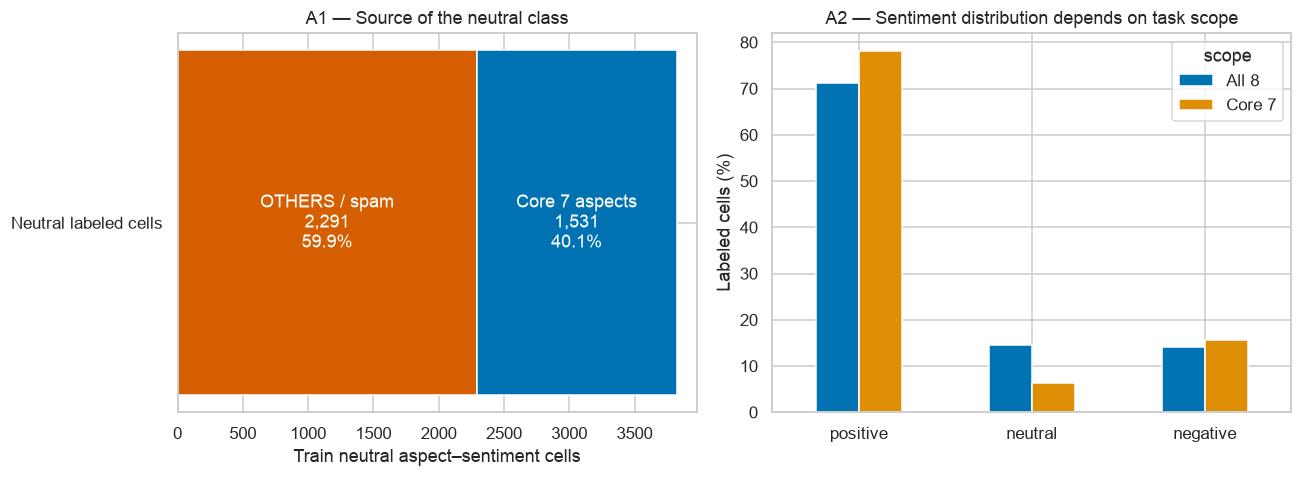

**Quan sát:** 59.94% Neutral train cells đến từ OTHERS; bỏ OTHERS thì Neutral còn 6.40%, IR tăng 5.03 → 12.21.

**Kết luận:** Global Neutral gộp spam và neutral sản phẩm; sentiment imbalance trên core aspects mạnh hơn bảng all-8.

**Hành động methodology:** Giữ 8 aspect-detection labels; đánh giá sentiment của 7 core aspects và report OTHERS/spam riêng. Report cả protocol gốc và core-only, có tên metric rõ.

**Giới hạn:** Chart phản ánh annotation schema; không khẳng định mọi OTHERS review vô nghĩa hoặc phải xoá.

In [24]:
neutral_all=int(aspect_sentiment_counts['train']['neutral'].sum())
neutral_others=int(aspect_sentiment_counts['train'].loc['others','neutral'])
neutral_core=neutral_all-neutral_others
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].barh(['Neutral labeled cells'],[neutral_others],label='OTHERS / spam',color='#D55E00')
axes[0].barh(['Neutral labeled cells'],[neutral_core],left=[neutral_others],label='7 core aspects',color='#0072B2')
axes[0].text(neutral_others/2,0,f'OTHERS / spam\n{neutral_others:,}\n{100*neutral_others/neutral_all:.1f}%',ha='center',va='center',color='white')
axes[0].text(neutral_others+neutral_core/2,0,f'Core 7 aspects\n{neutral_core:,}\n{100*neutral_core/neutral_all:.1f}%',ha='center',va='center',color='white')
axes[0].set_xlim(0,neutral_all*1.04);axes[0].set_xlabel('Train neutral aspect–sentiment cells')
axes[0].set_title('A1 — Source of the neutral class')
comparison=global_sentiment.query("split=='train'").pivot(index='sentiment',columns='scope',values='percentage').reindex(SENTIMENTS)
comparison.rename(columns={'all_8_aspects':'All 8','exclude_OTHERS':'Core 7'}).plot.bar(ax=axes[1])
axes[1].set_title('A2 — Sentiment distribution depends on task scope')
axes[1].set_ylabel('Labeled cells (%)');axes[1].set_xlabel('');axes[1].tick_params(axis='x',rotation=0)
finish_evidence_figure(fig,'17a_neutral_semantics')
core_global=global_sentiment.query("split=='train' and scope=='exclude_OTHERS'").set_index('sentiment')
ir_all=float(global_sentiment.query("split=='train' and scope=='all_8_aspects'").iloc[0].IR_majority_minority)
ir_core=float(core_global.iloc[0].IR_majority_minority)
evidence(f'{100*neutral_others/neutral_all:.2f}% Neutral train cells đến từ OTHERS; bỏ OTHERS thì '
         f'Neutral còn {core_global.loc["neutral","percentage"]:.2f}%, IR tăng {ir_all:.2f} → {ir_core:.2f}.',
         'Global Neutral gộp spam và neutral sản phẩm; sentiment imbalance trên core aspects mạnh hơn bảng all-8.',
         'Giữ 8 aspect-detection labels; đánh giá sentiment của 7 core aspects và report OTHERS/spam riêng. '
         'Report cả protocol gốc và core-only, có tên metric rõ.',
         'Chart phản ánh annotation schema; không khẳng định mọi OTHERS review vô nghĩa hoặc phải xoá.')

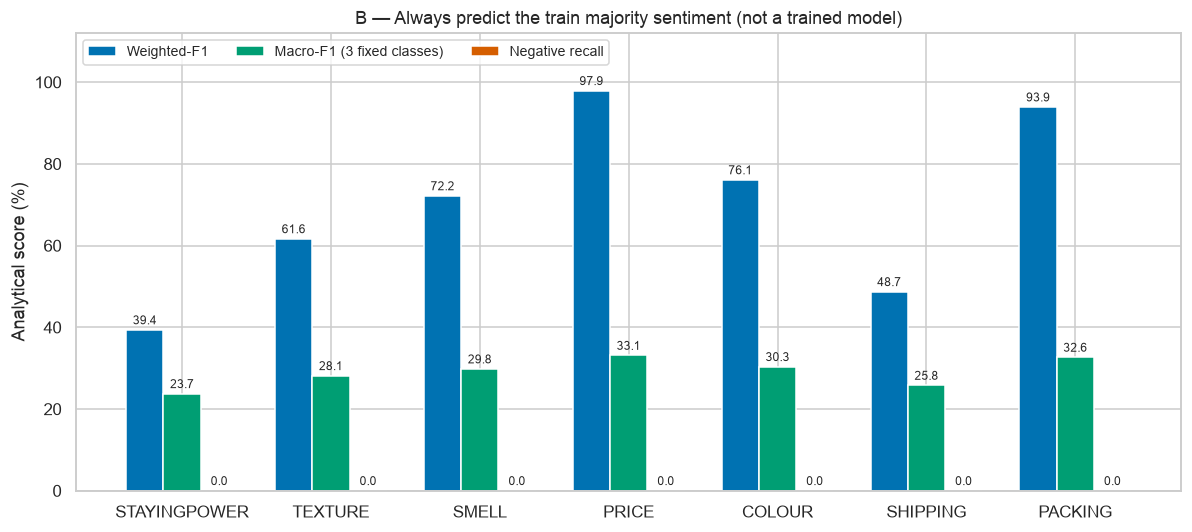

**Quan sát:** PRICE majority baseline: Weighted-F1=97.90%, Macro-F1=33.10%, Negative recall=0%; PACKING Weighted-F1=93.90% cũng có Negative recall=0%.

**Kết luận:** Weighted-F1 có thể cao khi minority classes không được dự đoán đúng lần nào.

**Hành động methodology:** Dùng fixed-label joint Macro-F1 làm primary; report Micro/Weighted, per-pair support, per-aspect/per-sentiment F1 và Negative precision/recall. Majority baseline là sanity floor.

**Giới hạn:** Đây là closed-form sentiment-on-gold-aspect diagnostic, không cùng unit với joint 21-label Macro-F1 và không đo khả năng của model thực tế.

In [25]:
demo=majority_demo.query("split=='train' and scope in @CORE_ASPECTS").set_index('scope').reindex(CORE_ASPECTS)
fig,ax=plt.subplots(figsize=(11,5))
positions=np.arange(len(demo));w=.25
for j,(col,label,color) in enumerate([('weighted_F1','Weighted-F1','#0072B2'),
                                     ('macro_F1_fixed3','Macro-F1 (3 fixed classes)','#009E73'),
                                     ('negative_recall','Negative recall','#D55E00')]):
    values=100*demo[col]
    bars=ax.bar(positions+(j-1)*w,values,width=w,label=label,color=color)
    ax.bar_label(bars,fmt='%.1f',fontsize=8,padding=2)
ax.set_xticks(positions,[a.upper() for a in demo.index]);ax.set_ylim(0,112)
ax.set_ylabel('Analytical score (%)');ax.legend(loc='upper left',ncol=3,fontsize=9)
ax.set_title('B — Always predict the train majority sentiment (not a trained model)')
finish_evidence_figure(fig,'17b_majority_metric_masking')
price_b=demo.loc['price'];packing_b=demo.loc['packing']
evidence(f'PRICE majority baseline: Weighted-F1={100*price_b.weighted_F1:.2f}%, '
         f'Macro-F1={100*price_b.macro_F1_fixed3:.2f}%, Negative recall=0%; '
         f'PACKING Weighted-F1={100*packing_b.weighted_F1:.2f}% cũng có Negative recall=0%.',
         'Weighted-F1 có thể cao khi minority classes không được dự đoán đúng lần nào.',
         'Dùng fixed-label joint Macro-F1 làm primary; report Micro/Weighted, per-pair support, '
         'per-aspect/per-sentiment F1 và Negative precision/recall. Majority baseline là sanity floor.',
         'Đây là closed-form sentiment-on-gold-aspect diagnostic, không cùng unit với joint 21-label Macro-F1 '
         'và không đo khả năng của model thực tế.')

## 18. Rare-class support và độ phân giải của evaluation

Chart C1 so count các cặp Neutral/Negative (symlog để hiển thị cả zero).
Chart C2: `100 / N_gold` là số percentage points thay đổi recall khi đúng thêm một gold item.
Đây là độ phân giải do support, không phải measured recall hay confidence interval.

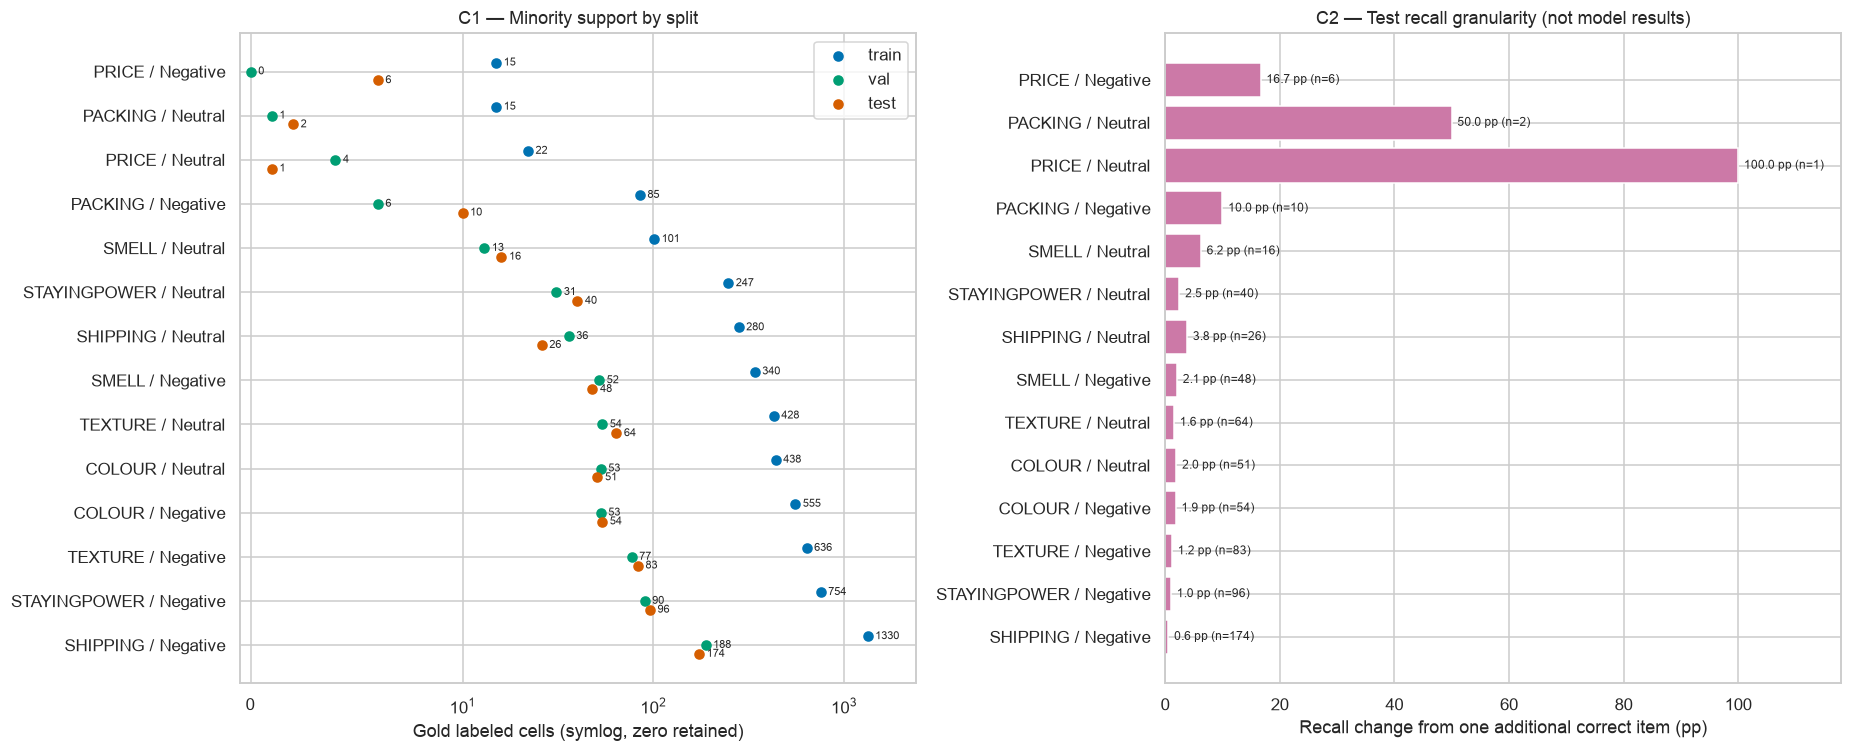

**Quan sát:** PRICE-Negative: train=15, val=0, test=6; test PRICE-Neutral n=1, PACKING-Neutral n=2.

**Kết luận:** Validation không kiểm tra được PRICE-Negative recall; test minority metrics có thể đổi rất mạnh chỉ vì 1–2 items.

**Hành động methodology:** Report TP/FP/FN và support, zero-support=N/A cho recall; dùng grouped CV trong train nếu cần sensitivity analysis của rare classes. Không dùng test để chọn loss. Audit rare labels trước inverse weights/focal.

**Giới hạn:** Macro-F1 vẫn cần thiết nhưng rất nhạy support; không tuyên bố superiority của rare class từ vài items hoặc so trực tiếp conditional majority F1 với end-to-end metric.

In [26]:
minority=aspect_sentiment_table.query("aspect!='others' and sentiment!='positive'").copy()
minority['pair']=minority['aspect'].str.upper()+' / '+minority['sentiment'].str.title()
pair_order=minority.query("split=='train'").sort_values('count')['pair'].tolist()
minority_counts=minority.pivot(index='pair',columns='split',values='count').reindex(pair_order)
test_support=minority_counts['test']
recall_resolution=100/test_support.replace(0,np.nan)
fig,axes=plt.subplots(1,2,figsize=(17,7))
y_pos=np.arange(len(pair_order))
for offset,s,col in [(-.2,'train','#0072B2'),(0,'val','#009E73'),(.2,'test','#D55E00')]:
    x=minority_counts[s].to_numpy()
    axes[0].scatter(x,y_pos+offset,label=s,color=col,s=35)
    for value,yy in zip(x,y_pos+offset):axes[0].annotate(str(int(value)),(value,yy),xytext=(5,0),textcoords='offset points',fontsize=7,va='center')
axes[0].set_yticks(y_pos,pair_order);axes[0].set_xscale('symlog',linthresh=10)
axes[0].set_xlim(-.5,minority_counts.max().max()*1.8);axes[0].invert_yaxis()
axes[0].set_xlabel('Gold labeled cells (symlog, zero retained)');axes[0].legend()
axes[0].set_title('C1 — Minority support by split')
bars=axes[1].barh(y_pos,recall_resolution,color='#CC79A7')
axes[1].set_yticks(y_pos,pair_order);axes[1].invert_yaxis();axes[1].set_xlim(0,118)
for i,(v,support) in enumerate(zip(recall_resolution,test_support)):
    if pd.notna(v):axes[1].text(v+1,i,f'{v:.1f} pp (n={int(support)})',va='center',fontsize=8)
axes[1].set_xlabel('Recall change from one additional correct item (pp)')
axes[1].set_title('C2 — Test recall granularity (not model results)')
finish_evidence_figure(fig,'18_rare_support_recall_granularity')
evidence(f'PRICE-Negative: train={int(minority_counts.loc["PRICE / Negative","train"])}, '
         f'val={int(minority_counts.loc["PRICE / Negative","val"])}, '
         f'test={int(minority_counts.loc["PRICE / Negative","test"])}; '
         f'test PRICE-Neutral n={int(test_support["PRICE / Neutral"])}, PACKING-Neutral n={int(test_support["PACKING / Neutral"])}.',
         'Validation không kiểm tra được PRICE-Negative recall; test minority metrics có thể đổi rất mạnh chỉ vì 1–2 items.',
         'Report TP/FP/FN và support, zero-support=N/A cho recall; dùng grouped CV trong train nếu cần '
         'sensitivity analysis của rare classes. Không dùng test để chọn loss. Audit rare labels trước inverse weights/focal.',
         'Macro-F1 vẫn cần thiết nhưng rất nhạy support; không tuyên bố superiority của rare class từ vài items '
         'hoặc so trực tiếp conditional majority F1 với end-to-end metric.')

## 19. Lexical cues và mixed polarity: chọn baseline và model formulation

Chart D đo token xuất hiện trong/ngoài gold aspect trên train. Các từ có thể là cue hợp lệ của aspect,
không tự động là spurious shortcut. Chart E dùng tập sentiment **core-7** trên từng review,
không lấy một review-level sentiment làm target ABSA.

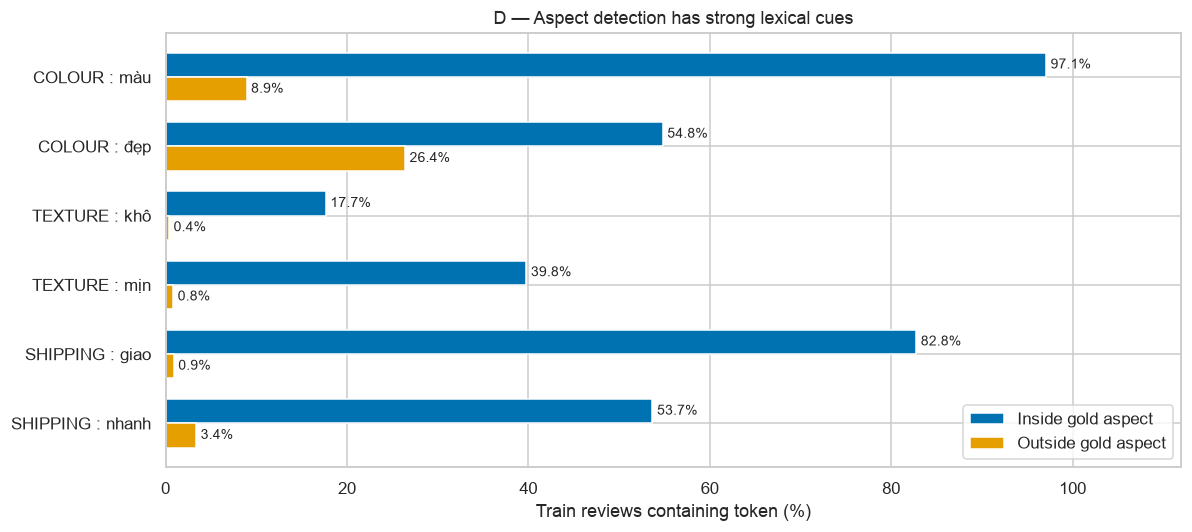

**Quan sát:** Token màu xuất hiện trong 97.07% review COLOUR; giao trong 82.76% SHIPPING; mịn trong 39.78% TEXTURE.

**Kết luận:** Aspect detection có lexical signal rõ; cue frequency chưa nói được sentiment hay chứng minh shortcut.

**Hành động methodology:** Baseline bắt buộc: majority, keyword rules cho aspect detection, TF-IDF word/bigram + char n-gram linear classifiers. So với pretrained contextual encoder trên cùng task/split/seeds; kiểm tra negation/mixed/noise slices.

**Giới hạn:** Tokenization hiện là Unicode alphabetic tokens, chưa word segmentation; cues co-occur giữa aspects và chưa được đánh giá out-of-product/domain.

In [27]:
lex_evidence=[]
for a,terms in expected_terms.items():
    mask=presence['train'][a].astype(bool).to_numpy()
    for term in terms:
        inside=sum(term in doc_counts[i] for i in np.flatnonzero(mask))
        outside=train_dfreq[term]-inside
        lex_evidence.append({'cue':a.upper()+' : '+term,'inside_pct':100*inside/mask.sum(),
                             'outside_pct':100*outside/(~mask).sum()})
lex_evidence=pd.DataFrame(lex_evidence)
fig,ax=plt.subplots(figsize=(11,5))
ypos=np.arange(len(lex_evidence));w=.35
for offset,key,label,color in [(-w/2,'inside_pct','Inside gold aspect','#0072B2'),(w/2,'outside_pct','Outside gold aspect','#E69F00')]:
    bars=ax.barh(ypos+offset,lex_evidence[key],height=w,label=label,color=color)
    ax.bar_label(bars,fmt='%.1f%%',fontsize=9,padding=3)
ax.set_yticks(ypos,lex_evidence.cue);ax.invert_yaxis();ax.set_xlim(0,112)
ax.set_xlabel('Train reviews containing token (%)');ax.legend(loc='lower right')
ax.set_title('D — Aspect detection has strong lexical cues')
finish_evidence_figure(fig,'19a_lexical_aspect_cues')
evidence('Token màu xuất hiện trong %.2f%% review COLOUR; giao trong %.2f%% SHIPPING; mịn trong %.2f%% TEXTURE.'%
         (lex_evidence.loc[lex_evidence.cue.eq('COLOUR : màu'),'inside_pct'].iloc[0],
          lex_evidence.loc[lex_evidence.cue.eq('SHIPPING : giao'),'inside_pct'].iloc[0],
          lex_evidence.loc[lex_evidence.cue.eq('TEXTURE : mịn'),'inside_pct'].iloc[0]),
         'Aspect detection có lexical signal rõ; cue frequency chưa nói được sentiment hay chứng minh shortcut.',
         'Baseline bắt buộc: majority, keyword rules cho aspect detection, TF-IDF word/bigram + char n-gram linear classifiers. '
         'So với pretrained contextual encoder trên cùng task/split/seeds; kiểm tra negation/mixed/noise slices.',
         'Tokenization hiện là Unicode alphabetic tokens, chưa word segmentation; cues co-occur giữa aspects '
         'và chưa được đánh giá out-of-product/domain.')

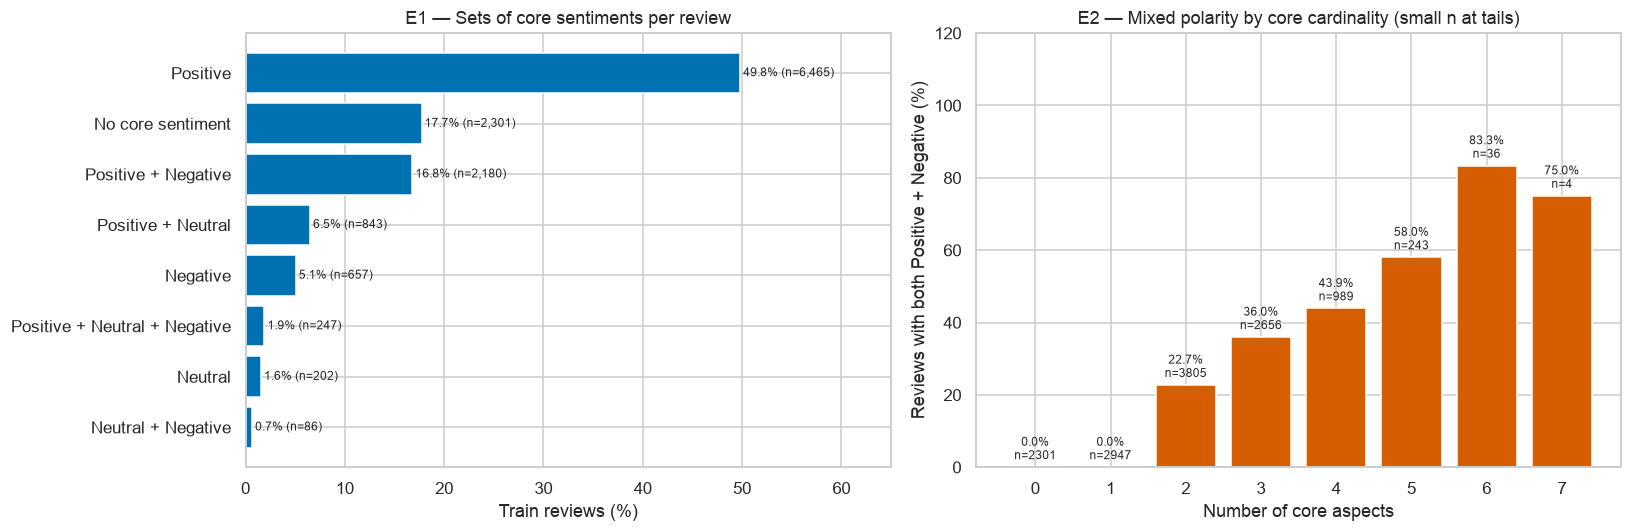

**Quan sát:** Train có 2,427 review đồng thời Positive + Negative (18.70% toàn train); 7,733 review có ≥2 core aspects. Trong nhóm multi-core-aspect, tỷ lệ Positive + Negative = 31.38%.

**Kết luận:** Một sentiment duy nhất cho review không biểu diễn đầy đủ ABSA. Mixed polarity là challenge slice quan trọng.

**Hành động methodology:** Formulation: multi-label aspect detection + sentiment theo aspect, hoặc dự đoán tập aspect–sentiment pairs. Các head độc lập vẫn là baseline hợp lệ; thử shared/aspect-conditioned representations bằng ablation.

**Giới hạn:** Chart không chứng minh dependency cần được model explicit; nhóm cardinality 6–7 có ít mẫu và polarity set không mô tả vị trí phrase trong review. Thêm aspects tạo thêm cơ hội xuất hiện nhiều polarity, nên trend theo cardinality không tự chứng minh dependency cần shared modeling.

In [28]:
core_sentiment_flags=pd.DataFrame({k:train_df[CORE_ASPECTS].eq(k).any(axis=1) for k in SENTIMENTS})
def sentiment_set_name(row):
    names=[k.title() for k in SENTIMENTS if row[k]]
    return ' + '.join(names) if names else 'No core sentiment'
sentiment_sets=core_sentiment_flags.apply(sentiment_set_name,axis=1)
set_counts=sentiment_sets.value_counts()
both_pn=core_sentiment_flags.positive & core_sentiment_flags.negative
core_card=presence['train'][CORE_ASPECTS].sum(axis=1)
mix_by_card=pd.DataFrame({'cardinality':core_card,'both_positive_negative':both_pn}).groupby('cardinality').agg(
    n=('both_positive_negative','size'),mixed_count=('both_positive_negative','sum'),mixed_rate=('both_positive_negative','mean'))
fig,axes=plt.subplots(1,2,figsize=(15,5))
bars=axes[0].barh(set_counts.index,100*set_counts/len(train_df),color='#0072B2')
axes[0].bar_label(bars,labels=[f'{x:.1f}% (n={v:,})' for x,v in zip(100*set_counts/len(train_df),set_counts)],fontsize=8,padding=2)
axes[0].invert_yaxis();axes[0].set_xlim(0,65);axes[0].set_xlabel('Train reviews (%)')
axes[0].set_title('E1 — Sets of core sentiments per review')
bars=axes[1].bar(mix_by_card.index,100*mix_by_card.mixed_rate,color='#D55E00')
axes[1].bar_label(bars,labels=[f'{100*r:.1f}%\nn={int(v)}' for r,v in zip(mix_by_card.mixed_rate,mix_by_card.n)],fontsize=8,padding=3)
axes[1].set_ylim(0,120);axes[1].set_xlabel('Number of core aspects');axes[1].set_ylabel('Reviews with both Positive + Negative (%)')
axes[1].set_title('E2 — Mixed polarity by core cardinality (small n at tails)')
finish_evidence_figure(fig,'19b_mixed_sentiment_scope')
evidence(f'Train có {int(both_pn.sum()):,} review đồng thời Positive + Negative '
         f'({100*both_pn.mean():.2f}% toàn train); {int(core_card.ge(2).sum()):,} review có ≥2 core aspects. '
         f'Trong nhóm multi-core-aspect, tỷ lệ Positive + Negative = {100*both_pn.sum()/core_card.ge(2).sum():.2f}%.',
         'Một sentiment duy nhất cho review không biểu diễn đầy đủ ABSA. Mixed polarity là challenge slice quan trọng.',
         'Formulation: multi-label aspect detection + sentiment theo aspect, hoặc dự đoán tập aspect–sentiment pairs. '
         'Các head độc lập vẫn là baseline hợp lệ; thử shared/aspect-conditioned representations bằng ablation.',
         'Chart không chứng minh dependency cần được model explicit; nhóm cardinality 6–7 có ít mẫu và '
         'polarity set không mô tả vị trí phrase trong review. Thêm aspects tạo thêm cơ hội xuất hiện nhiều polarity, '
         'nên trend theo cardinality không tự chứng minh dependency cần shared modeling.')

## 20. Length: effect size và cardinality confounding

Chart F1 là ECDF theo hai nhóm disjoint core positive-only/negative-only.
Chart F2 so sánh mean word-count trong cùng **core cardinality**, chỉ vẽ strata có ≥10 review mỗi nhóm.
CI: 500 review bootstrap resamples/stratum, seed 2026. Không adjust aspect mix, duplication hay reviewer identity.

,core_cardinality,positive_n,negative_n,negative_minus_positive,ci_low,ci_high
0,1,2263,526,2.648,1.561,3.570
1,2,2406,105,7.976,5.009,11.038
2,3,1333,25,6.416,0.805,12.649


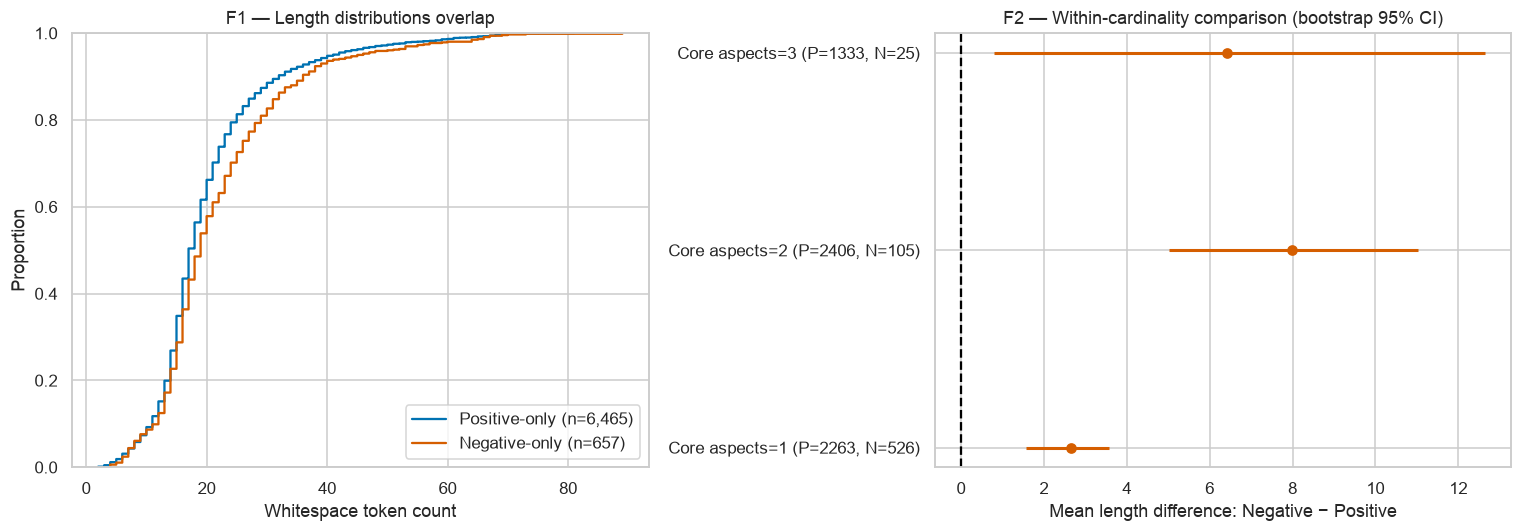

**Quan sát:** Marginal mean gap = 1.97 whitespace tokens, Cohen d=0.185; 3 core-cardinality strata có đủ ≥10 mẫu mỗi nhóm để so sánh. Các gap N−P trong strata: k=1: +2.65 tokens (95% CI [1.56, 3.57]); k=2: +7.98 tokens (95% CI [5.01, 11.04]); k=3: +6.42 tokens (95% CI [0.80, 12.65]).

**Kết luận:** Marginal effect nhỏ, nhưng gap vẫn còn trong các strata đủ support và lớn hơn ở nhóm 2 aspects. Cardinality chưa giải thích hết association; aspect mix và selection vẫn có thể ảnh hưởng. Chưa có bằng chứng model khai thác length.

**Hành động methodology:** Thử length-only diagnostic baseline; report validation metrics theo train-defined length bins và multi-aspect slices. Chọn token max_length bằng tokenizer trên train, không từ whitespace chart.

**Giới hạn:** CI review-bootstrap giả định review độc lập; duplicate/template có thể làm CI quá hẹp; pure-sentiment filtering và aspect mix ảnh hưởng comparison.

In [29]:
strat_rows=[];rng_strat=np.random.default_rng(2026)
for k in sorted(core_card.unique()):
    a=train_lengths.loc[pure_positive & core_card.eq(k),'word_count'].to_numpy(float)
    b=train_lengths.loc[pure_negative & core_card.eq(k),'word_count'].to_numpy(float)
    if min(len(a),len(b))<10:
        continue
    boot=np.array([rng_strat.choice(b,len(b),replace=True).mean()-rng_strat.choice(a,len(a),replace=True).mean()
                   for _ in range(500)])
    strat_rows.append({'core_cardinality':int(k),'positive_n':len(a),'negative_n':len(b),
                       'negative_minus_positive':b.mean()-a.mean(),
                       'ci_low':np.quantile(boot,.025),'ci_high':np.quantile(boot,.975)})
length_strata=pd.DataFrame(strat_rows)
display(length_strata.round(3))
fig,axes=plt.subplots(1,2,figsize=(14,5))
for mask,label,col in [(pure_positive,'Positive-only','#0072B2'),(pure_negative,'Negative-only','#D55E00')]:
    sns.ecdfplot(train_lengths.loc[mask,'word_count'],label=f'{label} (n={mask.sum():,})',color=col,ax=axes[0])
axes[0].set_title('F1 — Length distributions overlap');axes[0].set_xlabel('Whitespace token count');axes[0].legend()
if len(length_strata):
    xx=np.arange(len(length_strata));mean=length_strata.negative_minus_positive
    # Horizontal lines use the actual CI endpoints, even if mean is outside the bootstrap percentile CI.
    axes[1].hlines(xx,length_strata.ci_low,length_strata.ci_high,color='#D55E00',linewidth=2)
    axes[1].scatter(mean,xx,color='#D55E00')
    axes[1].set_yticks(xx,[f'Core aspects={r.core_cardinality} (P={r.positive_n}, N={r.negative_n})'
                          for r in length_strata.itertuples()])
axes[1].axvline(0,color='black',linestyle='--');axes[1].set_xlabel('Mean length difference: Negative − Positive')
axes[1].set_title('F2 — Within-cardinality comparison (bootstrap 95% CI)')
finish_evidence_figure(fig,'20_length_cardinality_confounding')
evidence(f'Marginal mean gap = {word_effect.negative_minus_positive_mean:.2f} whitespace tokens, '
         f'Cohen d={word_effect.cohen_d_negative_minus_positive:.3f}; '
         f'{len(length_strata)} core-cardinality strata có đủ ≥10 mẫu mỗi nhóm để so sánh. '
         + 'Các gap N−P trong strata: ' + '; '.join(
             f'k={r.core_cardinality}: {r.negative_minus_positive:+.2f} tokens '
             f'(95% CI [{r.ci_low:.2f}, {r.ci_high:.2f}])' for r in length_strata.itertuples()) + '.',
         'Marginal effect nhỏ, nhưng gap vẫn còn trong các strata đủ support và lớn hơn ở nhóm 2 aspects. '
         'Cardinality chưa giải thích hết association; aspect mix và selection vẫn có thể ảnh hưởng. '
         'Chưa có bằng chứng model khai thác length.',
         'Thử length-only diagnostic baseline; report validation metrics theo train-defined length bins và '
         'multi-aspect slices. Chọn token max_length bằng tokenizer trên train, không từ whitespace chart.',
         'CI review-bootstrap giả định review độc lập; duplicate/template có thể làm CI quá hẹp; '
         'pure-sentiment filtering và aspect mix ảnh hưởng comparison.')

## 21. Noise patterns theo annotation group

Chart G so hai nhóm disjoint: **core aspect present** và **OTHERS-only** trên train.
Review có OTHERS cùng core aspect nằm trong core-present group; review toàn blank bị loại khỏi chart.
Heuristic flags không phải nhãn spam, không cộng tỷ lệ nhiều patterns.

,group,pattern,group_n,flag_n,pct
0,Core aspect present,emoji_or_symbol_range,10680,1583,14.82
1,Core aspect present,repeated_letter_3plus,10680,1549,14.50
2,Core aspect present,slang_or_shop_token,10680,3729,34.92
3,Core aspect present,uppercase_gt50pct_min10letters,10680,5,0.05
4,Core aspect present,url,10680,3,0.03
5,Core aspect present,filler_candidate_no_vowel,10680,185,1.73
6,Core aspect present,symbols_only,10680,0,0.00
7,OTHERS-only,emoji_or_symbol_range,2287,337,14.74
8,OTHERS-only,repeated_letter_3plus,2287,619,27.07
9,OTHERS-only,slang_or_shop_token,2287,418,18.28


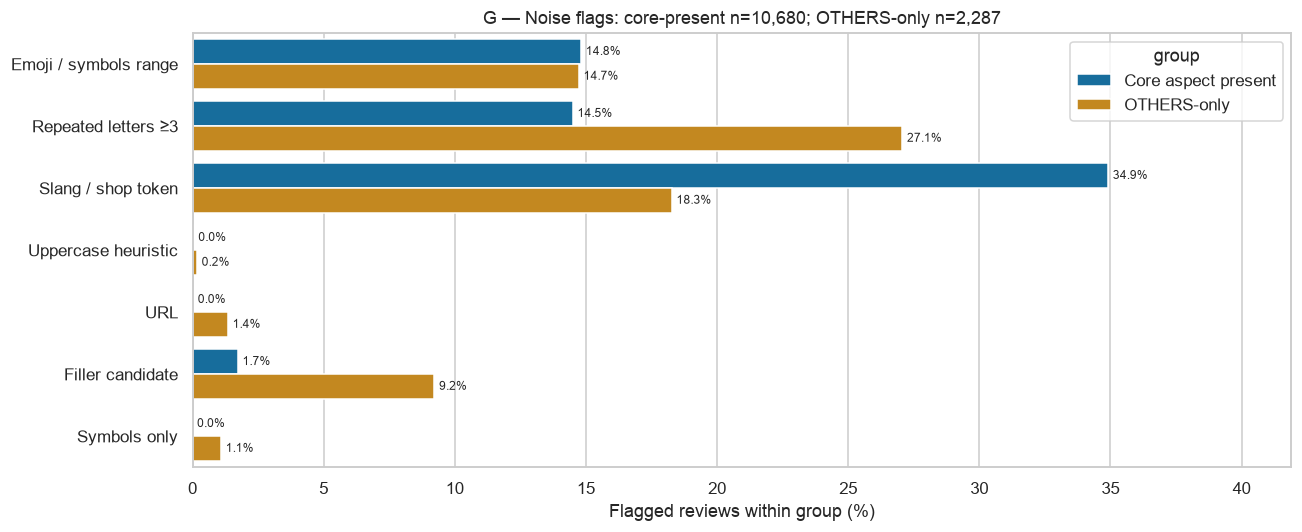

**Quan sát:** Trong core-present train, emoji/symbol flag=14.82%, repeated-letter flag=14.50%; Emoji/symbol flag ở OTHERS-only=14.74%, gần mức core-present. 14 review không thuộc hai nhóm được loại khỏi chart.

**Kết luận:** Nonstandard text cũng tồn tại trong review có aspect thực, nên noise-removal toàn cục có thể bỏ sentiment signal. Emoji rates gần nhau giữa hai nhóm không ủng hộ dùng emoji presence làm bộ lọc spam. Cần phân biệt preprocessing cho sentiment với spam handling.

**Hành động methodology:** Giữ raw emoji/repetition/teencode ở baseline; thử char n-gram baseline và từng normalization ablation riêng trên validation. Đánh giá core noisy slice và spam detection riêng.

**Giới hạn:** Emoji ranges gồm symbols; shop không phải lỗi; filler heuristic bỏ sót nhiều gibberish có vowel. Chart không đo spam prevalence hay lợi ích normalization.

In [30]:
core_present=presence['train'][CORE_ASPECTS].any(axis=1)
others_only=presence['train']['others'].eq(1)&~core_present
noise_patterns=['emoji_or_symbol_range','repeated_letter_3plus','slang_or_shop_token',
                'uppercase_gt50pct_min10letters','url','filler_candidate_no_vowel','symbols_only']
noise_group_rows=[]
for name,mask in [('Core aspect present',core_present),('OTHERS-only',others_only)]:
    for pattern in noise_patterns:
        noise_group_rows.append({'group':name,'pattern':pattern,'group_n':int(mask.sum()),
                                  'flag_n':int(noise_flags['train'].loc[mask,pattern].sum()),
                                  'pct':100*noise_flags['train'].loc[mask,pattern].mean()})
noise_by_group=pd.DataFrame(noise_group_rows)
display(noise_by_group.round(2))
labels={'emoji_or_symbol_range':'Emoji / symbols range','repeated_letter_3plus':'Repeated letters ≥3',
        'slang_or_shop_token':'Slang / shop token','uppercase_gt50pct_min10letters':'Uppercase heuristic',
        'url':'URL','filler_candidate_no_vowel':'Filler candidate','symbols_only':'Symbols only'}
fig,ax=plt.subplots(figsize=(12,5))
plot_data=noise_by_group.assign(pattern_name=lambda x:x.pattern.map(labels))
sns.barplot(data=plot_data,x='pct',y='pattern_name',hue='group',ax=ax)
for container in ax.containers:ax.bar_label(container,fmt='%.1f%%',fontsize=8,padding=3)
ax.set_xlim(0,max(10,noise_by_group.pct.max()*1.2));ax.set_xlabel('Flagged reviews within group (%)');ax.set_ylabel('')
ax.set_title(f'G — Noise flags: core-present n={core_present.sum():,}; OTHERS-only n={others_only.sum():,}')
finish_evidence_figure(fig,'21_noise_core_vs_others')
emoji_core=noise_by_group.query("group=='Core aspect present' and pattern=='emoji_or_symbol_range'").iloc[0]
emoji_others=noise_by_group.query("group=='OTHERS-only' and pattern=='emoji_or_symbol_range'").iloc[0]
repeat_core=noise_by_group.query("group=='Core aspect present' and pattern=='repeated_letter_3plus'").iloc[0]
evidence(f'Trong core-present train, emoji/symbol flag={emoji_core.pct:.2f}%, repeated-letter flag={repeat_core.pct:.2f}%; '
         f'Emoji/symbol flag ở OTHERS-only={emoji_others.pct:.2f}%, gần mức core-present. '
         f'{int((~core_present & ~others_only).sum())} review không thuộc hai nhóm được loại khỏi chart.',
         'Nonstandard text cũng tồn tại trong review có aspect thực, nên noise-removal toàn cục có thể bỏ sentiment signal. '
         'Emoji rates gần nhau giữa hai nhóm không ủng hộ dùng emoji presence làm bộ lọc spam. '
         'Cần phân biệt preprocessing cho sentiment với spam handling.',
         'Giữ raw emoji/repetition/teencode ở baseline; thử char n-gram baseline và từng normalization ablation riêng '
         'trên validation. Đánh giá core noisy slice và spam detection riêng.',
         'Emoji ranges gồm symbols; shop không phải lỗi; filler heuristic bỏ sót nhiều gibberish có vowel. '
         'Chart không đo spam prevalence hay lợi ích normalization.')

## 22. Annotation quality và split contamination

Chart H1: tỷ lệ dòng nằm trong nhóm normalized duplicate **có nhiều label vectors**, và tỷ lệ all-blank.
Các categories có thể overlap; không cộng chúng thành error rate. Chart H2: tỷ lệ dòng ở split bên phải
trùng split bên trái theo exact row / exact text / normalized text. Không đo inflation của score model.

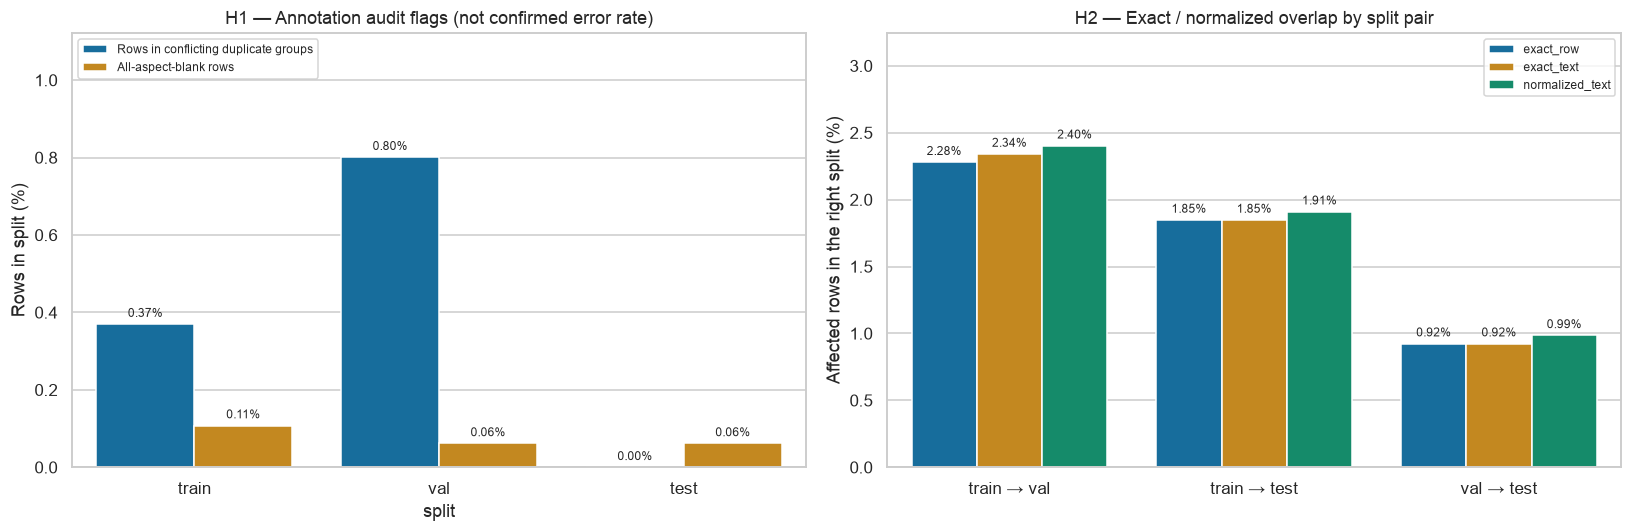

,split,category,rows,pct
0,train,Rows in conflicting duplicate groups,48,0.3698
1,train,All-aspect-blank rows,14,0.1078
2,val,Rows in conflicting duplicate groups,13,0.8010
3,val,All-aspect-blank rows,1,0.0616
4,test,Rows in conflicting duplicate groups,0,0.0000
5,test,All-aspect-blank rows,1,0.0616


,pair,mode,shared_unique_keys,rows_right,right_rows_pct
0,train → val,exact_row,20,37,2.2797
1,train → val,exact_text,18,38,2.3413
2,train → val,normalized_text,19,39,2.4030
3,train → test,exact_row,18,30,1.8484
4,train → test,exact_text,18,30,1.8484
5,train → test,normalized_text,19,31,1.9100
6,val → test,exact_row,5,15,0.9242
7,val → test,exact_text,5,15,0.9242
8,val → test,normalized_text,6,16,0.9858


**Quan sát:** Train normalized-conflict groups liên quan 48 dòng; train có 14 all-blank rows; train→test normalized overlap liên quan 31/1623 test rows.

**Kết luận:** Có annotation inconsistency candidates và split contamination; data audit cần đi trước giải thích lỗi model.

**Hành động methodology:** Giữ benchmark gốc với contamination disclosure. Audit rare/mixed/blank/conflict samples theo guideline; nếu sửa, tạo version mới và group normalized duplicate trước split. Fit loss weights sau audit từ train.

**Giới hạn:** Không phải mọi conflict hoặc blank đều sai; tỷ lệ overlap không bằng mức tăng metric. Exact normalization chưa kiểm tra near-duplicate, Unicode equivalence hay product/user leakage.

In [31]:
quality_chart_rows=[]
for s in SPLITS:
    involved=int(within_conflicts.query("split==@s and mode=='normalized_text'").iloc[0].involved_rows)
    blanks=int(presence[s].sum(axis=1).eq(0).sum())
    for kind,count in [('Rows in conflicting duplicate groups',involved),('All-aspect-blank rows',blanks)]:
        quality_chart_rows.append({'split':s,'category':kind,'rows':count,'pct':100*count/len(datasets[s])})
quality_chart=pd.DataFrame(quality_chart_rows)
leak_chart=leakage_report.copy()
leak_chart['pair']=leak_chart.left+' → '+leak_chart.right
leak_chart['right_rows_pct']=[100*r.rows_right/len(datasets[r.right]) for r in leak_chart.itertuples()]
fig,axes=plt.subplots(1,2,figsize=(15,5))
sns.barplot(data=quality_chart,x='split',y='pct',hue='category',ax=axes[0])
for container in axes[0].containers:axes[0].bar_label(container,fmt='%.2f%%',fontsize=8,padding=3)
axes[0].set_ylim(0,max(1,quality_chart.pct.max()*1.4));axes[0].set_ylabel('Rows in split (%)')
axes[0].set_title('H1 — Annotation audit flags (not confirmed error rate)')
axes[0].legend(fontsize=8,loc='upper left')
sns.barplot(data=leak_chart,x='pair',y='right_rows_pct',hue='mode',ax=axes[1])
for container in axes[1].containers:axes[1].bar_label(container,fmt='%.2f%%',fontsize=8,padding=3)
axes[1].set_ylabel('Affected rows in the right split (%)');axes[1].set_xlabel('')
axes[1].set_ylim(0,leak_chart.right_rows_pct.max()*1.35);axes[1].legend(fontsize=8)
axes[1].set_title('H2 — Exact / normalized overlap by split pair')
finish_evidence_figure(fig,'22_quality_and_contamination')
display(quality_chart.round(4))
display(leak_chart[['pair','mode','shared_unique_keys','rows_right','right_rows_pct']].round(4))
evidence(f'Train normalized-conflict groups liên quan {int(train_conflicts.involved_rows)} dòng; '
         f'train có {int(presence["train"].sum(axis=1).eq(0).sum())} all-blank rows; '
         f'train→test normalized overlap liên quan {int(test_overlap.rows_right)}/{len(datasets["test"])} test rows.',
         'Có annotation inconsistency candidates và split contamination; data audit cần đi trước giải thích lỗi model.',
         'Giữ benchmark gốc với contamination disclosure. Audit rare/mixed/blank/conflict samples theo guideline; '
         'nếu sửa, tạo version mới và group normalized duplicate trước split. Fit loss weights sau audit từ train.',
         'Không phải mọi conflict hoặc blank đều sai; tỷ lệ overlap không bằng mức tăng metric. '
         'Exact normalization chưa kiểm tra near-duplicate, Unicode equivalence hay product/user leakage.')

## 23. Methodology được đề xuất từ chart evidence

Đây là protocol để triển khai và kiểm chứng. Những lựa chọn đã có bằng chứng EDA được chốt ở mức formulation
và reporting; lựa chọn model/loss/preprocessing cụ thể vẫn cần validation. Không có model metrics trong notebook này.

In [32]:
methodology_protocol=pd.DataFrame([
 {'component':'Task formulation','chart':'A, E','decision':'8 aspect labels; 7 core aspect sentiments; OTHERS/spam report riêng. Không review-level sentiment argmax.',
  'next_action':'Định nghĩa encoder target, blank=aspect absent trong annotation; giữ conditional sentiment và joint evaluation khác tên.',
  'readiness':'Có thể chốt formulation; không sửa schema nguồn.'},
 {'component':'Data / benchmark','chart':'H','decision':'Original split phục vụ replication + contamination disclosure; nếu tạo split sạch phải có version riêng.',
  'next_action':'Freeze hashes/protocol; adjudicate rare/conflict/blank candidates; grouped splitting/CV nếu tạo benchmark mới.',
  'readiness':'Chưa có cleaned labels hoặc product/user/time metadata.'},
 {'component':'Baselines','chart':'B, D, E','decision':'Constant-majority diagnostic, aspect keyword baseline, TF-IDF word/bigram + char n-gram linear baseline.',
  'next_action':'Fit vocabulary/IDF trên train; predict cùng target space. So pretrained Vietnamese contextual encoder, independent vs shared heads.',
  'readiness':'Chưa train hoặc đo superiority.'},
 {'component':'Raw text / tokenizer','chart':'F, G','decision':'Giữ emoji, repetition, teencode và case phù hợp tokenizer ở baseline; không blanket cleaning.',
  'next_action':'Đo train subword token P95/P99 gồm special tokens; so max_length candidates, truncation, latency và validation metrics.',
  'readiness':'max_length token chưa chốt vì chưa chọn tokenizer.'},
 {'component':'Imbalance loss','chart':'A, B, C, H','decision':'Unweighted baseline → smoothed/capped train-derived per-aspect weights → focal ablation nếu cần.',
  'next_action':'Audit rare labels; predeclare small search grid; dùng validation joint macro và Negative recall; rare-class sensitivity qua train grouped CV.',
  'readiness':'Không bật focal mặc định; validation thiếu PRICE-negative.'},
 {'component':'Evaluation','chart':'B, C, E','decision':'Primary fixed-label joint Macro-F1 (21 core pairs); Micro/Weighted/P/R, per-aspect/per-sentiment, Negative P/R, support, OTHERS riêng.',
  'next_action':'Predeclare 21 labels, zero-support handling, threshold search; report conditional-vs-end-to-end và review/group bootstrap CI.',
  'readiness':'Có thể chốt protocol; chưa có prediction metrics.'},
 {'component':'Shortcut / robustness','chart':'D, E, F, G','decision':'Challenge slices: negation, mixed polarity, rare pairs, noise, train-defined length bins; OTHERS là task riêng.',
  'next_action':'Length-only diagnostic; one-change-at-a-time preprocessing ablation; fixed seeds/same data/budget; validation selection.',
  'readiness':'Association đã đo; causal shortcut chưa xác nhận.'},
 {'component':'Model selection / business','chart':'B, C + future model results','decision':'Chọn method theo validation joint macro cùng complaint P/R, không theo overall accuracy hoặc weighted F1 riêng.',
  'next_action':'Freeze ít nhất 3 seeds và cùng training budget; chốt Negative P/R trade-off và latency requirement trước final test; report per-seed results.',
  'readiness':'SLA/chi phí complaint chưa có; chưa chọn final model.'}
])
with pd.option_context('display.max_colwidth',None):display(methodology_protocol)
display(Markdown('**Trình tự hành động:** freeze task/metric/split protocol → audit annotations → '
                 'train lexical baselines và contextual comparator → validation loss/preprocessing ablations → '
                 'chốt method/thresholds → final test một lần. Test đã được dùng cho descriptive EDA nên cần '
                 'ghi rõ lịch sử này; không tiếp tục điều chỉnh method từ test observations. '
                 'Nếu cần claim generalization ngoài 9 sản phẩm son của corpus, cần benchmark product/time/domain '
                 'held-out và metadata tương ứng; EDA hiện tại chưa cung cấp bằng chứng đó. '
                 '[Phạm vi corpus trong paper §3.1](https://aclanthology.org/2022.paclic-1.84.pdf).'))
print('Exported evidence figures:')
for path in methodology_figure_paths:print(path.relative_to(DATA_DIR.parent))

,component,chart,decision,next_action,readiness
0,Task formulation,"A, E",8 aspect labels; 7 core aspect sentiments; OTHERS/spam report riêng. Không review-level sentiment argmax.,"Định nghĩa encoder target, blank=aspect absent trong annotation; giữ conditional sentiment và joint evaluation khác tên.",Có thể chốt formulation; không sửa schema nguồn.
1,Data / benchmark,H,Original split phục vụ replication + contamination disclosure; nếu tạo split sạch phải có version riêng.,Freeze hashes/protocol; adjudicate rare/conflict/blank candidates; grouped splitting/CV nếu tạo benchmark mới.,Chưa có cleaned labels hoặc product/user/time metadata.
2,Baselines,"B, D, E","Constant-majority diagnostic, aspect keyword baseline, TF-IDF word/bigram + char n-gram linear baseline.","Fit vocabulary/IDF trên train; predict cùng target space. So pretrained Vietnamese contextual encoder, independent vs shared heads.",Chưa train hoặc đo superiority.
3,Raw text / tokenizer,"F, G","Giữ emoji, repetition, teencode và case phù hợp tokenizer ở baseline; không blanket cleaning.","Đo train subword token P95/P99 gồm special tokens; so max_length candidates, truncation, latency và validation metrics.",max_length token chưa chốt vì chưa chọn tokenizer.
4,Imbalance loss,"A, B, C, H",Unweighted baseline → smoothed/capped train-derived per-aspect weights → focal ablation nếu cần.,Audit rare labels; predeclare small search grid; dùng validation joint macro và Negative recall; rare-class sensitivity qua train grouped CV.,Không bật focal mặc định; validation thiếu PRICE-negative.
5,Evaluation,"B, C, E","Primary fixed-label joint Macro-F1 (21 core pairs); Micro/Weighted/P/R, per-aspect/per-sentiment, Negative P/R, support, OTHERS riêng.","Predeclare 21 labels, zero-support handling, threshold search; report conditional-vs-end-to-end và review/group bootstrap CI.",Có thể chốt protocol; chưa có prediction metrics.
6,Shortcut / robustness,"D, E, F, G","Challenge slices: negation, mixed polarity, rare pairs, noise, train-defined length bins; OTHERS là task riêng.",Length-only diagnostic; one-change-at-a-time preprocessing ablation; fixed seeds/same data/budget; validation selection.,Association đã đo; causal shortcut chưa xác nhận.
7,Model selection / business,"B, C + future model results","Chọn method theo validation joint macro cùng complaint P/R, không theo overall accuracy hoặc weighted F1 riêng.",Freeze ít nhất 3 seeds và cùng training budget; chốt Negative P/R trade-off và latency requirement trước final test; report per-seed results.,SLA/chi phí complaint chưa có; chưa chọn final model.


**Trình tự hành động:** freeze task/metric/split protocol → audit annotations → train lexical baselines và contextual comparator → validation loss/preprocessing ablations → chốt method/thresholds → final test một lần. Test đã được dùng cho descriptive EDA nên cần ghi rõ lịch sử này; không tiếp tục điều chỉnh method từ test observations. Nếu cần claim generalization ngoài 9 sản phẩm son của corpus, cần benchmark product/time/domain held-out và metadata tương ứng; EDA hiện tại chưa cung cấp bằng chứng đó. [Phạm vi corpus trong paper §3.1](https://aclanthology.org/2022.paclic-1.84.pdf).

Exported evidence figures:
reports/eda/17a_neutral_semantics.png
reports/eda/17b_majority_metric_masking.png
reports/eda/18_rare_support_recall_granularity.png
reports/eda/19a_lexical_aspect_cues.png
reports/eda/19b_mixed_sentiment_scope.png
reports/eda/20_length_cardinality_confounding.png
reports/eda/21_noise_core_vs_others.png
reports/eda/22_quality_and_contamination.png


# EDA-04 — Targeted Data Audit

Vòng audit gọn dùng lại dữ liệu, normalization và provenance ở các mục trước.
**Census** cho tất cả splits; **qualitative observations** cho mẫu có chủ đích; không chỉnh annotation,
không deduplicate/split lại, không chạy model. Figures đã có ở mục 17–22 được giữ làm bằng chứng trực quan.
Ở đây `rare` được định nghĩa trước là **core aspect–sentiment có train count ≤25**, bao gồm zero nếu có.
Threshold này phục vụ audit, không phải quy tắc bỏ class hay điều chỉnh hyperparameters.

### 1. Tách OTHERS và tính lại global/core sentiment

Đơn vị là ô aspect–sentiment có nhãn. `all_8` giữ OTHERS; `core_7` bỏ cột OTHERS khỏi phép đếm,
**giữ nguyên review và mọi nhãn core**, kể cả review có OTHERS cùng core.
Full và splits là các bảng đối chiếu riêng; không cộng full với splits.

In [33]:
audit_distribution_rows=[]
audit_group_rows=[]
for s,df in datasets.items():
    core_mask=presence[s][CORE_ASPECTS].any(axis=1)
    others_mask=presence[s]['others'].eq(1)
    audit_group_rows.append({'split':s,'reviews':len(df),'OTHERS_only':int((others_mask&~core_mask).sum()),
                             'OTHERS_and_core':int((others_mask&core_mask).sum()),
                             'core_without_OTHERS':int((core_mask&~others_mask).sum()),
                             'all_aspects_blank':int((~core_mask&~others_mask).sum())})
    for scope,aspects in [('all_8',ASPECTS),('core_7',CORE_ASPECTS)]:
        c=aspect_sentiment_counts[s].loc[aspects].sum()
        audit_distribution_rows.append({'split':s,'scope':scope,'labeled_cells':int(c.sum()),
                                         **{k:int(c[k]) for k in SENTIMENTS},
                                         **{k+'_pct':100*c[k]/c.sum() for k in SENTIMENTS},
                                         'IR_fixed3':c.max()/c.min() if c.min() else np.inf})
audit_distribution=pd.DataFrame(audit_distribution_rows)
audit_others_groups=pd.DataFrame(audit_group_rows)
display(audit_distribution.round(3))
display(audit_others_groups)
audit_train_all=audit_distribution.query("split=='train' and scope=='all_8'").iloc[0]
audit_train_core=audit_distribution.query("split=='train' and scope=='core_7'").iloc[0]
display(Markdown(f'**Kết luận:** train core-7 có Positive **{audit_train_core.positive_pct:.2f}%**, '
                 f'Neutral **{audit_train_core.neutral_pct:.2f}%**, Negative **{audit_train_core.negative_pct:.2f}%**; '
                 f'IR **{audit_train_core.IR_fixed3:.2f}** so với all-8 **{audit_train_all.IR_fixed3:.2f}**. '
                 'Tách task spam khỏi sentiment reporting; không loại cả review khi thấy OTHERS.'))

,split,scope,labeled_cells,positive,neutral,negative,positive_pct,neutral_pct,negative_pct,IR_fixed3
0,full,all_8,32775,23328,4795,4652,71.176,14.630,14.194,5.015
1,full,core_7,29903,23328,1923,4652,78.012,6.431,15.557,12.131
2,train,all_8,26231,18694,3822,3715,71.267,14.571,14.163,5.032
3,train,core_7,23940,18694,1531,3715,78.087,6.395,15.518,12.210
4,val,all_8,3264,2336,462,466,71.569,14.154,14.277,5.056
5,val,core_7,2994,2336,192,466,78.023,6.413,15.564,12.167
6,test,all_8,3280,2298,511,471,70.061,15.579,14.360,4.879
7,test,core_7,2969,2298,200,471,77.400,6.736,15.864,11.490


,split,reviews,OTHERS_only,OTHERS_and_core,core_without_OTHERS,all_aspects_blank
0,full,16227,2868,4,13339,16
1,train,12981,2287,4,10676,14
2,val,1623,270,0,1352,1
3,test,1623,311,0,1311,1


**Kết luận:** train core-7 có Positive **78.09%**, Neutral **6.40%**, Negative **15.52%**; IR **12.21** so với all-8 **5.03**. Tách task spam khỏi sentiment reporting; không loại cả review khi thấy OTHERS.

### 2. Audit extreme rare aspect–sentiment pairs

Census support, unique normalized text, missing validation coverage, conflict-key involvement và train/test overlap.
Ghi chú thủ công chọn 3 review train mỗi rare pair, cộng mẫu test minh hoạ contamination.
Các nhận xét là **candidates cần guideline/adjudication**, không ground truth sửa đổi hoặc tỷ lệ label error.

In [34]:
AUDIT_RARE_MAX_TRAIN=25
audit_rare_pairs=[(a,k) for a in CORE_ASPECTS for k in SENTIMENTS
                  if aspect_sentiment_counts['train'].loc[a,k]<=AUDIT_RARE_MAX_TRAIN]
audit_norm={s:df[TEXT_COL].map(normalize_text) for s,df in datasets.items()}
audit_train_keys=set(audit_norm['train'][audit_norm['train'].ne('')])
audit_seen_keys=audit_train_keys|set(audit_norm['val'][audit_norm['val'].ne('')])
audit_test_overlap_mask=audit_norm['test'].isin(audit_seen_keys)&audit_norm['test'].ne('')
audit_rare_rows=[]
for a,k in audit_rare_pairs:
    train_mask=datasets['train'][a].eq(k)
    train_variants=datasets['train'].assign(text_key=audit_norm['train']).groupby('text_key')[ASPECTS].apply(
        lambda g:len(set(g.itertuples(index=False,name=None))))
    conflict_keys=set(train_variants[train_variants>1].index)
    val_n=int(datasets['val'][a].eq(k).sum())
    test_mask=datasets['test'][a].eq(k)
    overlap_n=int((test_mask&audit_test_overlap_mask).sum())
    counts={s:int(datasets[s][a].eq(k).sum()) for s in SPLITS}
    audit_rare_rows.append({'aspect':a,'sentiment':k,**{s+'_count':counts[s] for s in SPLITS},
                            'train_unique_normalized_texts':int(audit_norm['train'][train_mask].nunique()),
                            'train_rows_in_conflict_keys':int((train_mask&audit_norm['train'].isin(conflict_keys)).sum()),
                            'test_overlap_rows':overlap_n,'test_nonoverlap_support':counts['test']-overlap_n,
                            'val_recall_evaluable':val_n>0})
audit_rare_support=pd.DataFrame(audit_rare_rows)
display(audit_rare_support)
audit_rare_notes=[
 ('train',6613,'price','negative','Mua phí tiền gắn value judgement với chất son bột; implicit price complaint có căn cứ.'),
 ('train',7885,'price','negative','Giá giảm sau mua: negative thể hiện temporal price regret, không chỉ mức giá đắt.'),
 ('train',9177,'price','negative','Giá 250k đắt nhưng ưu đãi mua 1 tặng 1 chấp nhận được: mixed evaluation trong PRICE; cần aggregation rule.'),
 ('train',3697,'price','neutral','Giá 160k theo check mã vạch, chưa kiểm chứng: descriptive/uncertain price statement.'),
 ('train',1355,'price','neutral','Tính theo 2.5g thì k rẻ mấy có negative cue; candidate kiểm tra ranh giới Neutral/Negative.'),
 ('train',4474,'price','neutral','Pass lại 99k là giá bán lại; cần guideline về PRICE của đơn mua và nội dung resale.'),
 ('train',2387,'packing','neutral','Chỉ nhắc đóng gói, không có polarity rõ: neutral có căn cứ.'),
 ('train',4934,'packing','neutral','Tạm được nhưng bung/móp: mixed hoặc complaint; cần aggregation guideline.'),
 ('train',11287,'packing','neutral','Đóng gói sản phẩm chắc chắn có positive cue rõ; candidate annotation inconsistency, chưa sửa.'),
 ('test',720,'price','neutral','Mẫu PRICE-Neutral duy nhất test trùng train row 12120 cả text và vector nhãn; contamination ảnh hưởng coverage lớp.')]
audit_rare_examples=[]
for s,i,a,k,note in audit_rare_notes:
    row=datasets[s].loc[i]
    if row[a]!=k:
        raise ValueError('Source sample changed; qualitative audit must be refreshed.')
    audit_rare_examples.append({'split':s,'source_row_0based':i,'target_pair':a+':'+k,'review':row[TEXT_COL],
                                'all_labels':', '.join(x+':'+row[x] for x in ASPECTS if row[x]),
                                'text_sha256':hashlib.sha256(row[TEXT_COL].encode()).hexdigest(),
                                'observation':note})
audit_rare_examples=pd.DataFrame(audit_rare_examples)
with pd.option_context('display.max_colwidth',None):
    display(audit_rare_examples.drop(columns='text_sha256'))
display(Markdown('**Kết luận / hành động:** PRICE-Negative không có validation support. Rare neutral labels '
                 'gồm descriptive statements, uncertainty và mixed evaluations; cần guideline cho aggregation và scope. '
                 'Audit trước class weights/focal; giữ observations có source row/hash, chưa gọi mẫu cần xem lại là label sai. '
                 'Các con số là census; 10 examples ở đây là qualitative sample có chủ đích, không dùng để ước lượng error rate.'))

,aspect,sentiment,train_count,val_count,test_count,train_unique_normalized_texts,train_rows_in_conflict_keys,test_overlap_rows,test_nonoverlap_support,val_recall_evaluable
0,price,neutral,22,4,1,22,0,1,0,True
1,price,negative,15,0,6,15,0,0,6,False
2,packing,neutral,15,1,2,15,0,0,2,True


,split,source_row_0based,target_pair,review,all_labels,observation
0,train,6613,price:negative,Son này thật sự tệ chất son bột không thể tệp vào môi bột kinh khủng khiếp mà cầm 1 tờ giấy bặm nhẹ là cũng ra hết sạch luôn ! Mua phí tiền !,"texture:negative, price:negative",Mua phí tiền gắn value judgement với chất son bột; implicit price complaint có căn cứ.
1,train,7885,price:negative,Công dụng: sOn mau dejd\r\nKết cấu: NHan dcbahakknxbnxd\r\nĐộ bền màu: rat ben mau nhung nhan duoc hang thi giam gia\r\nNhận đc son thì giảm giá còn 69k tiếc ghê mk mua 159k son,"stayingpower:positive, texture:neutral, price:negative, colour:positive","Giá giảm sau mua: negative thể hiện temporal price regret, không chỉ mức giá đắt."
2,train,9177,price:negative,Chưa dùng thử son nên ko biết chất lượng ntn. Nhưng son này giá 250k thì đắt nha! Nhg mua 1 tặng 1 màu này thì cũng dx,"price:negative, colour:positive",Giá 250k đắt nhưng ưu đãi mua 1 tặng 1 chấp nhận được: mixed evaluation trong PRICE; cần aggregation rule.
3,train,3697,price:neutral,"Hàng giao khá nhanh, đóng gói cẩn thận và chắc chắn, khi check mã vạch thì ra 160k và chưa được kiểm chứng =))","price:neutral, shipping:positive, packing:positive","Giá 160k theo check mã vạch, chưa kiểm chứng: descriptive/uncertain price statement."
4,train,1355,price:neutral,"Son có 2.5g thôi, bằng 1/2 mấy son khác nên tính ra cũng k rẻ mấy.\nSwatch ra tay thì rõ màu nhưng lên môi k lên màu chuẩn. Dùng làm base thì ok. Son k có tint, nhanh trôi","stayingpower:negative, price:neutral, colour:negative",Tính theo 2.5g thì k rẻ mấy có negative cue; candidate kiểm tra ranh giới Neutral/Negative.
5,train,4474,price:neutral,Màu son siêu xinh tuy hơn kén da 1 chút. Bạn nào trắng/make đánh sẽ đẹp hơn. B nào muốn lấy mk pas 99k ạ 0963168393,"price:neutral, colour:positive",Pass lại 99k là giá bán lại; cần guideline về PRICE của đơn mua và nội dung resale.
6,train,2387,packing:neutral,Chất lượng sản phẩm tốt .thời gian giao hàng nhanh.đóng gói .mm,"shipping:positive, packing:neutral","Chỉ nhắc đóng gói, không có polarity rõ: neutral có căn cứ."
7,train,4934,packing:neutral,"Giao cũng nhanh, đóng gói tạm được, có thỏi bị bung ra kiểu đã bị mở trước :v hơi móp. Còn đâu ok, màu thì mình chưa test","colour:neutral, shipping:positive, packing:neutral",Tạm được nhưng bung/móp: mixed hoặc complaint; cần aggregation guideline.
8,train,11287,packing:neutral,"Chất son mịn cực kỳ, lại thơm nữa. Đóng gói sản phẩm chắc chắn. Rẻ cực lun ạ","texture:positive, smell:positive, price:positive, packing:neutral","Đóng gói sản phẩm chắc chắn có positive cue rõ; candidate annotation inconsistency, chưa sửa."
9,test,720,price:neutral,"Shop đóng gói cẩn thận, chờ hàng hơi lâu xíu, nhưng sp ưng, m mua đơn hơn 500k đc tặngg thêm son và túyp dưỡng,","price:neutral, shipping:negative, packing:positive",Mẫu PRICE-Neutral duy nhất test trùng train row 12120 cả text và vector nhãn; contamination ảnh hưởng coverage lớp.


**Kết luận / hành động:** PRICE-Negative không có validation support. Rare neutral labels gồm descriptive statements, uncertainty và mixed evaluations; cần guideline cho aggregation và scope. Audit trước class weights/focal; giữ observations có source row/hash, chưa gọi mẫu cần xem lại là label sai. Các con số là census; 10 examples ở đây là qualitative sample có chủ đích, không dùng để ước lượng error rate.

### 3. OTHERS xuất hiện cùng core aspects

Census và đọc **toàn bộ** review mixed OTHERS/core. OTHERS là spam label theo paper nhưng CSV cho phép
cùng tồn tại với core annotations; không suy ra mutual exclusivity hoặc dùng OTHERS làm hard discard gate.

In [35]:
audit_others_manual={
 1096:'Filler kkkkk/dấu chấm cùng nhận xét giao đúng mẫu; shipping-positive có căn cứ. Có nội dung hữu ích xen filler.',
 1377:'Shipping nhanh và packing cẩn thận có căn cứ; OTHERS cần kiểm tra tiêu chí vì review còn nội dung core rõ, chưa sử dụng son.',
 3745:'Kết cấu kkkkkk là filler nhưng giao hàng siêu nhanh là core signal; spam/noise một phần không xoá cả review.',
 10993:'Nội dung nhận xu/video minh hoạ cùng giao đúng mẫu; cần rule cho spam component và hữu ích shipping cùng tồn tại.'}
audit_others_mixed=[]
for s,df in datasets.items():
    if s=='full':continue
    mask=presence[s]['others'].eq(1)&presence[s][CORE_ASPECTS].any(axis=1)
    for i,row in df.loc[mask].iterrows():
        if s!='train' or i not in audit_others_manual:
            raise ValueError('New OTHERS/core sample requires fresh manual inspection.')
        audit_others_mixed.append({'split':s,'source_row_0based':i,'review':row[TEXT_COL],
                                    'core_labels':', '.join(a+':'+row[a] for a in CORE_ASPECTS if row[a]),
                                    'OTHERS':row['others'],'observation':audit_others_manual[i]})
audit_others_mixed=pd.DataFrame(audit_others_mixed)
with pd.option_context('display.max_colwidth',None):display(audit_others_mixed)
display(Markdown('**Kết luận / hành động:** tất cả **4** mixed samples ở train, val/test có **0**. '
                 'Cả 4 có SHIPPING-positive; 1 có PACKING-positive. Giữ core labels khi tách OTHERS khỏi sentiment counts. '
                 'Nếu triển khai spam handling, dùng soft flag/partial handling hoặc rule đã được adjudicate; '
                 'không loại mọi OTHERS review trước core prediction. Đây là edge case nhỏ, chưa suy ra tỷ lệ phổ biến ngoài corpus.'))

,split,source_row_0based,review,core_labels,OTHERS,observation
0,train,1096,Giao đúng mẫu ..son cũng ok la nha .kkkkk ..................,shipping:positive,neutral,Filler kkkkk/dấu chấm cùng nhận xét giao đúng mẫu; shipping-positive có căn cứ. Có nội dung hữu ích xen filler.
1,train,1377,"Giao hàng nhanh, hàng đóng gói cẩn thận. Mẫu mã son đẹp. Tuy nhiên chưa sử dụng nên chưa biết chất lương. Để mk sd r nk review tiếp nhé. Nếu ok sẽ ủng hộ shop dài dài ạ😍","shipping:positive, packing:positive",neutral,"Shipping nhanh và packing cẩn thận có căn cứ; OTHERS cần kiểm tra tiêu chí vì review còn nội dung core rõ, chưa sử dụng son."
2,train,3745,"Công dụng: làm đẹp\nKết cấu: kkkkkk\nGiao hàng siêu nhanh, chiều đặt trưa có sẽ ung hộ nếu ok kkkkkkkkkkk",shipping:positive,neutral,Kết cấu kkkkkk là filler nhưng giao hàng siêu nhanh là core signal; spam/noise một phần không xoá cả review.
3,train,10993,"Video và hình ảnh mag tính chất nhận xu . Son đẹp , hàng giao đúng mẫu",shipping:positive,neutral,Nội dung nhận xu/video minh hoạ cùng giao đúng mẫu; cần rule cho spam component và hữu ích shipping cùng tồn tại.


**Kết luận / hành động:** tất cả **4** mixed samples ở train, val/test có **0**. Cả 4 có SHIPPING-positive; 1 có PACKING-positive. Giữ core labels khi tách OTHERS khỏi sentiment counts. Nếu triển khai spam handling, dùng soft flag/partial handling hoặc rule đã được adjudicate; không loại mọi OTHERS review trước core prediction. Đây là edge case nhỏ, chưa suy ra tỷ lệ phổ biến ngoài corpus.

### 4. Duplicate / contamination và protocol báo cáo

Phân biệt duplicate row, duplicate text, conflicting annotations và cross-split overlap.
`duplicate_*_extra` đếm các dòng dư; `rows_in_conflicting_groups` đếm mọi dòng của nhóm có nhiều label vectors.
Test subset không overlap chỉ là diagnostic theo exact normalization đã khai báo, chưa phải clean benchmark xác thực.

In [36]:
audit_duplicate_rows=[]
for s,df in datasets.items():
    key=audit_norm[s]
    vectors=pd.Series(list(df[ASPECTS].itertuples(index=False,name=None)),index=df.index)
    tmp=pd.DataFrame({'key':key,'vector':vectors})
    variants=tmp.groupby('key')['vector'].nunique()
    conflicting=set(variants[variants>1].index)
    audit_duplicate_rows.append({'split':s,'reviews':len(df),'duplicate_row_extra':int(df.duplicated().sum()),
                                 'duplicate_exact_text_extra':int(df[TEXT_COL].duplicated().sum()),
                                 'duplicate_normalized_text_extra':int(key.duplicated().sum()),
                                 'conflicting_normalized_keys':len(conflicting),
                                 'rows_in_conflicting_groups':int(key.isin(conflicting).sum())})
audit_duplicates=pd.DataFrame(audit_duplicate_rows)
display(audit_duplicates)
display(leakage_report[['left','right','mode','shared_unique_keys','rows_left','rows_right','cross_pairs']])
audit_subset_masks={'original_test':pd.Series(True,index=datasets['test'].index),
                    'overlap_train_or_val':audit_test_overlap_mask,
                    'nonoverlap_train_or_val':~audit_test_overlap_mask}
audit_subset_rows=[]
audit_subset_core_counts={}
for scope,mask in audit_subset_masks.items():
    counts=sentiment_matrix(datasets['test'].loc[mask],CORE_ASPECTS)
    audit_subset_core_counts[scope]=counts
    for a in CORE_ASPECTS:
        for k in SENTIMENTS:
            audit_subset_rows.append({'scope':scope,'test_reviews':int(mask.sum()),'aspect':a,'sentiment':k,
                                      'support':int(counts.loc[a,k])})
audit_subset_support=pd.DataFrame(audit_subset_rows)
display(audit_subset_support.query("scope!='overlap_train_or_val'").pivot(
    index=['aspect','sentiment'],columns='scope',values='support'))
audit_contamination_rare=audit_subset_support[
    audit_subset_support.apply(lambda r:(r.aspect,r.sentiment) in audit_rare_pairs,axis=1)]
display(audit_contamination_rare)
audit_zero_test_pairs=audit_subset_support.query("scope=='nonoverlap_train_or_val' and support==0")
audit_duplicate_price_match=(datasets['train'].loc[12120,[TEXT_COL,*ASPECTS]].tolist()==
                             datasets['test'].loc[720,[TEXT_COL,*ASPECTS]].tolist())
print('Train row 12120 / test row 720 exact text + all labels match:',audit_duplicate_price_match)
audit_overlap_n=int(audit_test_overlap_mask.sum())
audit_nooverlap_n=int((~audit_test_overlap_mask).sum())
display(Markdown(f'**Reporting implication:** test có **{audit_overlap_n}/{len(datasets["test"])}** overlap rows '
                 f'(**{100*audit_test_overlap_mask.mean():.2f}%**); non-overlap diagnostic còn **{audit_nooverlap_n}** reviews. '
                 '**PRICE-Neutral support giảm 1 → 0**. Report original test theo protocol frozen; '
                 'thêm overlap/non-overlap diagnostics và support từng lớp. Giữ 21 labels cố định cho primary macro; '
                 'recall không có gold support ghi N/A; nếu thêm observed-support macro phải đặt tên riêng. '
                 'Chưa có predictions, nên chưa đo được score inflation hay sensitivity của model.'))

,split,reviews,duplicate_row_extra,duplicate_exact_text_extra,duplicate_normalized_text_extra,conflicting_normalized_keys,rows_in_conflicting_groups
0,full,16227,251,257,274,8,69
1,train,12981,180,184,199,6,48
2,val,1623,18,22,22,4,13
3,test,1623,15,15,15,0,0


,left,right,mode,shared_unique_keys,rows_left,rows_right,cross_pairs
0,train,val,exact_row,20,147,37,1208
1,train,val,exact_text,18,148,38,1265
2,train,val,normalized_text,19,156,39,1273
3,train,test,exact_row,18,137,30,768
4,train,test,exact_text,18,148,30,795
5,train,test,normalized_text,19,155,31,802
6,val,test,exact_row,5,20,15,119
7,val,test,exact_text,5,24,15,128
8,val,test,normalized_text,6,25,16,129


scope                   nonoverlap_train_or_val  original_test
aspect       sentiment                                        
colour       negative                        54             54
             neutral                         51             51
             positive                       621            622
packing      negative                        10             10
             neutral                          2              2
             positive                       273            282
price        negative                         6              6
             neutral                          0              1
             positive                       318            321
shipping     negative                       173            174
             neutral                         26             26
             positive                       330            334
smell        negative                        48             48
             neutral                         16             16
             positive                       252            252
stayingpower negative                        96             96
             neutral                         40             40
             positive                       141            141
texture      negative                        83             83
             neutral                         64             64
             positive                       345            346

,scope,test_reviews,aspect,sentiment,support
10,original_test,1623,price,neutral,1
11,original_test,1623,price,negative,6
19,original_test,1623,packing,neutral,2
31,overlap_train_or_val,31,price,neutral,1
32,overlap_train_or_val,31,price,negative,0
40,overlap_train_or_val,31,packing,neutral,0
52,nonoverlap_train_or_val,1592,price,neutral,0
53,nonoverlap_train_or_val,1592,price,negative,6
61,nonoverlap_train_or_val,1592,packing,neutral,2


Train row 12120 / test row 720 exact text + all labels match: True


**Reporting implication:** test có **31/1623** overlap rows (**1.91%**); non-overlap diagnostic còn **1592** reviews. **PRICE-Neutral support giảm 1 → 0**. Report original test theo protocol frozen; thêm overlap/non-overlap diagnostics và support từng lớp. Giữ 21 labels cố định cho primary macro; recall không có gold support ghi N/A; nếu thêm observed-support macro phải đặt tên riêng. Chưa có predictions, nên chưa đo được score inflation hay sensitivity của model.

### 5. Kết luận EDA cập nhật và giới hạn nghiên cứu

Report gọn bên dưới được xuất ra `reports/eda/EDA-04_targeted_data_audit.md` để đọc độc lập.
Không thay các hypotheses chưa kiểm chứng thành kết luận về model performance.

In [37]:
audit_report = f"""# EDA-04 — Targeted Data Audit

## Scope and provenance

Read-only analysis of four source CSV files; no label corrections, row removal, new split or trained model.
Rare audit threshold: core aspect–sentiment train count ≤{AUDIT_RARE_MAX_TRAIN} (set before selecting samples).
Source rows are zero-based parsed CSV record indices, not physical line numbers.
Sources retain the SHA-256 fingerprints printed in the notebook setup.

## 1. OTHERS versus core sentiments

Train all-8: Positive {audit_train_all.positive_pct:.2f}%, Neutral {audit_train_all.neutral_pct:.2f}%, Negative {audit_train_all.negative_pct:.2f}%; IR {audit_train_all.IR_fixed3:.2f}.
Train core-7: Positive {audit_train_core.positive_pct:.2f}%, Neutral {audit_train_core.neutral_pct:.2f}%, Negative {audit_train_core.negative_pct:.2f}%; IR {audit_train_core.IR_fixed3:.2f}.
Decision: retain 8 aspect labels, report sentiment on 7 core aspects and OTHERS/spam separately. Excluding OTHERS means excluding its label column from sentiment counts, not discarding whole reviews.

## 2. Extreme rare combinations

| Pair | Train | Validation | Test | Test non-overlap support |
|---|---:|---:|---:|---:|
"""
for r in audit_rare_support.itertuples():
    audit_report+=f'| {r.aspect.upper()} × {r.sentiment.title()} | {r.train_count} | {r.val_count} | {r.test_count} | {r.test_nonoverlap_support} |\n'
audit_report+="""

Census support is complete; the notebook records 9 deliberately chosen train observations plus one contaminated test sample. These are qualitative candidates, not an estimated annotation error rate.
PRICE-negative spans explicit expense, poor value and regret after a price drop. PRICE-neutral includes descriptive/uncertain prices, resale content and ambiguous evaluation. PACKING-neutral includes neutral mentions and mixed complaints; train row 11287 has an explicit packing praise cue despite its neutral label.
Action: adjudicate boundary/scope/aggregation rules before weighting rare labels. Validation has no PRICE-negative support; use train-only grouped sensitivity analysis if needed, and never select the loss from test.

## 3. OTHERS together with core aspects

Four mixed reviews occur in train (rows 1096, 1377, 3745, 10993), none in validation/test. All four retain SHIPPING-positive; row 1377 also has PACKING-positive. All four were inspected.
Action: do not implement a mutually exclusive OTHERS/core target or a hard OTHERS discard gate. Preserve core annotations and audit the definition of spam components versus whole-review spam.

## 4. Duplication and reporting

"""
audit_report+=f'Full has {int(audit_duplicates.query("split=='full'").iloc[0].duplicate_row_extra)} duplicate rows beyond the first occurrence. Train has {int(audit_duplicates.query("split=='train'").iloc[0].conflicting_normalized_keys)} conflicting normalized text keys involving {int(audit_duplicates.query("split=='train'").iloc[0].rows_in_conflicting_groups)} rows.\n\n'
audit_report+=f'Test has {audit_overlap_n}/{len(datasets["test"])} ({100*audit_test_overlap_mask.mean():.2f}%) review rows overlapping train or validation under lowercase/trim/whitespace normalization; the non-overlap subset has {audit_nooverlap_n} rows.\n\n'
audit_report+="""The only test PRICE-neutral review (row 720) is an exact text-and-label-vector duplicate of train row 12120. Excluding overlap reduces this class's test support from 1 to 0. Report original-test results and clearly named overlap/non-overlap diagnostics, with per-class support. Keep the fixed 21 core pair labels for primary Macro-F1; recall at zero gold support is N/A. An observed-support macro, if included, is a separate secondary metric.

Contamination is observed; its effect on model scores is unmeasured because no predictions exist. A non-overlap subset is not a newly validated clean benchmark and does not replace the original test silently.

## 5. Updated methodology and limitations

1. Freeze benchmark hashes, label space, metric units, zero-support handling and reporting protocol.
2. Audit rare/conflict/blank annotations and mixed OTHERS/core rules. Corrections require a separate version and adjudication protocol.
3. Compare lexical baselines with contextual models; unweighted loss first, then validated weighting/focal ablations.
4. Report joint Macro/Micro/Weighted-F1, per-aspect/per-sentiment metrics and Negative precision/recall with support; OTHERS detection separately.
5. Preserve raw nonstandard text in the baseline; tokenizer/max_length decisions still require train token-length analysis.

Limitations: sparse minority support and zero-support validation; heterogeneous Neutral semantics; annotation inconsistency candidates; observed exact/normalized contamination; no near-duplicate, product/user/time leakage audit; selective qualitative samples and no adjudicated error rate. Test was already inspected descriptively. No model superiority, causal shortcut or score inflation has been measured. The paper's corpus contains 9 lipstick products; broader business generalization needs an external or product/time-held-out benchmark and corresponding metadata.

Paper reference: [Tran et al., PACLIC 2022, §3 and Table 1](https://aclanthology.org/2022.paclic-1.84.pdf).

## Input fingerprints

"""
for r in provenance.itertuples():audit_report+=f'- `{r.file}`: `{r.sha256}`\n'
audit_report_path=FIGURE_DIR/'EDA-04_targeted_data_audit.md'
audit_report_path.write_text(audit_report,encoding='utf-8')
display(Markdown('**EDA-04 hoàn tất:** '+str(len(audit_rare_pairs))+' rare pairs; 10 qualitative rare/contamination '
                 'examples; đọc toàn bộ 4 OTHERS+core examples. '
                 '**Kết luận mới quan trọng:** PRICE-Neutral không còn gold support khi loại overlap khỏi test; '
                 'OTHERS không mutually exclusive với core aspects. '
                 'Cần chốt reporting/annotation protocol trước khi chọn loss hoặc diễn giải per-class F1.'))
print('Audit report:',audit_report_path)

**EDA-04 hoàn tất:** 3 rare pairs; 10 qualitative rare/contamination examples; đọc toàn bộ 4 OTHERS+core examples. **Kết luận mới quan trọng:** PRICE-Neutral không còn gold support khi loại overlap khỏi test; OTHERS không mutually exclusive với core aspects. Cần chốt reporting/annotation protocol trước khi chọn loss hoặc diễn giải per-class F1.

Audit report: /Users/mac/Developers/personal/DL in Business Application/Aspect-based-Sentiment-Analysis-for-Vietnamese-Reviews-about-Beauty-Product-on-E-commerce-Websites/reports/eda/EDA-04_targeted_data_audit.md
